<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg", align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">Treball Final de Màster</p>
<p style="margin: 0; text-align:right;">MSc in Data Science</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Area 3: Machine Learning in biomarkers and clinical data analytics</p>
<p style="margin: 0; text-align:right; padding-button: 100px;"><strong>Author</strong>: <br>Francesc Ferré Tarrés</p>
<p style="margin: 0; text-align:right; padding-button: 100px;"><strong>Project supervisor</strong>: <br>Clara Gómez Donoso, Laia Subirats Maté </p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>

<br>


# The healthiness and sustainability of food promotions in a Spanish online supermarket

In [1]:
import pandas as pd
from pandas.io.formats.style import Styler
import numpy as np
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import unicodedata # for normalize strings to make joins

# imports de sckikit-learn també falten...
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve, classification_report

In [2]:
URL_PRODUCT_GROCERY_DATASET = "https://raw.githubusercontent.com/cescFT/TFM-fferretar-code/main/csv/grocery-scraper-results.csv"
URL_AGGREGATION_DATASET = "https://raw.githubusercontent.com/cescFT/TFM-fferretar-code/main/csv/grocery-scraper-aggregation-results.csv"
URL_CATEGORIES_SUBCATEGORIES_TRANSLATIONS = 'https://raw.githubusercontent.com/cescFT/TFM-fferretar-code/main/csv/categories_subcategories_grocery_translations.xlsx'
COLORS = 'Oranges'
CL = 0.95
ALPHA = 0.05
SEED = 42

# 1. Load datasets

In the following code cells in this section, it checks if the pandas dataframe has been loaded correctly. By using the basic functionalities, such as:
* Function ***read_csv()*** to load datasets correctly in this data analysis environment.
* Function ***head()*** to read the first lines of the file and check data loaded.
* Function ***info()*** to check the aspect of the dataset (number of rows, total columns, name of the columns, non-null for each column, and types of the columns).
* Function ***describe()*** to check the ranges of the values (min, max, IRQ data, std, ...). In case of *object* type columns, this function returns the top value and the frequency of that.

In [3]:
df_products = pd.read_csv(URL_PRODUCT_GROCERY_DATASET, sep="|", parse_dates = [1])
df_aggregation = pd.read_csv(URL_AGGREGATION_DATASET, sep="|", parse_dates = [1])

**Some characteristics and information of the datasets loaded**

This is a brief of the data loaded in this interactive Python notebook. For more information, please visit the associated documentation.

* *df_products*: This dataframe represents the progression of the products week per week. This means a product can appear multiple times if it appears in different weeks in **home page** sections of the online grocery. In addition, the data obtained is from different localities (Can Baró, a neighbourhood in Barcelona, 08032) and Montferri (a village located in the Province of Tarragona, 43812). This can also multiply the number of times the same product appears.
* *df_aggregation*: This dataframe is obtained every week and by postal code. This contains, for each category and subcategory pair, the total number of product items available to be sold. The main reason of the use of this dataframe is to introduce more context in the results.

## 1.1. Describing dataset


### 1.1.1. Dataframe products

In [4]:
df_products.head()

,id,date_scraped,week_num,year,postal_code,ciqual_text_to_search,found_nutriments,origin,id_product,position,...,nutriscore,planetscore,ciqual_text,ciqual_id,ewo_ultra_processed_punctuation,main_page_position,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,1,2026-09-30 11:03:49,40,2026,43812,Pineapple Fruits & vegetables Fruits Tropical ...,1,NaN,3076.0,1,...,NaN,NaN,Pineapple,13002.0,1.0,1,0,1.0,NO_NUTRIMENTS,NaN
1,2,2026-09-30 11:03:51,40,2026,43812,Seedless white grapes Fruits & vegetables Frui...,1,Marruecos,3313.0,2,...,NaN,NaN,"Grape, white, raw",13044.0,1.0,1,0,1.0,NO_NUTRIMENTS,NaN
2,3,2026-09-30 11:03:49,40,2026,43812,"Free range eggs Eggs, milk & butter Eggs Eggs",1,España,15768.0,3,...,NaN,NaN,"Egg, raw",22000.0,2.0,1,0,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,4,2026-09-30 11:03:49,40,2026,43812,Family Whole fresh chicken breast Meat Poultry...,1,España,3682.0,4,...,A,NaN,"Chicken, breast, without skin, raw",36017.0,1.0,1,0,1.0,NaN,NaN
4,5,2026-09-30 11:03:49,40,2026,43812,"Seed mix Hacendado Snacks Nuts, seeds & dried ...",1,Italia,34963.0,5,...,A,NaN,"Mix of nuts and dried fruit, no added salt",15048.0,3.0,1,0,1.0,NaN,NaN


In [5]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2362 entries, 0 to 2361
Data columns (total 36 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id                               2362 non-null   int64         
 1   date_scraped                     2362 non-null   datetime64[ns]
 2   week_num                         2362 non-null   int64         
 3   year                             2362 non-null   int64         
 4   postal_code                      2362 non-null   int64         
 5   ciqual_text_to_search            2362 non-null   object        
 6   found_nutriments                 2362 non-null   int64         
 7   origin                           2265 non-null   object        
 8   id_product                       2362 non-null   float64       
 9   position                         2362 non-null   int64         
 10  category                         2362 non-null   object     

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #1. Brief resume of data loaded of df_products before doing anything</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total variables</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total rows</th>
      <th style="border: 1px solid #ccc; padding: 6px;">Types</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">$36$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;">$1823$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;"> 
        <ul>
            <li>Datetime: 1</li>
            <li>Float: 10</li>
            <li>Integer: 10</li>
            <li>String or <em>object</em>: 15</li>
        </ul>
        </td>
    </tr>
  </tbody>
</table>

In [6]:
df_products.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,2362.0,NaN,NaN,NaN,1181.5,1.0,591.25,1181.5,1771.75,2362.0,681.99499
date_scraped,2362,NaN,NaN,NaN,2026-10-14 11:33:52.938611200,2026-09-30 11:03:49,2026-10-07 08:22:29,2026-10-14 08:57:20.500000,2026-10-21 08:28:27.750000128,2026-10-28 08:38:14,NaN
week_num,2362.0,NaN,NaN,NaN,42.014395,40.0,41.0,42.0,43.0,44.0,1.46475
year,2362.0,NaN,NaN,NaN,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0
postal_code,2362.0,NaN,NaN,NaN,25815.962743,8032.0,8032.0,8032.0,43812.0,43812.0,17893.473928
ciqual_text_to_search,2362,472,"Extra virgin olive oil Hacendado Oils, spices ...",24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
found_nutriments,2362.0,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,0.0
origin,2265,53,España,1583,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_product,2362.0,NaN,NaN,NaN,29129.087384,1423.0,14992.25,21497.0,35497.25,87775.0,21655.607285
position,2362.0,NaN,NaN,NaN,45.741321,1.0,16.0,34.0,68.75,155.0,38.369572


To check the unique values of the postal codes and week numbers, below appears the value counts of these variables.

In [7]:
df_products.postal_code.value_counts()

postal_code
8032     1188
43812    1174
Name: count, dtype: int64

In [8]:
df_products.week_num.value_counts()

week_num
44    539
40    505
41    462
42    428
43    428
Name: count, dtype: int64

TODO: REVISAR VALORS ABANS DE TANCAR L'ANÀLISI EN L'ÚLTIMA SETMANA :)

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #2. Describing variables that will appear in this data analysis of df_products</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Description</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Used in this analysis</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">An auto-incremental id for database. Does not have other explanations.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">date_scraped</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Date on which the information was collected. It encompasses from $30-09-2026$ to $11-11-2026$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ (for describing purposes)</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">week_number</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Week number of the year. It ranges from $40$ to $46$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">year</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only has $2026$ as a value.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">postal_code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only contains $43812$ (Montferri, a village in the Province of Tarragona) and $08032$ (Can Baró, a neighbourhood in Barcelona).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_text_to_search</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Text to search into ciqual search engine.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">found_nutriments</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Indicates if nutrients have been found for a specific food product. ($0$ = no, $1$ = yes). In this case, all of the products have 1 as the value in this field, saying that all products have nutrient information.</td>
         <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">origin</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Origin of the product. It is used for calculating Planet-Score. The top value is $España$ (Spain), appearing $1218$ times. There are a total of $1746$ different values.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id_product</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Id of the product in the online grocery store.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">position</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Position of the product on a specific page where it appears. The maximum value that this variable reaches is up to $155$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product category. The top value, with $377$ occurrences, is $Azúcar,\ caramelos\ y\ chocolate$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product subcategory. The top value, with $175$ occurrences, is $Golosinas$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">second_subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product second subcategory to make it more suitable for calculating the Nutri-Score and ultra-processing level by the Ewö algorithm. The top value, with $175$ occurrences, is $Golosinas$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_category_main_page</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Title of the section in the main page. The top value, with $906$ occurrences, is $Bajadas\ de\ precio$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">title_in_page_product</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Title displayed on an specific section page. The top value, with $906$ occurrences, is $Bajadas\ de\ precio$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">product_name</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product name. The top value, with $16$ occurrences, is $Cerveza\ especial\ San\ Miguel$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">alcohol_grades</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Grades of alcohol. If product has alcohol it is informed, otherwise not. Used to calculate Nutri-Score and Ewö ultraprocessing level; in this case, if a product has alcohol, no calculations are done. Only $187$ food products or beverages contains alcohol, with minimum of $3.9º$ and maximum of $43.1º$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">quantity</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product quantity. E.g, 1 kg, 1 L, etc.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">quantity_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Units. E.g, kg, L, etc. The top value, with $1330$ occurences, is $g$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">price</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Price that has the product in kg, L, etc. The minimum is $0.19$ and maximum is $140$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">price_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Units of the price. E.g. €/kg, €/L, etc. The top value, with $1330$ occurrences, is <strong>€/kg</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Price that has the product to be sold. The minimum value is <strong>0.31€</strong> and maximum is <strong>36.44€</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ingredients</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Ingredients of the product. It is used when calculating Nutri-Score (% of fruit, vegetables and legumes) and in step one of the Ewö algorithm. There are $365$ ingredients list unique in the dataset.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">bar_code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Bar code of the product. It could be used to make petitions to Open Food Facts, but the API returns anything a lot of times, and it was discarded.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">is_new_arrival</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Boolean to distinguish whether the product is a new arrival on the webpage.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">previous_pvp</td>
        <td style="border: 1px solid #ccc; padding: 6px;">If the product has a price discount, the older price appears here. If not, this field is null. The minimum previous pvp is <strong>0.65€</strong> and maximum is <strong>17.75€</strong>.</td>
         <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">nutriscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It has the Nutri-Score letter calculated using the implemented algorithm (version 2023). The top, with $521$ occurences, is $E$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">planetscore</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It has the Planet-Score introduced by the collaborators of the Ewö research team using the ciqual information, origin of the product, and food certifications. $EMPLENAR\ AQUI\ EL\ QUE\ FALTA\ QUE\ SERA\ EL\ TOP\ I\ OCURRENCIES$</td>
        <td style="border: 1px solid #ccc; padding: 6px;">✅</td> 
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_text</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It contains the ciqual text option that best fits the food product. It can be null. The top value is $Jelly\ Candy$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ciqual_id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It contains the ciqual id option that best fits the food product. It can be null.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">ewo_ultra_processed_punctuation</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Value calculated (1 to 4) by using the implementation algorithm of the Ewö research team to indicate the ultra-processing level (1 is lower, 4 is ultra-processed).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">main_page_position</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Position of the section that appears the specific product. The value goes from 1 to 4.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">is_pack</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Boolean that checks if the product is a pack or not. $1$ = yes, $0$ = no.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_units</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Indicates the units of the product when it's a pack. Normally it is 1 when is_pack = 0. If pack=1, then it indicates the total units. It can be undetermined in specific cases. The minimum is $1$, and the maximum is $12$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
          <td style="border: 1px solid #ccc; padding: 6px;">can_nutriscore_be_calculated</td>
          <td style="border: 1px solid #ccc; padding: 6px;">Indicates the reason to not calculate nutriscore. Otherwise, it is null. The top value, with $175$ occurences, is <strong>HAS_ALCOHOL</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ - only for check nulls in nutriscore</td>
      </tr>
      <tr>
          <td style="border: 1px solid #ccc; padding: 6px;">can_ewo_be_calculated</td>
          <td style="border: 1px solid #ccc; padding: 6px;">Indicates the reason to not calculate ewo ultraprocessing level. Otherwise, it is null. The top and unique value, with $187$ occurences, is <strong>HAS_ALCOHOL</strong>.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅ - only for check nulls in ewo ultraprocessing levels</td>
      </tr>
  </tbody>
</table>

### 1.1.2. Aggregation dataframe

In [9]:
df_aggregation.head()

,id,date_scraped,week_num,year,postal_code,category,subcategory,total_items
0,1,2026-09-30 11:22:18,40,2026,43812,"Aceite, especias y salsas","Aceite, vinagre y sal",37
1,2,2026-09-30 11:22:24,40,2026,43812,"Aceite, especias y salsas",Especias,49
2,3,2026-09-30 11:22:30,40,2026,43812,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza",19
3,4,2026-09-30 11:22:35,40,2026,43812,"Aceite, especias y salsas",Otras salsas,39
4,5,2026-09-30 11:22:41,40,2026,43812,Agua y refrescos,Agua,49


In [10]:
df_aggregation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1079 entries, 0 to 1078
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            1079 non-null   int64         
 1   date_scraped  1079 non-null   datetime64[ns]
 2   week_num      1079 non-null   int64         
 3   year          1079 non-null   int64         
 4   postal_code   1079 non-null   int64         
 5   category      1079 non-null   object        
 6   subcategory   1079 non-null   object        
 7   total_items   1079 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(2)
memory usage: 67.6+ KB


<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #3. Brief of data loaded of df_aggregates before do anything</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total variables</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Total rows</th>
      <th style="border: 1px solid #ccc; padding: 6px;">Types</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">8</td>
        <td style="border: 1px solid #ccc; padding: 6px;">$863$ <-- revisar</td>
        <td style="border: 1px solid #ccc; padding: 6px;"> 
        <ul>
            <li>Datetime: 1</li>
            <li>Integer: 5</li>
            <li>String or <em>object</em>: 2</li>
        </ul>
        </td>
    </tr>
  </tbody>
</table>

In [11]:
df_aggregation.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,1079.0,NaN,NaN,NaN,540.0,1.0,270.5,540.0,809.5,1079.0,311.624774
date_scraped,1079,NaN,NaN,NaN,2026-10-14 09:47:16.599629056,2026-09-30 11:22:18,2026-10-07 08:45:10,2026-10-14 09:19:35,2026-10-21 08:47:48,2026-10-28 09:10:44,NaN
week_num,1079.0,NaN,NaN,NaN,42.001854,40.0,41.0,42.0,43.0,44.0,1.414212
year,1079.0,NaN,NaN,NaN,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0
postal_code,1079.0,NaN,NaN,NaN,25905.419833,8032.0,8032.0,8032.0,43812.0,43812.0,17898.288164
category,1079,20,Carne,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategory,1079,106,Marisco,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_items,1079.0,NaN,NaN,NaN,29.842447,0.0,15.0,27.0,41.0,118.0,18.763028


To check the unique values of the postal codes and week numbers, below appears the value counts of these variables.

In [12]:
df_aggregation.postal_code.value_counts()

postal_code
8032     540
43812    539
Name: count, dtype: int64

In [13]:
df_aggregation.week_num.value_counts()

week_num
41    216
43    216
42    216
44    216
40    215
Name: count, dtype: int64

TODO: REVISAR VALORS ABANS DE TANCAR L'ANÀLISI EN L'ÚLTIMA SETMANA :)

<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #4. Describing variables that will appear in this data analysis of df_aggregates</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Variable</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Description</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Used in this analysis</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">id</td>
        <td style="border: 1px solid #ccc; padding: 6px;">An auto-incremental id for database. Not has other explanations.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">date_scraped</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Date on which the information was collected. It encompasses from $30-09-2026$ to $11-11-2026$</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">week_number</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Week number of the year. It ranges from $40$ to $46$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">year</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only has $2026$ as a value.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">❌</td>
    </tr>
      <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">Postal code</td>
        <td style="border: 1px solid #ccc; padding: 6px;">It only contains $43812$ (Montferri, a village in the Province of Tarragona) and $08032$ (Can Baró, a neighbourhood in Barcelona).</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">category</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product category. The top value, with $72$ occurrences, is $Carne$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">subcategory</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Product subcategory. The top value, with $16$ occurrences, is $Marisco$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">total_items</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Aggregation of the total products in an specific category and subcategory. The values has a minimum of $0$ and maximum of $118$.</td>
          <td style="border: 1px solid #ccc; padding: 6px;">✅</td>
    </tr>
      
  </tbody>
</table>

# 2. Preprocessing, data cleaning, data normalization and data selection

## 2.1. Datafame products

### 2.1.1. Data cleaning and data selection

In [14]:
df_products["is_pack"] = df_products["is_pack"].astype(bool)
df_products["id_product"] = df_products["id_product"].astype("object")
df_products['postal_code'] = df_products['postal_code'].astype(str).str.strip().str.zfill(5)
to_category_cols = [
    "postal_code",
    "category",
    "subcategory",
    "title_category_main_page",
]

for cat in to_category_cols:
    df_products[cat] = df_products[cat].astype('category')


df_products = df_products[["date_scraped","week_num", "postal_code", "id_product", "category", "subcategory",
"title_category_main_page", "product_name", "pvp", "previous_pvp", "nutriscore", "planetscore", "ewo_ultra_processed_punctuation",
"is_pack", "total_units", "can_nutriscore_be_calculated", "can_ewo_be_calculated"]]

print("Table #5. List of products scraped for each week and postal code with selected data")
df_products

Table #5. List of products scraped for each week and postal code with selected data


,date_scraped,week_num,postal_code,id_product,category,subcategory,title_category_main_page,product_name,pvp,previous_pvp,nutriscore,planetscore,ewo_ultra_processed_punctuation,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,2026-09-30 11:03:49,40,43812,3076.0,Fruta y verdura,Fruta,Productos del momento,Piña,3.78,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1,2026-09-30 11:03:51,40,43812,3313.0,Fruta y verdura,Fruta,Productos del momento,Uva blanca sin semillas,1.65,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2,2026-09-30 11:03:49,40,43812,15768.0,Huevos leche y mantequilla,Huevos,Productos del momento,Huevos de gallinas camperas,3.35,NaN,NaN,NaN,2.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,2026-09-30 11:03:49,40,43812,3682.0,Carne,Aves y pollo,Productos del momento,Pechugas enteras familiar de pollo,7.44,NaN,A,NaN,1.0,False,1.0,NaN,NaN
4,2026-09-30 11:03:49,40,43812,34963.0,Aperitivos,Frutos secos y fruta desecada,Productos del momento,Mezcla semillas Hacendado,1.46,NaN,A,NaN,3.0,False,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2357,2026-10-28 08:38:13,44,08032,14355.0,Azúcar caramelos y chocolate,Chocolate,Han vuelto,Mini bombones de chocolate con leche Peanut Cu...,1.90,NaN,E,NaN,4.0,False,1.0,NaN,NaN
2358,2026-10-28 08:38:14,44,08032,81204.1,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao a rodajas,33.55,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2359,2026-10-28 08:38:14,44,08032,81204.2,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao abierto en libro sin cabeza y sin espina,33.55,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2360,2026-10-28 08:38:14,44,08032,81204.3,Marisco y pescado,Pescado fresco,Han vuelto,Bacalao media pieza a rodajas,17.19,NaN,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN


In [15]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2362 entries, 0 to 2361
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   date_scraped                     2362 non-null   datetime64[ns]
 1   week_num                         2362 non-null   int64         
 2   postal_code                      2362 non-null   category      
 3   id_product                       2362 non-null   object        
 4   category                         2362 non-null   category      
 5   subcategory                      2362 non-null   category      
 6   title_category_main_page         2362 non-null   category      
 7   product_name                     2362 non-null   object        
 8   pvp                              2362 non-null   float64       
 9   previous_pvp                     1159 non-null   float64       
 10  nutriscore                       1850 non-null   object     

As you can see, there are other variables that are excluded of this analysis. But they can be analysed in other studies.

### 2.1.2. Data normalization

In this subsection, the code below will generate new columns for category and subcategory to be able to join the two dataframes in different parts of the Exploratory Data Analysis (EDA).

In [16]:
df_translations = pd.read_excel(URL_CATEGORIES_SUBCATEGORIES_TRANSLATIONS)

df_translations

,category_es,subcategory_es,category_en,subcategory_en
0,"Aceite, especias y salsas","Aceite, vinagre y sal","Oil, spices & sauces","Oil, vinegar & salt"
1,"Aceite, especias y salsas",Especias,"Oil, spices & sauces",Spices
2,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza","Oil, spices & sauces","Mayonnaise, ketchup & mustard"
3,"Aceite, especias y salsas",Otras salsas,"Oil, spices & sauces",Other sauces
4,Agua y refrescos,Agua,Water & soft drinks,Water
...,...,...,...,...
103,Postres y yogures,Yogures y postres infantiles,Desserts & yoghurt,Children's yoghurt & dessert
104,Zumos,Fruta variada,Juices,Assorted fruit
105,Zumos,Melocotón y piña,Juices,Peach & pineapple
106,Zumos,Naranja,Juices,Orange


In [17]:
def normalize_text(text: str) -> str:
    """
    Function that normalises text to lowercase and removes accents.
    Args:
        text (str): Text to normalise.

    Returns:
        str: Normalised text.
    """
    text = text.lower()
    text = ''.join(
        c for c in unicodedata.normalize('NFD', text)
        if unicodedata.category(c) != 'Mn'
    )
    return text

In [18]:
df_products['category_norm'] = df_products['category'].astype(str).str.replace(",", "").str.strip()
df_products['category_norm'] = df_products['category_norm'].apply(lambda x: normalize_text(x))

df_products['subcategory_norm'] = df_products['subcategory'].astype(str).str.replace(',', '').str.strip()
df_products['subcategory_norm'] = df_products['subcategory_norm'].apply(lambda x: normalize_text(x))

df_products['category_norm'] = df_products['category_norm'].astype('category')
df_products['subcategory_norm'] = df_products['subcategory_norm'].astype('category')

print("Table #6. Checking the normalisation of the data (dataframe products)")
df_products[['category', 'category_norm', 'subcategory', 'subcategory_norm']]

Table #6. Checking the normalisation of the data (dataframe products)


,category,category_norm,subcategory,subcategory_norm
0,Fruta y verdura,fruta y verdura,Fruta,fruta
1,Fruta y verdura,fruta y verdura,Fruta,fruta
2,Huevos leche y mantequilla,huevos leche y mantequilla,Huevos,huevos
3,Carne,carne,Aves y pollo,aves y pollo
4,Aperitivos,aperitivos,Frutos secos y fruta desecada,frutos secos y fruta desecada
...,...,...,...,...
2357,Azúcar caramelos y chocolate,azucar caramelos y chocolate,Chocolate,chocolate
2358,Marisco y pescado,marisco y pescado,Pescado fresco,pescado fresco
2359,Marisco y pescado,marisco y pescado,Pescado fresco,pescado fresco
2360,Marisco y pescado,marisco y pescado,Pescado fresco,pescado fresco


In addition, for the next sections, especially in machine learning, it is important to change the string target variables to integers. In the code cell below it changes the values from Nutri-Score (from $A=1$ to $E=5$), just the same on the Planet-Score (if data is received from the collaborator team).

For the Ewö ultra-processing level, this analysis uses the same direct scoring from $1$ (low processing) to $4$ (ultra-processed).

In [19]:
nutri_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
df_products['nutriscore_num'] = df_products['nutriscore'].map(nutri_map)

has_planet_data = df_products['planetscore'].notna().sum() > 0
    
if has_planet_data:
    planet_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
    df_products['planetscore_num'] = df_products['planetscore'].map(planet_map)

To translate categories and subcategories from Spanish to English, in the next code block cell, it will be all necessary to make possible the translations for figures and tables.

In [20]:
df_translations['category_es_norm'] = df_translations['category_es'].astype(str).str.replace(",", "").str.strip()
df_translations['category_es_norm'] = df_translations['category_es_norm'].apply(lambda x: normalize_text(x))

df_translations['subcategory_es_norm'] = df_translations['subcategory_es'].astype(str).str.replace(',', '').str.strip()
df_translations['subcategory_es_norm'] = df_translations['subcategory_es_norm'].apply(lambda x: normalize_text(x))


def translate_category_or_subcategory_to_en(
    df_translations: pd.DataFrame,
    category_es_norm: str|None = None,
    subcategory_es_norm: str|None = None
) -> str:
    """
    Function to translate from spanish to english the category or subcategory.

    Args:
        df_translations (pd.DataFrame): Dataframe with translations.
        category_es_norm (str): Category normalized in spanish.
        subcategory_es_norm (str): Subcategory normalized in spanish.

    Returns:
        str: Category or subcategory translated.
    """

    if not category_es_norm and not subcategory_es_norm:
        raise Exception("It is mandatory to pass category or subcategory")
    
    if category_es_norm:
        category_data = df_translations[df_translations['category_es_norm'] == category_es_norm].iloc[0]
        return category_data['category_en']
    elif subcategory_es_norm:
        subcategory_data = df_translations[df_translations['subcategory_es_norm'] == subcategory_es_norm].iloc[0]
        return subcategory_data['subcategory_en']

df_products["category"] = df_products['category_norm'].apply(
    lambda x: translate_category_or_subcategory_to_en(df_translations, category_es_norm=x)
)

df_products["subcategory"] = df_products["subcategory_norm"].apply(
    lambda x: translate_category_or_subcategory_to_en(df_translations, subcategory_es_norm=x)
)

print("Table #7. Verification of translation of category and subcategory of dataframe products")
df_products[['category', 'category_norm', 'subcategory', 'subcategory_norm']]

Table #7. Verification of translation of category and subcategory of dataframe products


,category,category_norm,subcategory,subcategory_norm
0,Fruit & vegetables,fruta y verdura,Fruits,fruta
1,Fruit & vegetables,fruta y verdura,Fruits,fruta
2,"Eggs, milk & butter",huevos leche y mantequilla,Eggs,huevos
3,Meat,carne,Poultry,aves y pollo
4,Snacks,aperitivos,"Nuts, seeds & dried fruit",frutos secos y fruta desecada
...,...,...,...,...
2357,"Sugar, sweets & chocolate",azucar caramelos y chocolate,Chocolate,chocolate
2358,Seafood & fish,marisco y pescado,Fresh fish,pescado fresco
2359,Seafood & fish,marisco y pescado,Fresh fish,pescado fresco
2360,Seafood & fish,marisco y pescado,Fresh fish,pescado fresco


## 2.2. Dataframe aggregations

### 2.2.1. Data cleaning and data selection

In [21]:
df_aggregation['postal_code'] = df_aggregation['postal_code'].astype(str).str.strip().str.zfill(5)

to_category_cols = ["postal_code", "category", "subcategory"]

for cat in to_category_cols:
    df_aggregation[cat] = df_aggregation[cat].astype('category')

df_aggregation = df_aggregation[["week_num", "postal_code", "category", "subcategory", "total_items"]]

print("Table #8. List of aggregations for each week and postal code with selected data (dataframe aggregations)")
df_aggregation

Table #8. List of aggregations for each week and postal code with selected data (dataframe aggregations)


,week_num,postal_code,category,subcategory,total_items
0,40,43812,"Aceite, especias y salsas","Aceite, vinagre y sal",37
1,40,43812,"Aceite, especias y salsas",Especias,49
2,40,43812,"Aceite, especias y salsas","Mayonesa, ketchup y mostaza",19
3,40,43812,"Aceite, especias y salsas",Otras salsas,39
4,40,43812,Agua y refrescos,Agua,49
...,...,...,...,...,...
1074,44,08032,Postres y yogures,Yogures y postres infantiles,7
1075,44,08032,Zumos,Fruta variada,28
1076,44,08032,Zumos,Melocotón y piña,10
1077,44,08032,Zumos,Naranja,12


In [22]:
df_aggregation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1079 entries, 0 to 1078
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   week_num     1079 non-null   int64   
 1   postal_code  1079 non-null   category
 2   category     1079 non-null   category
 3   subcategory  1079 non-null   category
 4   total_items  1079 non-null   int64   
dtypes: category(3), int64(2)
memory usage: 25.9 KB


### 2.2.2. Data normalization

In [23]:
df_aggregation['category_norm'] = df_aggregation['category'].astype(str).str.replace(",", "").str.strip()
df_aggregation['category_norm'] = df_aggregation['category_norm'].apply(lambda x: normalize_text(x))

df_aggregation['subcategory_norm'] = df_aggregation['subcategory'].astype(str).str.replace(',', '').str.strip()
df_aggregation['subcategory_norm'] = df_aggregation['subcategory_norm'].apply(lambda x: normalize_text(x))

df_aggregation['category_norm'] = df_aggregation['category_norm'].astype('category')
df_aggregation['subcategory_norm'] = df_aggregation['subcategory_norm'].astype('category')

print("Table #9. Checking the normalisation of the data (dataframe aggregations)")
df_aggregation[['category', 'category_norm', 'subcategory', 'subcategory_norm']]

Table #9. Checking the normalisation of the data (dataframe aggregations)


,category,category_norm,subcategory,subcategory_norm
0,"Aceite, especias y salsas",aceite especias y salsas,"Aceite, vinagre y sal",aceite vinagre y sal
1,"Aceite, especias y salsas",aceite especias y salsas,Especias,especias
2,"Aceite, especias y salsas",aceite especias y salsas,"Mayonesa, ketchup y mostaza",mayonesa ketchup y mostaza
3,"Aceite, especias y salsas",aceite especias y salsas,Otras salsas,otras salsas
4,Agua y refrescos,agua y refrescos,Agua,agua
...,...,...,...,...
1074,Postres y yogures,postres y yogures,Yogures y postres infantiles,yogures y postres infantiles
1075,Zumos,zumos,Fruta variada,fruta variada
1076,Zumos,zumos,Melocotón y piña,melocoton y pina
1077,Zumos,zumos,Naranja,naranja


In addition, the next code block cell will translate the categories and subcategories.

In [24]:
df_aggregation['category'] = df_aggregation['category_norm'].apply(
    lambda x: translate_category_or_subcategory_to_en(df_translations, category_es_norm=x)
)

df_aggregation['subcategory'] = df_aggregation['subcategory_norm'].apply(
    lambda x: translate_category_or_subcategory_to_en(df_translations, subcategory_es_norm=x)
)

print("Table #10. Checking translations of category and subcategory of dataframe aggregations")
df_aggregation[['category', 'category_norm', 'subcategory', 'subcategory_norm']]

Table #10. Checking translations of category and subcategory of dataframe aggregations


,category,category_norm,subcategory,subcategory_norm
0,"Oil, spices & sauces",aceite especias y salsas,"Oil, vinegar & salt",aceite vinagre y sal
1,"Oil, spices & sauces",aceite especias y salsas,Spices,especias
2,"Oil, spices & sauces",aceite especias y salsas,"Mayonnaise, ketchup & mustard",mayonesa ketchup y mostaza
3,"Oil, spices & sauces",aceite especias y salsas,Other sauces,otras salsas
4,Water & soft drinks,agua y refrescos,Water,agua
...,...,...,...,...
1074,Desserts & yoghurt,postres y yogures,Children's yoghurt & dessert,yogures y postres infantiles
1075,Juices,zumos,Assorted fruit,fruta variada
1076,Juices,zumos,Peach & pineapple,melocoton y pina
1077,Juices,zumos,Orange,naranja


# 3. Exploratory data analysis

After all, we are going to generate the catalogue of the **unique** food products with static data, which is not variable among the weeks.

In [25]:
df_unique_product_catalogue = df_products.drop_duplicates(subset=['id_product']).copy()

df_unique_product_catalogue = df_unique_product_catalogue[[
    "id_product", "category", "subcategory", "product_name",
    "nutriscore", "planetscore", "ewo_ultra_processed_punctuation", "is_pack", "total_units", "can_nutriscore_be_calculated", "can_ewo_be_calculated"
]]

print("Table #11. List of unique food products")
df_unique_product_catalogue

Table #11. List of unique food products


,id_product,category,subcategory,product_name,nutriscore,planetscore,ewo_ultra_processed_punctuation,is_pack,total_units,can_nutriscore_be_calculated,can_ewo_be_calculated
0,3076.0,Fruit & vegetables,Fruits,Piña,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
1,3313.0,Fruit & vegetables,Fruits,Uva blanca sin semillas,NaN,NaN,1.0,False,1.0,NO_NUTRIMENTS,NaN
2,15768.0,"Eggs, milk & butter",Eggs,Huevos de gallinas camperas,NaN,NaN,2.0,False,1.0,NOT_NUTRISCORE_CATEGORY,NaN
3,3682.0,Meat,Poultry,Pechugas enteras familiar de pollo,A,NaN,1.0,False,1.0,NaN,NaN
4,34963.0,Snacks,"Nuts, seeds & dried fruit",Mezcla semillas Hacendado,A,NaN,3.0,False,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2056,9979.0,"Cans, soups & creams",Soups & stock,Caldo de escudella Hacendado,C,NaN,4.0,False,1.0,NaN,NaN
2057,35863.0,Meat,Meat boxes,Mini pelotas de cerdo y vacuno,D,NaN,4.0,False,1.0,NaN,NaN
2118,17818.0,Fruit & vegetables,Vegetables,Preparado de verdura Tradicional cortado y lavado,A,NaN,2.0,False,1.0,NaN,NaN
2119,24545.0,Pizzas & ready meals,Cold ready meals,Mini sándwich de pavo y huevo revuelto Mini & ...,D,NaN,4.0,False,1.0,NaN,NaN


TODO: Revisar a l'última setmana :)

Unique products count: $503$.

## 3.1. Null values revision on target variables

In [26]:
def null_analysis_on_target_columns(df: pd.DataFrame, target_cols: list) -> pd.DataFrame:
    """
    Function that generates a DataFrame with information on null values
    in the target variables.

    Args:
        df (pd.DataFrame): DataFrame to check.

    Returns:
        pd.DataFrame: DataFrame with results.
    """
    
    null_analysis = pd.DataFrame({
        'Valid values': df[target_cols].notnull().sum(),
        'Null values': df[target_cols].isnull().sum(),
        '% Nulls': (df[target_cols].isnull().mean() * 100).round(2),
        '% Not nulls': (df[target_cols].notnull().mean() * 100).round(2)
    })

    return null_analysis

In [27]:
null_analysis = null_analysis_on_target_columns(df_unique_product_catalogue, ['nutriscore', 'planetscore', 'ewo_ultra_processed_punctuation'])

print("Table #12. Analysis of null variables on the target variables")
null_analysis

Table #12. Analysis of null variables on the target variables


,Valid values,Null values,% Nulls,% Not nulls
nutriscore,392,111,22.07,77.93
planetscore,0,503,100.00,0.00
ewo_ultra_processed_punctuation,460,43,8.55,91.45


In [28]:
def prepare_status_counts(df: pd.DataFrame, score_col: str, reason_col: str, calculated_label: str) -> pd.core.series.Series:
    """
    Function that creates a pandas Series with value counts of the calculated products and, if there are reasons not to be calculated.

    Args:
        df (pd.DataFrame): DataFrame to calculate the data.
        score_col (str): Target column to calculate the value counts.
        reason_col (str): Column where there is the reason 
        calculated_label (str): Text that we want to display if value has been calculated.

    Returns:
        pd.core.series.Series: Value counts.
    """

    status = df[reason_col].astype(object).copy()
    status[df[score_col].notna()] = calculated_label
    status = status.fillna('MISSING_WITHOUT_REASON')
    
    return status.value_counts()

def plot_status_donut_piechart(data_series: pd.core.series.Series, title: str, calculated_label: str, ax: np.ndarray = None) -> None:
    """
    Function that generates a donut pie chart to see the percentages of the reasons to not calculate target variables.

    Args:
        data_series (pd.core.series.Series): Series with value counts.
        title (str): Graphic title.
        calculated_label (str): Label which represents that target variable is calculated.
        ax (np.ndarray): Axis to print out the graphics.

    Returns:
        None. Only displays the graphics.
    """
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(8,6))
    
    colors = sns.color_palette("Set2", len(data_series))
    explode = [0.05 if idx == calculated_label else 0 for idx in data_series.index]
    
    ax.pie(
        data_series.values, 
        labels=data_series.index, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors,
        explode=explode,
        pctdistance=0.82,
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
    )
    
    ax.set_title(title, fontsize=13, fontweight='bold', pad=20)

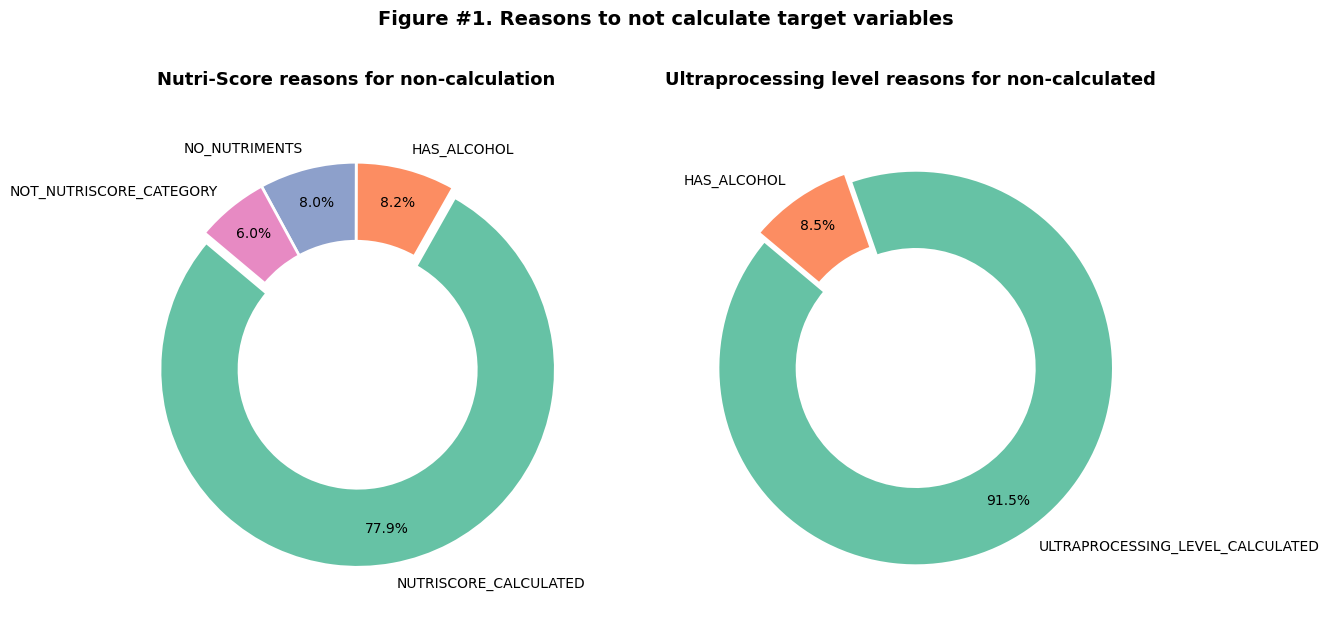

In [29]:
nutri_counts = prepare_status_counts(
    df_unique_product_catalogue, 
    score_col='nutriscore', 
    reason_col='can_nutriscore_be_calculated',
    calculated_label='NUTRISCORE_CALCULATED'
)

ultraprocessing_level_counts = prepare_status_counts(
    df_unique_product_catalogue,
    score_col='ewo_ultra_processed_punctuation',
    reason_col='can_ewo_be_calculated',
    calculated_label='ULTRAPROCESSING_LEVEL_CALCULATED'
)

# planet_score_level_counts = prepare_status_counts(
#     df_unique_product_catalogue,
#     score_col='planetscore',
#     reason_col='can_planet_score_be_calculated', # s'ha de fer!
#     calculated_label='PLANET_SCORE_CALCULATED'
# )

fig, ax = plt.subplots(1, 2, figsize=(14,6))
#fig, ax = plt.subplots(1, 3, figsize=(14,6))

plot_status_donut_piechart(
    nutri_counts, 
    title="Nutri-Score reasons for non-calculation", 
    calculated_label='NUTRISCORE_CALCULATED',
    ax = ax[0]
)

plot_status_donut_piechart(
    ultraprocessing_level_counts,
    title='Ultraprocessing level reasons for non-calculated',
    calculated_label='ULTRAPROCESSING_LEVEL_CALCULATED',
    ax=ax[1]
)

# plot_status_donut_piechart(
#     ultraprocessing_level_counts,
#     title='Planet-Score reasons for non-calculated',
#     calculated_label='PLANET_SCORE_CALCULATED',
#     ax=ax[2]
# )

fig.suptitle(
    "Figure #1. Reasons to not calculate target variables",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()
plt.show()

TODO: Quan estigui tot complet, escriure aqui una miqueta el que indica la taula i els gràfics.

## 3.2. General description of dataset

### 3.2.1. Distribution of products per week and municipality

In this section, the data shown answers the product assortment of pairs category and subcategory scraped of online grocery globally in terms of time but distinguishing by locality. This table is interesting because the data obtained is from the **homepage**. Also, it demonstrates whether there are differences between Barcelona and Montferri in terms of the visibility of the categories and subcategories.

In [30]:
def calculate_visibility_distribution_of_products_per_week_and_municipality(df: pd.DataFrame) -> Styler:
    """
    Function that generates a DataFrame with the weekly mean of each category and subcategory and displays
    if there are significant differences between the two localities.

    Args:
        df (pd.DataFrame): DataFrame with product data.

    Returns:
        Styler: DataFrame with mean calculated globally and by locations colored.    
    """

    weekly_mun = (
        df.groupby(
            ['category', 'subcategory', 'postal_code', 'week_num'],
            observed=False,
        )['id_product']
        .count()
        .reset_index(name='n_items')
    )
    
    stats_mun = (
        weekly_mun.groupby(
            ['category', 'subcategory', 'postal_code'], observed=False
        )['n_items']
        .agg(mean='mean', std=lambda x: x.std() if len(x) > 1 else 0.0)
        .reset_index()
    )
    
    stats_mun['mean_sd'] = stats_mun.apply(lambda r: f"{r['mean']:.1f} (±{r['std']:.2f})", axis=1)
    
    pivot_mun_str = stats_mun.pivot(
        index=['category', 'subcategory'],
        columns='postal_code',
        values='mean_sd'
    ).reset_index()
    
    pivot_mun_raw = stats_mun.pivot(
        index=['category', 'subcategory'],
        columns='postal_code',
        values='mean'
    ).reset_index()
    
    pivot_mun_raw.rename(
        columns={'08032': '_can_baro_raw', '43812': '_montferri_raw'},
        inplace=True
    )
    
    weekly_global = (
        df.groupby(['category', 'subcategory', 'week_num'], observed=False)
        ['id_product']
        .count()
        .reset_index(name='n_items_global')
    )
    
    stats_global = (
        weekly_global.groupby(['category', 'subcategory'], observed=False)
        ['n_items_global']
        .mean()
        .reset_index(name='Weekly Mean (Global)')
    )

    summary = pd.merge(
        stats_global, pivot_mun_str, on=['category', 'subcategory'], how='left'
    )
    summary = pd.merge(
        summary, pivot_mun_raw, on=['category', 'subcategory'], how='left'
    )
    
    summary.rename(
        columns={
        '08032': 'Can Baró (Weekly Mean±SD)',
        '43812': 'Montferri (Weekly Mean±SD)',
        },
        inplace=True
    )
    
    summary.sort_values(by='Weekly Mean (Global)', ascending=False, inplace=True)
    summary.reset_index(drop=True, inplace=True)
    summary = summary.head(15)

    can_baro_raw = summary['_can_baro_raw']
    montferri_raw = summary['_montferri_raw']
    
    summary.drop(columns=['_can_baro_raw', '_montferri_raw'], inplace=True)
    
    styler = summary.style
    styler = styler.format({'Weekly Mean (Global)': '{:.1f}'})
    styler = styler.background_gradient(
        subset=['Weekly Mean (Global)'], cmap=COLORS
    )
    
    styler = styler.background_gradient(
        subset=['Can Baró (Weekly Mean±SD)'], gmap=can_baro_raw, cmap=COLORS
    )
    
    styler = styler.background_gradient(
        subset=['Montferri (Weekly Mean±SD)'], gmap=montferri_raw, cmap=COLORS
    )
    
    return styler

In [31]:
visibility_summary = calculate_visibility_distribution_of_products_per_week_and_municipality(df_products)

print("Table #13. Weekly average product assortment volume by category and subcategory, globally and stratified by location (Mean ± SD)")
visibility_summary

Table #13. Weekly average product assortment volume by category and subcategory, globally and stratified by location (Mean ± SD)


,category,subcategory,Weekly Mean (Global),Can Baró (Weekly Mean±SD),Montferri (Weekly Mean±SD)
0,"Sugar, sweets & chocolate",Sweets,46.2,23.2 (±11.86),23.0 (±12.35)
1,"Sugar, sweets & chocolate",Chocolate,35.8,17.8 (±3.77),18.0 (±5.05)
2,"Beer, wine & spirits",Beer,20.8,10.8 (±2.28),10.0 (±2.00)
3,"Sugar, sweets & chocolate",Nougats,19.4,10.4 (±7.60),9.0 (±8.92)
4,"Beer, wine & spirits",Spirits,15.6,7.8 (±0.84),7.8 (±0.84)
5,Snacks,"Nuts, seeds & dried fruit",15.2,7.6 (±2.97),7.6 (±2.97)
6,Cereals & biscuits,Biscuits,15.2,7.4 (±1.14),7.8 (±0.84)
7,Fruit & vegetables,Vegetables,13.4,7.2 (±2.86),6.2 (±2.86)
8,Water & soft drinks,Isotonic and energy drinks,13.2,6.6 (±5.32),6.6 (±5.32)
9,Seafood & fish,Fresh fish,12.6,6.4 (±3.21),6.2 (±3.35)


TODO: Treure una conclusió quan tingui ja totes les dades.

### 3.2.2. Promotion information of the products sample

In [32]:
color_map_type_discounts = {
    'no_promotion': '#bdc3c7',
    'price_discount': '#e74c3c',
    'volume_pack': '#3498db',
    'discounted_pack': '#9b59b6'
}

In [33]:
def generate_promotion_information_by_basic_information(df: pd.DataFrame) -> pd.DataFrame:
    """
    Function to generate promotion information by variables previous_pvp, pvp,
    total_units and is_pack.

    Args:
        df (pd.DataFrame): DataFrame of products.

    Returns:
        pd.DataFrame: An updated DataFrame with new columns.
    """

    df['has_price_discount'] = (
        df['previous_pvp'].notna() & 
        (df['previous_pvp'] > df['pvp'])
    )
    
    df['percentage_discount'] = np.where(
        df['has_price_discount'],
        (((df['previous_pvp'] - df['pvp']) / df['previous_pvp']) * 100).round(2),
        0.0
    )
    
    conditions_pack = [
        (df['total_units'] <= 1) | (df['total_units'].isna()),
        (df['total_units'] == 2),
        (df['total_units'] >= 3)
    ]
    choices_pack = ['single_unit', 'double_pack', 'multiple_pack']
    
    df['pack_format'] = np.select(conditions_pack, choices_pack, default='single_unit')
    
    conditions_promo = [
        (df['has_price_discount'] == True) & (df['is_pack'] == True),
        (df['has_price_discount'] == True) & (df['is_pack'] == False),
        (df['has_price_discount'] == False) & (df['is_pack'] == True),
        (df['has_price_discount'] == False) & (df['is_pack'] == False)
    ]
    choices_promo = [
        'discounted_pack',
        'price_discount',
        'volume_pack',
        'no_promotion'
    ]
    
    df['promotion_type'] = np.select(conditions_promo, choices_promo, default='no_promotion')
    df['is_promoted'] = df['promotion_type'] != 'no_promotion'

    return df

In [34]:
df_products = generate_promotion_information_by_basic_information(df_products)

In the code block cell above, different types of promotion are calculated using the basic variables given, which are `is_pack`, `total_units`, `pvp`, and `previous_pvp`. With those variables, it calculates:
* `has_price_discount`: This variable has a value of $True$ only if a product contains `previous_pvp` informed. If not, it contains $False$.
* `percentage_discount`: This variable contains the percentage of discount done following the formula: $\frac{previouspvp - pvp}{pvp}*100$. It only applies if `has_percentage_discount` is $True$. Otherwise, it has a value of $0$.
* `pack_format`: Discretises the variable `total_units` with three posibilities: *single_unit*, *double_pack*, and *multiple_pack*.
* `promotion_type`: By using the variables already explained, this is the most interesting variable about promotions. This can have different values:
    * *discounted_pack*: When a product has a price discount and is a pack, both variables are $True$.
    * *price_discount*: When a product has a price discount ($True$) and is not a pack ($False$).
    * *volume_pack*: When a product doesn't have a price discount ($False$), but is a pack ($True$).
    * *no_promotion*: When a product doesn't have a price discount and doesn't is a pack, both variables are $False$.
* `is_promoted`: Global variable whether is $True$ when `promotion_type` is not $nopromotion$.

With this information, we can calculate total food products scraped and information about promotions.

In [35]:
def calculate_information_per_week_postal_code_and_categories_subcategories_promotion_and_coverage_food_products(
    df_products: pd.DataFrame,
    df_aggregation: pd.DataFrame
) -> pd.DataFrame:
    """
    Function that generates a DataFrame context joining the aggregates DataFrame and products Dataframe to
    display total products scraped, items promoted, % of items coverage and % of items promoted for each
    week, postal code, category and subcategory.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        df_aggregation (pd.DataFrame): DataFrame with aggregated data (total items) for each category 
                                       and subcategory, week number and postal code.
    Returns:
        pd.DataFrame: DataFrame with the information.
    """
    df_prod_agg = (
        df_products.groupby(
            ['week_num', 'postal_code', 'category_norm', 'subcategory_norm'], observed=True
        )
        .agg(
            items_obtained_by_scraping=('id_product', 'nunique'),
            items_promoted=(
                'is_promoted',
                lambda x: (x == True).sum(),
            ),
        )
        .reset_index()
    )
    
    df_context = pd.merge(
        df_aggregation,
        df_prod_agg,
        on=['week_num', 'postal_code', "category_norm", 'subcategory_norm'],
        how='left',
    )
    
    df_context['items_obtained_by_scraping'] = df_context['items_obtained_by_scraping'].fillna(0).astype(int)
    df_context['items_promoted'] = (
        df_context['items_promoted'].fillna(0).astype(int)
    )
    
    df_context['% products obtained from homepage'] = np.where(
        df_context['total_items'] > 0,
        (df_context['items_obtained_by_scraping'] / df_context['total_items']) * 100,
        0
    ).round(2)
    
    df_context['% products under promotion'] = np.where(
        df_context['items_obtained_by_scraping'] > 0,
        (df_context['items_promoted'] / df_context['items_obtained_by_scraping']) * 100,
        0,
    ).round(2)
    
    columns_order = ['week_num', 'postal_code', 'category', 'subcategory', 'items_obtained_by_scraping', 'total_items', 'items_promoted', '% products obtained from homepage', '% products under promotion']
    
    final_cols = [col for col in columns_order if col in df_context.columns]
    df_context_summary = df_context[final_cols]
    
    df_context_summary.sort_values('items_obtained_by_scraping', ascending=False)

    return df_context_summary

In [36]:
df_context_summary = calculate_information_per_week_postal_code_and_categories_subcategories_promotion_and_coverage_food_products(
    df_products,
    df_aggregation
)

print("Table #14. Weekly scraping coverage and promotional prevalence by postal code and category")
df_context_summary

Table #14. Weekly scraping coverage and promotional prevalence by postal code and category


,week_num,postal_code,category,subcategory,items_obtained_by_scraping,total_items,items_promoted,% products obtained from homepage,% products under promotion
0,40,43812,"Oil, spices & sauces","Oil, vinegar & salt",10,37,10,27.03,100.0
1,40,43812,"Oil, spices & sauces",Spices,0,49,0,0.00,0.0
2,40,43812,"Oil, spices & sauces","Mayonnaise, ketchup & mustard",2,19,2,10.53,100.0
3,40,43812,"Oil, spices & sauces",Other sauces,2,39,0,5.13,0.0
4,40,43812,Water & soft drinks,Water,0,49,0,0.00,0.0
...,...,...,...,...,...,...,...,...,...
1074,44,08032,Desserts & yoghurt,Children's yoghurt & dessert,0,7,0,0.00,0.0
1075,44,08032,Juices,Assorted fruit,1,28,1,3.57,100.0
1076,44,08032,Juices,Peach & pineapple,1,10,1,10.00,100.0
1077,44,08032,Juices,Orange,1,12,1,8.33,100.0


TODO: Quan tingui totes les dades, extreure'n conclusions d'aquí, taula la qual dona informació agregada per setmana, codi postal, categoria, subcategoria, el total de productes obtinguts via scraping, el total d'items en la categoria i subcategoria, els promocionats, el %coverage es % entre els productes obtinguts i els que hi ha en total, i el % de productes sota alguna promoció.

In [37]:
def plot_promotion_data_donut_piechart(df: pd.DataFrame, color_map: dict = color_map_type_discounts) -> None:
    """
    Function that prints a donut piechart with the different types of promotions
    and the percentages of each.

    Args:
        df (pd.DataFrame): DataFrame of the data.
        color_map (dict): Colors of discounts type.

    Returns:
        None. It only prints out the graphic.
    """

    counts = df['promotion_type'].value_counts()
    
    colors = [color_map[x] for x in counts.index]
    explode = [0.05 for x in counts.index]
    
    fig, ax = plt.subplots(figsize=(8, 6))
    wedges, texts, autotexts = ax.pie(
        counts.values,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.8,
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
    )
    
    plt.setp(autotexts, size=10, weight="bold")
    ax.set_title("Figure #2. Distribution of promoted products vs no promotion", fontsize=13, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

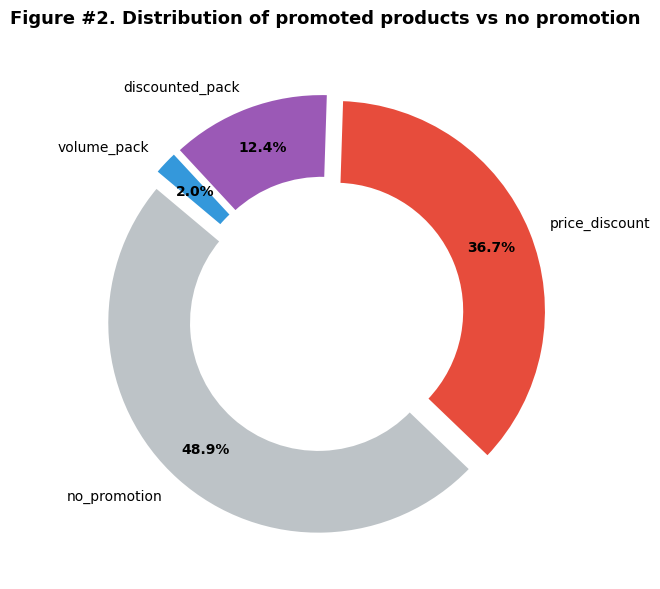

In [38]:
plot_promotion_data_donut_piechart(df_products)

TODO: Quan tingui totes les dades, llavors fer l'explicació que toqui.

In [39]:
def plot_promotion_by_category_stacked(df: pd.DataFrame, color_map: dict = color_map_type_discounts) -> None:
    """
    Function that generates an horizontal bar char showing each category and the percentage distribution
    of type of discount for each category.

    Args:
        df (pd.DataFrame): DataFrame of products data.
        color_map (dict): Color map of the discounts type.

    Returns:
        None. Prints out the graphic.
    """

    ct = pd.crosstab(df['category'], df['promotion_type'], normalize='index') * 100
    desired_order = ['no_promotion', 'price_discount', 'volume_pack', 'discounted_pack']
    cols = [c for c in desired_order if c in ct.columns]
    ct = ct[cols]
    ct = ct.sort_values(by='no_promotion', ascending=True)

    colors = [color_map[c] for c in ct.columns]
    
    fig, ax = plt.subplots(figsize=(11, 7))
    ct.plot(kind='barh', stacked=True, color=colors, ax=ax, width=0.7)

    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        if width > 5:
            x, y = p.get_xy() 
            ax.text(x + width/2, y + height/2, f"{width:.1f}%", 
                    ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
            
    ax.set_title("Figure #3. Tipology of promotions for each category", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Percentage of products (%)", fontsize=11)
    ax.legend(title="Promotion type", bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

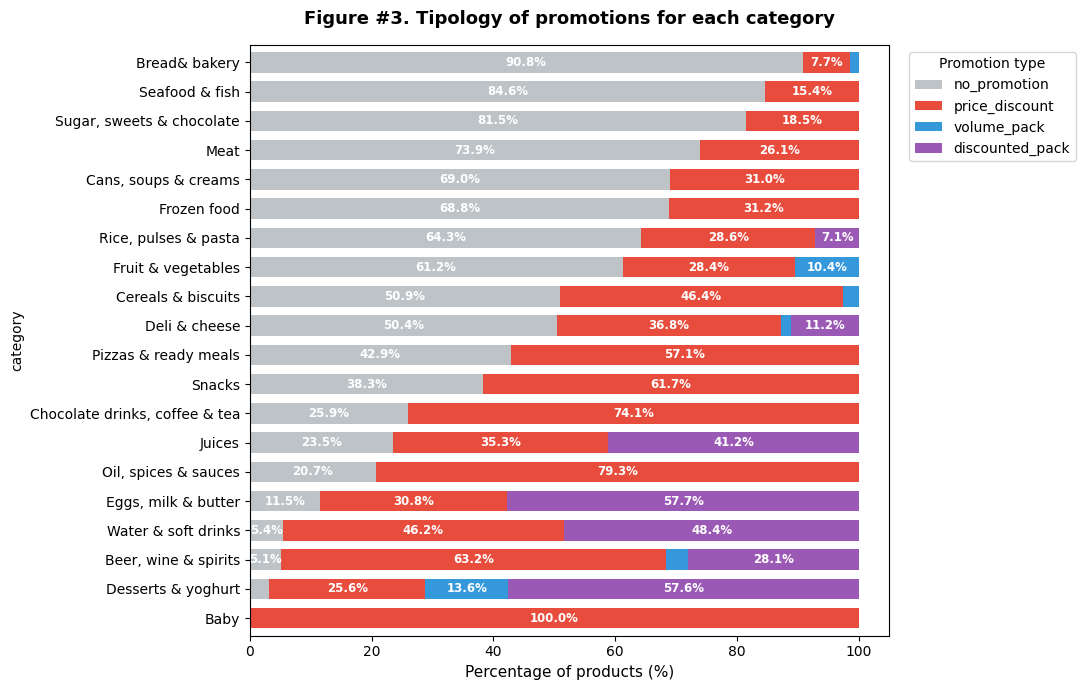

In [40]:
plot_promotion_by_category_stacked(df_products)

TODO: Quan tingui totes les dades, llavors fer l'explicació que toqui.

In [41]:
def plot_promotion_by_category_and_subcategory(df: pd.DataFrame, color_map: dict = color_map_type_discounts) -> None:
    """
    Function that generates horizontal bar plot for promotion types by category and each subcategory.

    Args:
        df (pd.DataFrame): Dataframe of products.
        color_map (dict): Dictionary with colours.

    Returns:
        None. Prints out the graphic.
    """
    
    ct_sub = pd.crosstab([df['category'], df['subcategory']], df['promotion_type'], normalize='index') * 100
    ct_cat = pd.crosstab(df['category'], df['promotion_type'], normalize='index') * 100

    ct_sub = ct_sub.dropna(how='all')
    ct_cat = ct_cat.dropna(how='all')

    desired_order = ['no_promotion', 'price_discount', 'volume_pack', 'discounted_pack']
    cols = [c for c in desired_order if c in ct_cat.columns]

    if 'no_promotion' in ct_cat.columns:
        cat_order = ct_cat['no_promotion'].sort_values(ascending=False).index
    else:
        cat_order = ct_cat.index

    colors = [color_map[c] for c in cols]

    y_positions = []
    y_labels = []
    bar_heights = []
    is_main_list = []
    data_rows = []

    current_y = 0
    cat_separator_positions = []

    for i, cat in enumerate(reversed(cat_order)):
        if cat in ct_sub.index.get_level_values(0):
            sub_data = ct_sub.loc[cat]
            for subcat in reversed(sub_data.index):
                data_rows.append(sub_data.loc[subcat, cols].values)
                y_positions.append(current_y)
                y_labels.append(f"{subcat}")
                bar_heights.append(0.38) 
                is_main_list.append(False)
                current_y += 1.0

        if cat in ct_cat.index:
            data_rows.append(ct_cat.loc[cat, cols].values)
            y_positions.append(current_y)
            y_labels.append(str(cat).upper())
            bar_heights.append(0.65)
            is_main_list.append(True)
            current_y += 1.2

        if i < len(cat_order) - 1:
            cat_separator_positions.append(current_y + 0.3)
            current_y += 0.8

    if len(y_positions) == 0:
        print("No hi ha dades per mostrar.")
        return

    data_matrix = np.array(data_rows)

    fig_height = max(6, len(y_positions) * 0.45)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    lefts = np.zeros(len(y_positions))
    for col_idx, col_name in enumerate(cols):
        widths = data_matrix[:, col_idx]
        bars = ax.barh(
            y_positions, 
            widths, 
            left=lefts, 
            height=bar_heights, 
            color=colors[col_idx], 
            label=col_name,
            edgecolor='white',
            linewidth=0.8
        )

        for idx, (bar, width) in enumerate(zip(bars, widths)):
            if not np.isnan(width) and width > 5.5:
                y_pos = bar.get_y() + bar.get_height() / 2
                x_pos = lefts[idx] + width / 2
                font_weight = 'bold' if is_main_list[idx] else 'normal'
                font_size = 8.5 if is_main_list[idx] else 7.5
                ax.text(
                    x_pos, y_pos, f"{width:.1f}%", 
                    ha='center', va='center', color='white', 
                    fontweight=font_weight, fontsize=font_size
                )
        lefts += widths

    for sep_y in cat_separator_positions:
        ax.axhline(y=sep_y, color='#dcdde1', linestyle='--', linewidth=0.9)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels, fontsize=9)

    for tick_label, is_main in zip(ax.get_yticklabels(), is_main_list):
        if is_main:
            tick_label.set_fontweight('bold')
            tick_label.set_fontsize(10)

    ax.set_ylim(min(y_positions) - 0.8, max(y_positions) + 0.8)
    ax.set_title("Figure #4. Tipology of promotions by food category and subcategory", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Product percentage (%)", fontsize=11)
    ax.set_xlim(0, 100)
    ax.legend(title="Promotion type", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

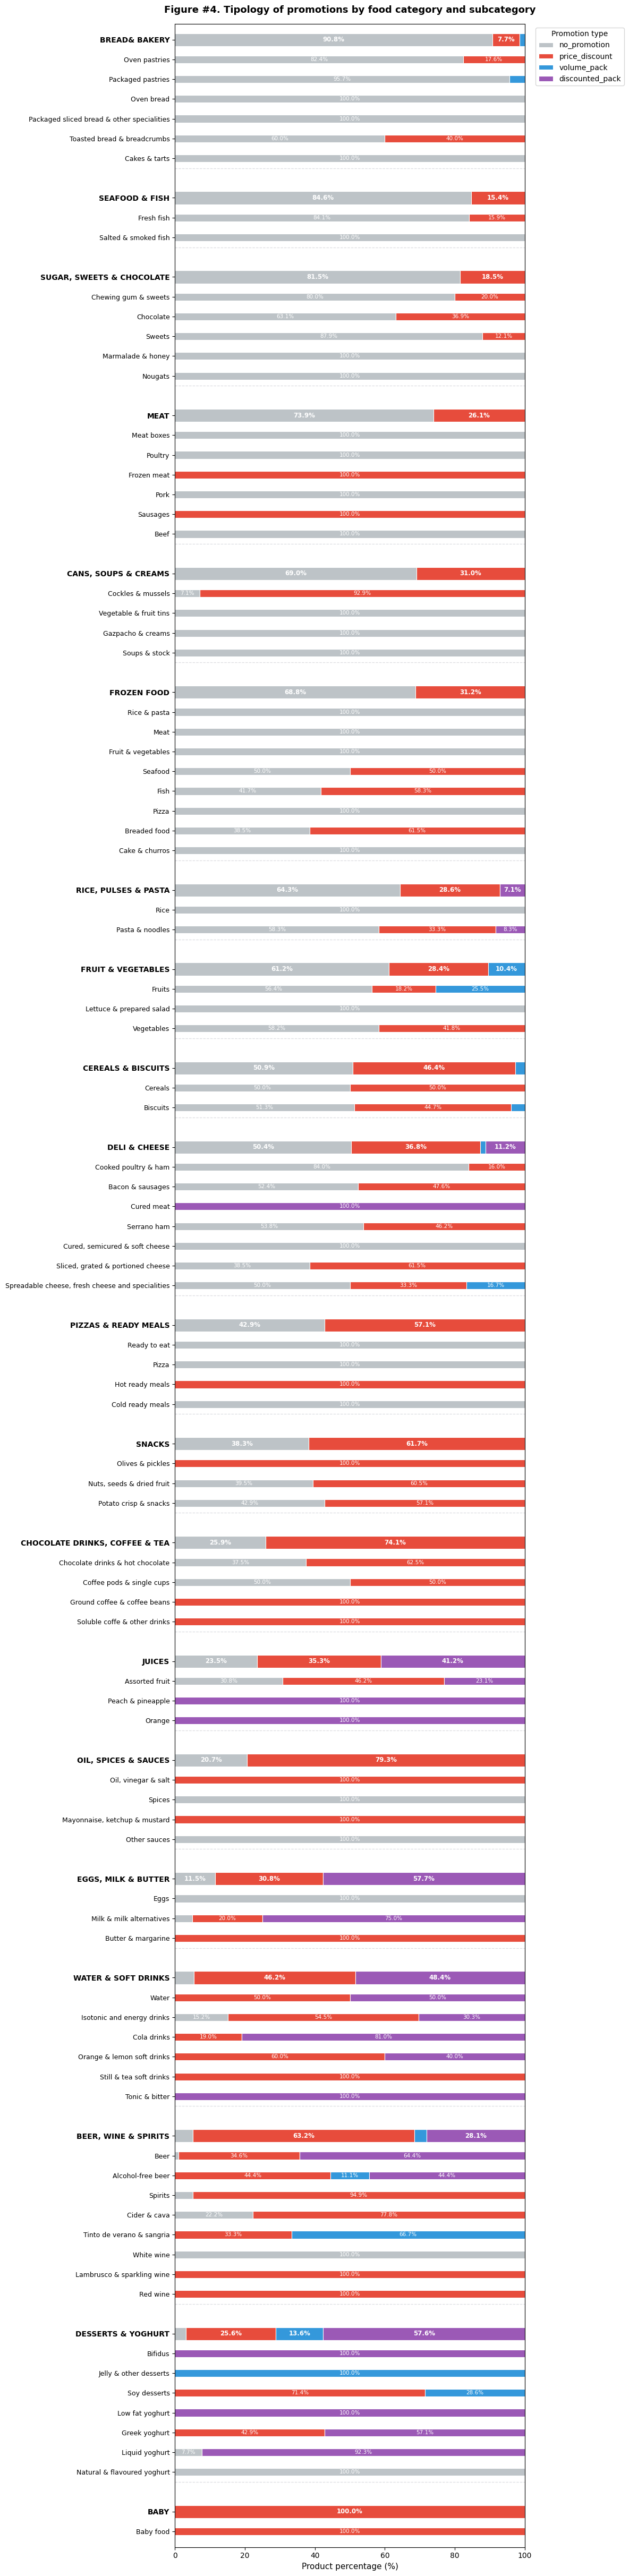

In [42]:
plot_promotion_by_category_and_subcategory(df_products)

TODO: Quan tingui totes les dades, llavors fer l'explicació que toqui.

In [43]:
def get_mean_confidence_interval(series: pd.core.series.Series, cl: float = CL) -> str:
    """
    Function that calculates a confidence interval for a mean (continuous variable).
    To do this, it applies the Standard Error of the Mean and Student t with n-1
    degrees of freedom over the mean. By using theory, a test over the mean
    with population desviation unknown, it uses the statistical test Student t with n-1
    degrees of freedom.

    Args:
        series (pd.core.series.Series): List of the data.
        cl (float): Confidence level.

    Returns:
        str: String with the data.
    """
    s = series.dropna()
    n = len(s)

    if n < 1:
        return 'N/A'
    if n == 1:
        mean = s.iloc[0]
        return f'{mean:.2f}% [N/A]'
    
    mean = np.mean(s)
    sem = stats.sem(s)

    if sem == 0 or np.isnan(sem):
        return f'{mean:.2f}% [{mean:.2f}%, {mean:.2f}%]'

    ci_lower, ci_upper = stats.t.interval(cl, df=n - 1, loc=mean, scale=sem)

    if np.isnan(ci_lower) or np.isnan(ci_upper):
        return f'{mean:.2f}% [{mean:.2f}%, {mean:.2f}%]'

    return f'{mean:.2f}% [{ci_lower:.2f}%, {ci_upper:.2f}%]'

def verify_clt_for_proportions(series: pd.core.series.Series) -> bool:
    """
    Function to check if for the data applies the Central Limit Theory for proportions.

    Args:
        series (pd.core.series.Series): List of the data.

    Returns:
        bool: True if CLT is applied, False no.
    """

    n = len(series)
    successes = np.sum(series)
    failures = n - successes

    if successes <= 5 or failures <= 5:
        return False

    return True


def get_proportion_confidence_interval(series: pd.core.series.Series, cl: float = CL) -> str:
    """
    Confidence interval for a proportion or percentage (binary variable). According to the
    theory of the probability, if the size of a sample is sufficently big, the variable
    follows a normal distribution. So, this function checks this and executes this theory.

    Args:
        series (pd.core.series.Series): Data to be avaluated.
        cl (float): Confidence level.

    Returns:
        str: Data calculated.
    """
    s = series.dropna()
    n = len(s)
    if n == 0:
        return "N/A"
    
    p = np.mean(s)
    pct = p * 100
    clt_is_applied = verify_clt_for_proportions(s)

    if not clt_is_applied:
        if p == 0.0:
            return '0.0% [0.0%, 0.0%]'
        if p == 1.0:
            return '100.0% [100.0%, 100.0%]'
        return f'{pct:.1f}% [Insufficient size]'
    
    se = np.sqrt((p * (1 - p)) / n)
    ci_lower, ci_upper = stats.norm.interval(cl, loc=p, scale=se)
    ci_l = max(0.0, ci_lower * 100)
    ci_u = min(100.0, ci_upper * 100)

    return f'{pct:.1f}% [{ci_l:.1f}%, {ci_u:.1f}%]'

def calculate_promotion_proportions(series_promo: pd.core.series.Series, cl: float = CL) -> tuple:
    """
    Function that calculates the percentage and the margin of errors with the interval of confidence of 95%
    of proportions by using the CLT criteria to apply CI over proportion, using the theory of probability.

    Args:
        series_promo (pd.core.series.Series): Data under promotion.
        cl (float): Confidence level.

    Returns:
        tuple: percentage, error_low, error_high
    """
    s = series_promo.dropna()
    n = len(s)
    if n == 0:
        return 0.0, 0.0, 0.0
    p = np.mean(s)
    pct = p * 100

    clt_is_applied = verify_clt_for_proportions(s)

    if not clt_is_applied:
        return pct, 0.0, 0.0
    
    se = np.sqrt(p * (1 - p) / n)
    ci_l, ci_u = stats.norm.interval(cl, loc=p, scale=se)
    ci_l = max(0.0, ci_l)
    ci_u = min(1.0, ci_u)
    
    err_low = (p - ci_l) * 100
    err_high = (ci_u - p) * 100

    return pct, err_low, err_high


def calculate_table_to_retireve_confidence_intervals_for_products_discounted_and_packs(
    df_products: pd.DataFrame,
    df_aggregation: pd.DataFrame
) -> Styler:
    """
    Function to calculate table to retrieve information about discounts per price and packs information, each one with
    confidence interval of 95%.

    Args:
        df_products (pd.DataFrame): Dataframe with product information.

    Return:
        Styler: DataFrame with data and colored.
    """

    items_table = []
    for (cat_norm, subcat_norm), group in df_products.groupby(['category_norm', 'subcategory_norm'], observed=True):
        cat_display = group['category'].iloc[0]
        subcat_display = group['subcategory'].iloc[0]
        
        total_n = df_aggregation[
            (df_aggregation['category_norm'] == cat_norm) &
            (df_aggregation['subcategory_norm'] == subcat_norm)
        ]['total_items'].sum()
        
        homepage_n = group['title_category_main_page'].notna().sum()
        
        disc_series = group['has_price_discount']
        disc_prop_str = get_proportion_confidence_interval(disc_series)
        disc_pct_raw = (
            disc_series.dropna().mean() * 100 if len(disc_series.dropna()) > 0 else 0.0
        )
        
        disc_products = group[group['has_price_discount'] == True]['percentage_discount']
        disc_mag_str = (
            get_mean_confidence_interval(disc_products)
            if len(disc_products) > 0
            else '0.00%'
        )
        disc_mag_raw = (
            disc_products.dropna().mean()
            if len(disc_products.dropna()) > 0
            else 0.0
        )
        
        packs_prop_str = get_proportion_confidence_interval(group['is_pack'])
        
        pack_units = group[group['is_pack'] == True]['total_units'].dropna()
        if len(pack_units) > 1 and pack_units.std() is not np.nan:
            units_mean_sd = f'{pack_units.mean():.2f} (SD: {pack_units.std():.2f})'
        elif len(pack_units) == 1:
            units_mean_sd = f'{pack_units.mean():.2f} (SD: 0.00)'
        else:
            units_mean_sd = 'N/A'
        
        items_table.append({
            'Category': cat_display,
            'Subcategory': subcat_display,
            'Homepage (n)': homepage_n,
            'Total (n)': total_n,
            'Products Discounted (%; 95% CI)': disc_prop_str,
            'Magnitude of Discount (% Change; 95% CI)': disc_mag_str,
            'Products on packs (%; 95% CI)': packs_prop_str,
            'Units in packs (Mean; SD)': units_mean_sd,
            '_disc_pct_raw': disc_pct_raw,
            '_disc_mag_raw': disc_mag_raw,
        })
    
    table_results_df = pd.DataFrame(items_table)
    
    disc_raw = table_results_df['_disc_pct_raw']
    mag_raw = table_results_df['_disc_mag_raw']
    
    table_results_df = table_results_df.drop(
        columns=['_disc_pct_raw', '_disc_mag_raw']
    )
    
    styler = table_results_df.style
    styler = styler.background_gradient(
    subset=['Products Discounted (%; 95% CI)'], gmap=disc_raw, cmap=COLORS)
    styler = styler.background_gradient(subset=['Magnitude of Discount (% Change; 95% CI)'],gmap=mag_raw,cmap=COLORS)
    
    return styler

In [44]:
table_results_df = calculate_table_to_retireve_confidence_intervals_for_products_discounted_and_packs(df_products, df_aggregation)

print("Table #15. Online grocery choice architecture and promotional strategies:\
 Homepage visibility, Price discount prevalence, and pack offerings by product category")
table_results_df

Table #15. Online grocery choice architecture and promotional strategies: Homepage visibility, Price discount prevalence, and pack offerings by product category


,Category,Subcategory,Homepage (n),Total (n),Products Discounted (%; 95% CI),Magnitude of Discount (% Change; 95% CI),Products on packs (%; 95% CI),Units in packs (Mean; SD)
0,"Oil, spices & sauces","Oil, vinegar & salt",38,378,"100.0% [100.0%, 100.0%]","3.68% [3.28%, 4.09%]","0.0% [0.0%, 0.0%]",N/A
1,"Oil, spices & sauces",Spices,4,496,"0.0% [0.0%, 0.0%]",0.00%,"0.0% [0.0%, 0.0%]",N/A
2,"Oil, spices & sauces","Mayonnaise, ketchup & mustard",8,190,"100.0% [100.0%, 100.0%]","17.54% [13.74%, 21.35%]","0.0% [0.0%, 0.0%]",N/A
3,"Oil, spices & sauces",Other sauces,8,385,"0.0% [0.0%, 0.0%]",0.00%,"0.0% [0.0%, 0.0%]",N/A
4,Water & soft drinks,Water,8,498,"100.0% [100.0%, 100.0%]","8.00% [8.00%, 8.00%]",50.0% [Insufficient size],6.00 (SD: 0.00)
5,Water & soft drinks,Isotonic and energy drinks,66,382,"84.8% [76.2%, 93.5%]","16.22% [14.95%, 17.49%]","30.3% [19.2%, 41.4%]",5.20 (SD: 1.88)
6,Water & soft drinks,Cola drinks,42,400,"100.0% [100.0%, 100.0%]","8.04% [7.49%, 8.59%]","81.0% [69.1%, 92.8%]",6.35 (SD: 4.77)
7,Water & soft drinks,Orange & lemon soft drinks,50,340,"100.0% [100.0%, 100.0%]","17.83% [15.24%, 20.42%]","40.0% [26.4%, 53.6%]",7.20 (SD: 2.71)
8,Water & soft drinks,Still & tea soft drinks,8,313,"100.0% [100.0%, 100.0%]","23.02% [19.74%, 26.29%]","0.0% [0.0%, 0.0%]",N/A
9,Water & soft drinks,Tonic & bitter,12,110,"100.0% [100.0%, 100.0%]","27.08% [27.08%, 27.08%]","100.0% [100.0%, 100.0%]",8.00 (SD: 0.00)


Before continue the exploratory data analysis, it is important to add some statistical theory for two functions used in this table:

**Explanation of how the function *get_mean_confidence_interval* works**

In this case, we do not know the population deviation, and therefore, the contrast statistic used to calculate the confidence interval is Student's *t* with $n - 1$ degrees of freedom.

$$
t=\frac{\bar{x}-\mu_0}{\frac{s}{\sqrt{n}}} \sim t_{n-1}
$$

This is why, to calculate the confidence intervals for the mean, the *get_mean_confidence_interval* function is used, which internally applies *stats.t.interval* with a 95% confidence level for the mean, using the SEM as the scale, which is the denominator of Student's *t*.

**Explanation of how the function *get_proportion_confidence_interval* works**

The confidence interval for the proportion, according to probability theory, states that if the sample size is sufficiently large, the variable follows a standard normal distribution:

$$
z=\frac{\hat{p}-p}{\sqrt{\frac{p(1-p)}{n}}} \sim  N(0,1)
$$

And the standard error, follows the formula:

$$
SE = \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

Then, the function also checks and validates, in accordance with the Central Limit Theorem, whether the sample is sufficiently large, according to statistical theory, which states: "Let $X$ be a random variable with a binomial distribution of parameters *n* and *p*. If *n* is large, then the distribution is approximately normal with mean $\mu=np$ and variance $\sigma^2=np(1-p)$. In practice, this approximation is commonly used when both $np$ and $n(1-p)$ are greater than $5$.

Once this has been detected, then the normal approximation is or is not used to calculate the confidence intervals.

TODO: treure conclusions quan tingui totes les dades.

#### 3.2.2.1. Promotion types and target variables

In [45]:
def plot_promoted_percentage_by_score(df: pd.DataFrame) -> None:
    """
    Function that generates graphic with confidence interval of 95% of the
    different target variables.

    Args:
        df (pd.DataFrame): DataFrame with product data.

    Returns:
        None. It prints out the graphic.
    """

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    configs = [
        {'col': 'nutriscore', 'name': 'Nutri-Score', 'levels': ['A', 'B', 'C', 'D', 'E'], 'ax_idx': 0},
        {'col': 'ewo_ultra_processed_punctuation', 'name': 'Ewö', 'levels': [1.0, 2.0, 3.0, 4.0], 'ax_idx': 1},
        {'col': 'planetscore', 'name': 'Planet-Score', 'levels': ['A', 'B', 'C', 'D', 'E'], 'ax_idx': 2}
    ]
    
    for cfg in configs:
        ax = axes[cfg['ax_idx']]
        col = cfg['col']
        
        has_data = col in df.columns and df[col].notna().sum() > 0
        
        if not has_data:
            ax.text(0.5, 0.5, f"NO DATA YET\n({cfg['name'].upper()})", 
                    ha='center', va='center', fontsize=11, fontweight='bold', color='#7f8c8d')
            ax.set_title(f"% Promoted by {cfg['name']}", fontweight='bold', fontsize=12)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            continue
            
        pcts, errs_low, errs_high, x_labels = [], [], [], []
        for level in cfg['levels']:
            sub = df[df[col] == level]['is_promoted']
            pct, err_l, err_h = calculate_promotion_proportions(sub)
            pcts.append(pct)
            errs_low.append(err_l)
            errs_high.append(err_h)
            x_labels.append(str(level))
            
        x = np.arange(len(x_labels))
        
        bars = ax.bar(
            x, pcts, 
            yerr=[errs_low, errs_high], 
            capsize=4, 
            color='white', 
            edgecolor='black', 
            linewidth=1.2,
            error_kw=dict(ecolor='black', lw=1.2, capsize=4, capthick=1.2)
        )
        
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels)
        ax.set_ylabel('% Promoted', fontsize=11, fontweight='bold')
        ax.set_title(f"% Promoted by {cfg['name']}", fontweight='bold', fontsize=12, pad=15)
        
        max_y = max([p + e for p, e in zip(pcts, errs_high)]) if len(pcts) > 0 else 50
        ax.set_ylim(0, max(50, max_y + 12))
        
        for i, (p, e_h) in enumerate(zip(pcts, errs_high)):
            if p > 0:
                ax.text(i, p + e_h + 1.5, f"{int(round(p))}", ha='center', va='bottom', fontsize=10, fontweight='bold')
                
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)


    fig.suptitle(
    'Figure #5. Promotional prevalence across nutritional, processing, and environmental'
    ' quality indicators (95% CI)',
    fontsize=14,
    fontweight='bold',
    y=1.05,
    )
    plt.tight_layout()
    plt.show()

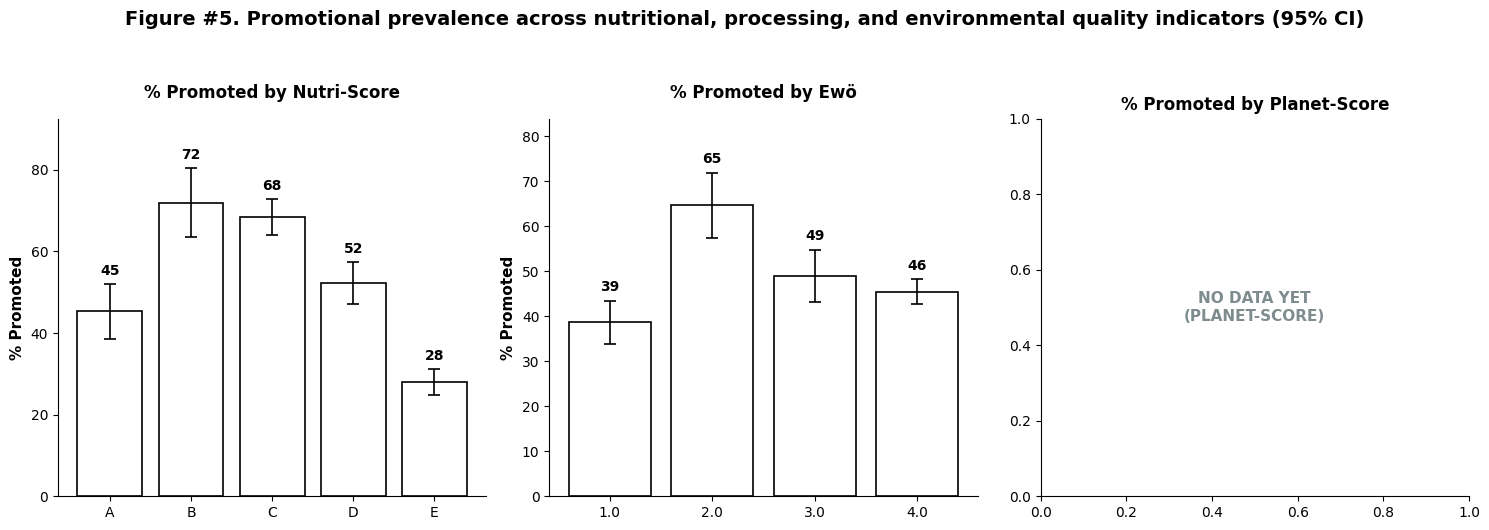

In [46]:
plot_promoted_percentage_by_score(df_products)

This graph shows the probability that a product is promoted given that it belongs to category A (or B, C, D, E) for the Nutri-Score, 1 (or 2, 3, 4) for the Ewö level of ultra-processing, and A (or B, C, D, E) for the Planet-Score.

**Theoretical reasoning for the function *calculate_promotion_proportions***

Since we are reviewing proportions, we find ourselves in the same position as in the previous case, so we apply the same theoretical concept as before.

$$
z=\frac{\hat{p}-p}{\sqrt{\frac{p(1-p)}{n}}} \sim  N(0,1)
$$

And the standard error follows the formula:

$$
SE = \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

In [47]:
def calculate_mean_discount_ci(series: pd.Series, cl: float = CL) -> tuple[float, float]:
  """
  Calculate the negative mean of the discount and its 95% confidence interval.

  Returns:
      tuple: negative mean and error margin with CI 95%.
  """

  clean_s = series.dropna()
  if len(clean_s) == 0:
    return 0.0, 0.0

  mean_val = clean_s.mean()
  mean_neg = -abs(mean_val)

  if len(clean_s) < 2:
    return mean_neg, 0.0

  sem = stats.sem(clean_s)
  ci_margin = sem * stats.t.ppf((1 + cl) / 2.0, df=len(clean_s) - 1)

  return mean_neg, ci_margin


def plot_discount_magnitude_by_score(df: pd.DataFrame) -> None:
    """
    Generate a composite plot of the average discount magnitude (%) for promoted products with 95% confidence intervals (inverted bars).
    
    Args:
       df (pd.DataFrame): DataFrame with the product data.
    
    Returns:
       None. Displays the figure.
    """
  
    df_discounted = df[
        (df['is_promoted'] == True) & (df['percentage_discount'].notna())
    ].copy()
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    configs = [
        {
            'col': 'nutriscore',
            'name': 'Nutri-Score',
            'levels': ['A', 'B', 'C', 'D', 'E'],
            'ax_idx': 0,
        },
        {
            'col': 'ewo_ultra_processed_punctuation',
            'name': 'Ewö',
            'levels': [1.0, 2.0, 3.0, 4.0],
            'ax_idx': 1,
        },
        {
            'col': 'planetscore',
            'name': 'Planet-Score',
            'levels': ['A', 'B', 'C', 'D', 'E'],
            'ax_idx': 2,
        },
    ]
    
    for cfg in configs:
        ax = axes[cfg['ax_idx']]
        col = cfg['col']
        
        has_data = col in df_discounted.columns and df_discounted[col].notna().sum() > 0
        
        if not has_data:
            ax.text(
                0.5,
                0.5,
                f"NO DATA YET\n({cfg['name'].upper()})",
                ha='center',
                va='center',
                fontsize=11,
                fontweight='bold',
                color='#7f8c8d',
            )
            ax.set_title(
                f"% Discounted by {cfg['name']}", fontweight='bold', fontsize=12
            )
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            continue
        
        means_neg, errs, x_labels = [], [], []
        for level in cfg['levels']:
            sub = df_discounted[df_discounted[col] == level]['percentage_discount']
            mean_neg, err = calculate_mean_discount_ci(sub)
            means_neg.append(mean_neg)
            errs.append(err)
            x_labels.append(
                str(int(level)) if isinstance(level, float) else str(level)
            )
        
        x = np.arange(len(x_labels))
        
        bars = ax.bar(
            x,
            means_neg,
            yerr=errs,
            capsize=4,
            color='white',
            edgecolor='black',
            linewidth=1.2,
            error_kw=dict(ecolor='black', lw=1.2, capsize=4, capthick=1.2),
        )
        
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels)
        ax.set_ylabel('% Discounted', fontsize=11, fontweight='bold')
        ax.set_title(
            f"% Discounted by {cfg['name']}",
            fontweight='bold',
            fontsize=12,
            pad=15,
        )
        

        ax.axhline(0, color='black', linewidth=1.2)

        min_y = (
            min([m - e for m, e in zip(means_neg, errs)])
            if len(means_neg) > 0
            else -35
        )
        ax.set_ylim(min(-35, min_y - 6), 2)
        
        for i, (m, e) in enumerate(zip(means_neg, errs)):
            if m < 0:
                ax.text(
                    i,
                    m - e - 1.5,
                    f'{int(round(m))}',
                    ha='center',
                    va='top',
                    fontsize=10,
                    fontweight='bold',
                )
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    fig.suptitle(
        'Figure #6. Mean percentage discount magnitude across nutritional,'
        ' processing, and environmental indicators (95% CI)',
        fontsize=14,
        fontweight='bold',
        y=1.05,
    )
    plt.tight_layout()
    plt.show()

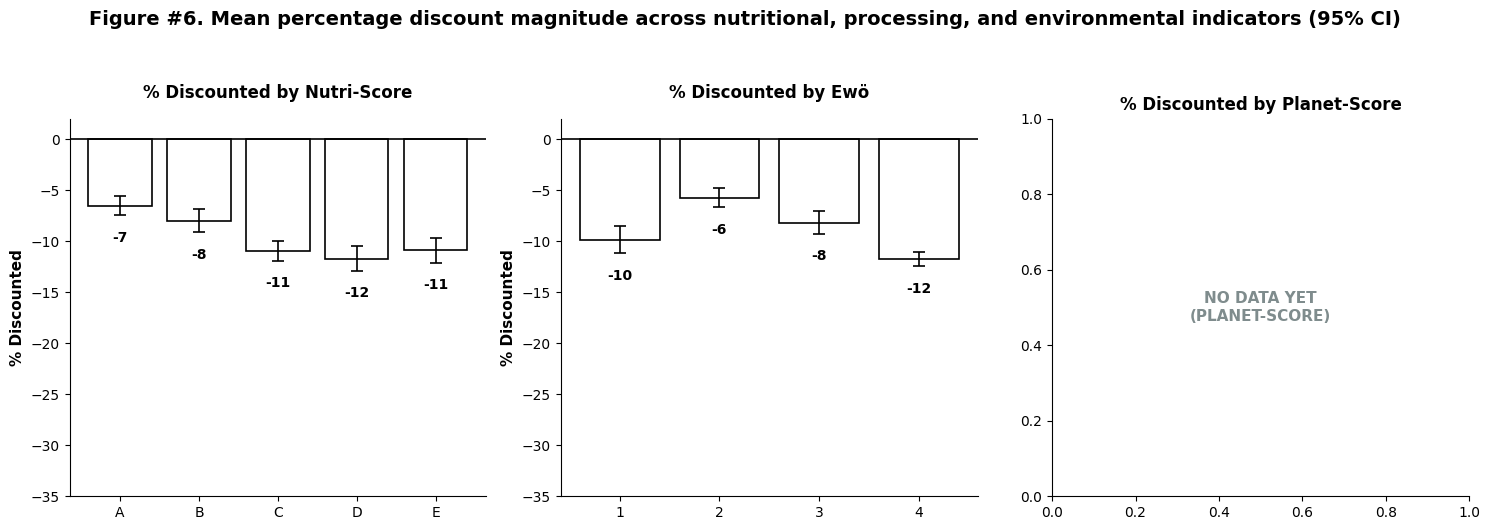

In [48]:
plot_discount_magnitude_by_score(df_products)

**Explanation statistical of *calculate_mean_discount_ci***

With the use of the function `stats.t.ppf` we retrieve the *Percent Point Function* of the Student's $t$ distribution. It returns quantiles, which is the reverse pf the accumulated distribution. It returns the critical value $t$ ($t^*$) which is necessary to calculate the error margin of an confidence interval.

* (1 + 0.95) / 2.0 = $0.975$: A $95\%$ two-tailed interval is constructed by splitting the remaining $5\%$ of error between the two tails ($2.5\%$ at the left tail and $2.5\%$ at the right tail). Therefore, you look for the theoretical point that accumulates the $97.5\%$ probability to its left ($95\% + 2.5\%$).
* df = len(clean_s) - 1: It represents the degree of freedom ($n-1$).
* stats.t.ppf(0.975, df): It returns the value $t^*$. By multiplying this multiplier $t^*$ by the Standard Error of the Mean (sem), you get the margin of error ($\pm$) that must be added to and subtracted from the mean.
* Relation with `stats.t.interval`: In the `get_mean_confidence_interval` function, `stats.t.interval(0.95, df=n-1, loc=mean, scale=sem)` is used. In this function, the values `ci_lower` and `ci_upper` are obtained directly. In both cases, the same procedure is followed but with different calculations.

TODO: Quan tingui totes les dades, llavors extreure conclusions..


## 3.3. General distribution of target variables

### 3.3.1. Plotting general distribution of target variables

In [49]:
all_categories = sorted(df_products['category'].unique())

def plot_score_heatmaps_by_category(
    df: pd.DataFrame,
    colors: str,
    title_text: str,
    xlabel: str,
    figsize: tuple = (10, 8)
) -> None:
    """
    Function that generates a heatmap with the count of total items for each category and target variable.

    Args:
        df (pd.DataFrame): Data to be printed.
        colors (str): String colour palette to be used.
        title_text (str): Title of the graphic.
        xlabel (str): Label of the x axis.
        figsize (tuple): Indicates the size of the figure.

    Returns:
        None. Prints out the heatmap.
    """

    plt.figure(figsize=figsize)
    
    sns.heatmap(
        df,
        annot=True,
        fmt='d',
        cmap=colors,
        cbar_kws={'label': 'Number of products'},
        linewidths=0.5,
        linecolor='white'
    )

    plt.title(title_text, fontweight='bold', fontsize=12)
    plt.xlabel(xlabel, fontsize=11, fontweight='bold', labelpad=10)
    plt.ylabel('Category', fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(rotation=0, ha='center', fontsize=9.5)
    plt.yticks(rotation=0, fontsize=9.5)

    plt.tight_layout()
    plt.show()

In [50]:
def plot_heatmap_number_products_category_nutri_score(df_products: pd.DataFrame, all_categories: list) -> None:
    """
    Function that generates a heatmap with count products by category and nutriscore.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        all_categories (list): List of all categories.

    Returns:
        None. Prints out the heatmap.
    """
    ct_nutri = (
        pd.crosstab(df_products['category'], df_products['nutriscore'])
        .reindex(index=all_categories, columns=['A', 'B', 'C', 'D', 'E'])
        .fillna(0)
        .astype(int)
    )
    
    plot_score_heatmaps_by_category(ct_nutri, COLORS, 'Figure #7. Number of products by category and Nutri-Score', 'Nutri-Score letter')

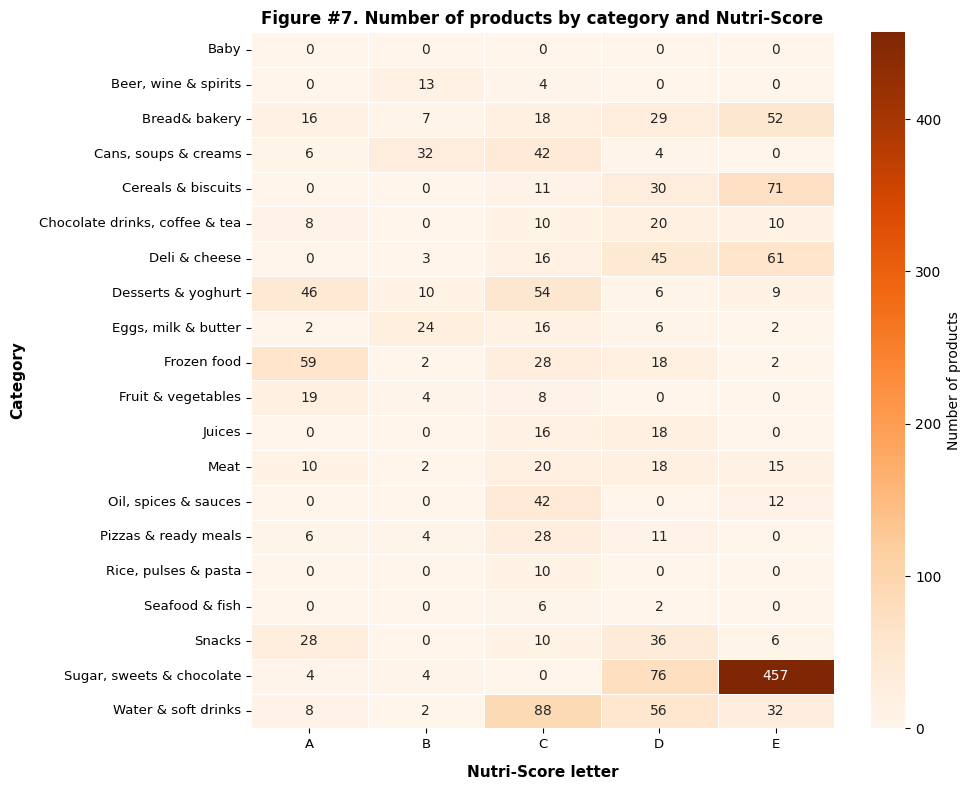

In [51]:
plot_heatmap_number_products_category_nutri_score(df_products, all_categories)

TODO: Treure conclusions quan tingui totes les dades.

In [52]:
def plot_heatmap_number_products_category_ewo(df_products: pd.DataFrame, all_categories: list) -> None:
    """
    Function that generates a heatmap with count products by category and Ewö ultraprocessing level.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        all_categories (list): List of all categories.

    Returns:
        None. Prints out the heatmap.
    """
    ct_ewo = (
        pd.crosstab(df_products['category'], df_products['ewo_ultra_processed_punctuation'])
        .reindex(index=all_categories, columns=[1.0, 2.0, 3.0, 4.0])
        .fillna(0)
        .astype(int)
    )
    
    ct_ewo.columns = ['1.0 (Minimum)','2.0 (Processed)','3.0 (High-processed)','4.0 (Ultraprocessed)']
    
    plot_score_heatmaps_by_category(
        ct_ewo,
        COLORS,
        'Figure #8. Number of products by category and Ewö ultraprocessing level', 'Ewö ultraprocessing level'
    )

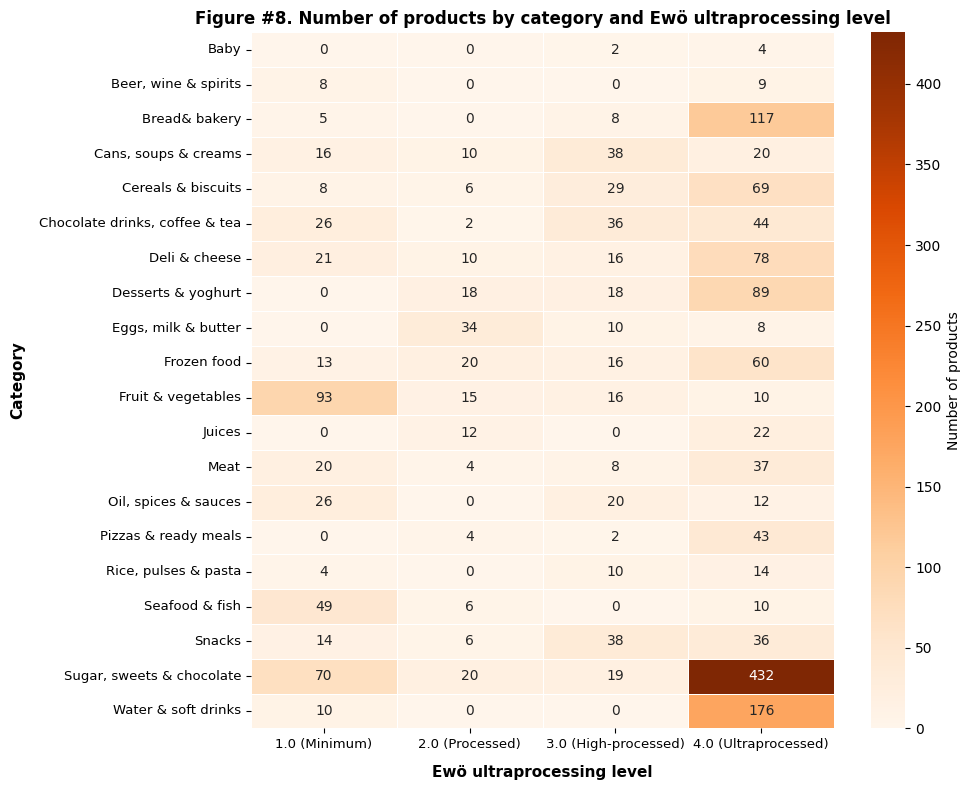

In [53]:
plot_heatmap_number_products_category_ewo(df_products, all_categories)

TODO: Treure conclusions quan tingui totes les dades.

In [54]:
def plot_heatmap_number_products_category_planet_score(df_products: pd.DataFrame, all_categories: list) -> None:
    """
    Function that generates a heatmap with count products by category and Planet-Score.

    Args:
        df_products (pd.DataFrame): DataFrame of the products.
        all_categories (list): List of all categories.

    Returns:
        None. Prints out the heatmap.
    """
    
    ct_planet = (
        pd.crosstab(df_products['category'], df_products['planetscore'])
        .reindex(index=all_categories, columns=['A', 'B', 'C', 'D', 'E'])
        .fillna(0)
        .astype(int)
    )
    
    plot_score_heatmaps_by_category(ct_planet, COLORS, 'Figure #9. Number of products by category and Planet-Score', 'Planet-Score')

In [55]:
# plot_heatmap_number_products_category_planet_score(df_products, all_categories)

TODO: Treure conclusions quan tingui totes les dades.

### 3.3.2. Plotting target variables in comparison with postal code and week number

In [56]:
def build_week_labels(df: pd.DataFrame) -> dict:
    """
    Function to generate label weeks for heatmaps that uses week numbers.
    The string generated is like 'Week X\n(DD/MM/YYYY)'

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        dict: The equivalence of week number and string.
    """
    week_dates = (
        df.groupby('week_num')['date_scraped'].min().sort_index().reset_index()
    )

    week_dates['rel_week'] = range(1, len(week_dates) + 1)

    week_dates['label'] = week_dates.apply(
        lambda r: f"Week {r['rel_week']}\n({r['date_scraped'].strftime('%d/%m/%Y')})",
        axis=1,
    )

    return dict(zip(week_dates['week_num'], week_dates['label']))

def get_mean_std_pivots(df: pd.DataFrame, value_col: str, week_label_map: dict) -> tuple:
    """
    Function that calculates the means and std to print out into the heatmaps
    and renames the week columns.

    Args:
        df (pd.DataFrame): DataFrame with the data.
        value_col (str): Column to be used.
        week_label_map (dict): Dictionary with week labels.

    Returns:
        tuple: mean dataframe and dataframe with information.
    
    """
    p_mean = df.pivot_table(
        index='postal_code',
        columns='week_num',
        values=value_col,
        aggfunc='mean',
        observed=False
    )
    p_std = df.pivot_table(
        index='postal_code',
        columns='week_num',
        values=value_col,
        aggfunc='std',
        observed=False
    )

    annot_df = p_mean.copy().astype(str)
    for row in p_mean.index:
        for col in p_mean.columns:
            m = p_mean.loc[row, col]
            s = p_std.loc[row, col]
            if pd.isna(m):
                annot_df.loc[row, col] = ''
            elif pd.isna(s):
                annot_df.loc[row, col] = f'{m:.2f}\n(±0.00)'
            else:
                annot_df.loc[row, col] = f'{m:.2f}\n(±{s:.2f})'

    if week_label_map:
        p_mean.rename(columns=week_label_map, inplace=True)
        annot_df.rename(columns=week_label_map, inplace=True)

    return p_mean, annot_df

def plot_temporal_heatmap(
    df: pd.DataFrame,
    annotation: pd.DataFrame,
    color: str,
    legend_name: str,
    title_text: str,
    vmin: float,
    vmax: float,
    figsize: tuple = (8, 5),
) -> None:
    """
    Function that generates temporal heatmaps showing means and standard deviation (±SD)

    Args:
        df (pd.DataFrame): DataFrame with data.
        annotation (pd.DataFrame): DataFrame with information about mean and standard deviation.
        color (str): Color palette.
        legend_name (str): Text to display in legend.
        title_text (str): Title of the graphic.
        vmin (float): Value min.
        vmax (float): Value max.
        figsize (tuple): Figure size.

    Returns:
        None. Prints out the graphic.
    """

    plt.figure(figsize=figsize)

    sns.heatmap(
        df,
        annot=annotation,
        fmt='',
        annot_kws={'size': 8},
        cmap=color,
        cbar_kws={'label': legend_name},
        vmin=vmin,
        vmax=vmax
    )

    plt.title(title_text, fontweight='bold', fontsize=12)
    plt.ylabel('Postal code', fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(rotation=0, ha='center', fontsize=9.5)
    plt.yticks(rotation=0, fontsize=9.5)

    plt.tight_layout()
    plt.show()

week_label_map = build_week_labels(df_products)

In [57]:
def plot_heatmap_week_nutri_score(
    df_products: pd.DataFrame,
    week_label_map: dict,
    only_promoted: bool = False
) -> None:
    """
    Function that plots information about how change nutriscore per week using mean and SD.

    Args:
        df_products (pd.DataFrame): DataFrame with the products.
        week_label_map (dict): Dictionary with label information.
        only_promoted (bool): If True, filters only promoted products.

    Returns:
        None. Plots the heatmap.
    """

    if only_promoted:
        df_filtered = df_products[df_products['is_promoted'] == True].copy()
        title_text = "Figure #11. Mean Nutri-Score (±SD) evolution for PROMOTED products by postal code (1=A, 5=E)"
    else:
        df_filtered = df_products
        title_text = "Figure #10. Mean Nutri-Score (±SD) evolution for ALL products\
        by postal code (1=A, 5=E)"
    
    p_nutri_mean, p_nutri_annot = get_mean_std_pivots(
            df_filtered, 'nutriscore_num', week_label_map
        )

    plot_temporal_heatmap(
        p_nutri_mean,
        p_nutri_annot,
        COLORS,
        'Mean Nutri-Score',
        title_text,
        1.0,
        5.0
    )

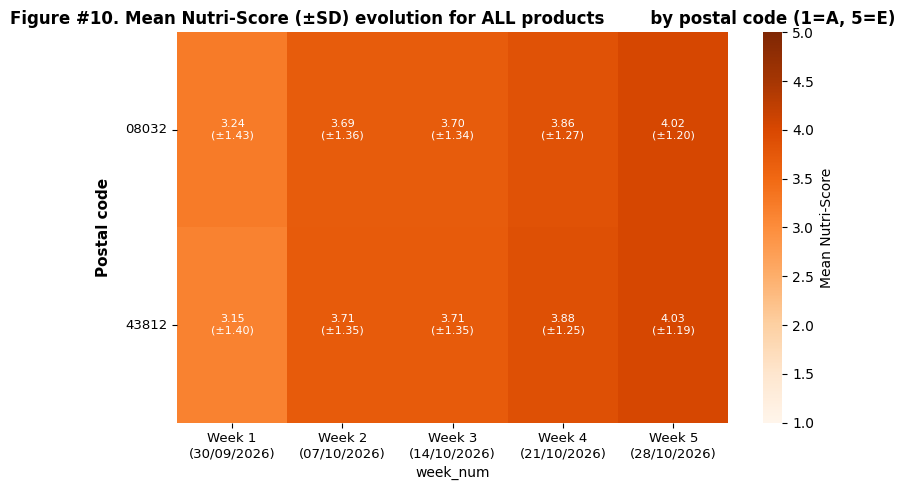

In [58]:
plot_heatmap_week_nutri_score(df_products, week_label_map)

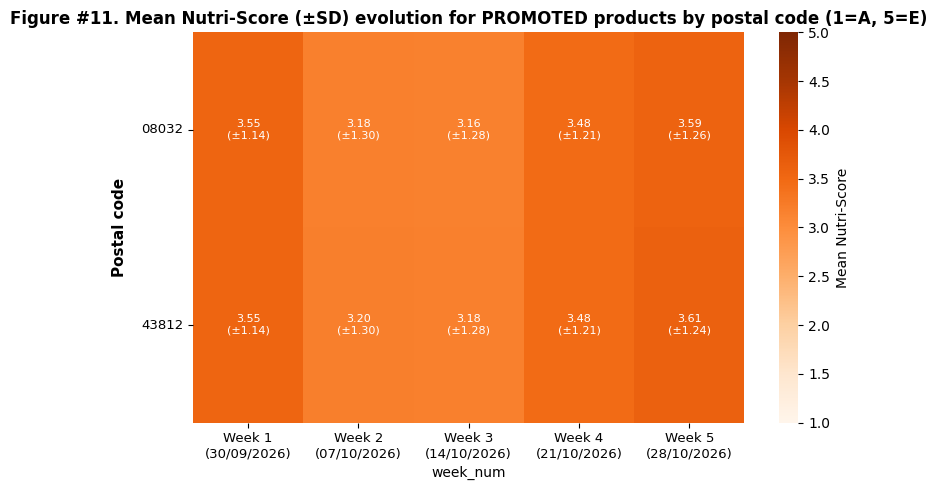

In [59]:
plot_heatmap_week_nutri_score(df_products, week_label_map, True)

TODO: Treure conclusions quan tingui totes les dades.

In [60]:
def plot_heatmap_week_ewo_ultraprocessing_level(
    df_products: pd.DataFrame,
    week_label_map: dict,
    only_promoted: bool = False
) -> None:
    """
    Function that plots information about how change Ewö ultraprocessing level per week using mean and SD.

    Args:
        df_products (pd.DataFrame): DataFrame with the products.
        week_label_map (dict): Dictionary with label information.
        only_promoted (bool): If True, filters only promoted products.

    Returns:
        None. Plots the heatmap.
    """

    if only_promoted:
        df_filtered = df_products[df_products['is_promoted'] == True].copy()
        title_text = "Figure #13. Mean Ewö ultraprocessing level (±SD) evolution for PROMOTED products by postal code (1=minimum processing, 4=ultraprocessed)"
    else:
        df_filtered = df_products
        title_text = "Figure #12. Mean Ewö ultraprocessing level (±SD) evolution for ALL products by postal code (1=minimum processing, 4=ultraprocessed)"
    
    p_ewo_mean, p_ewo_annot = get_mean_std_pivots(df_filtered, 'ewo_ultra_processed_punctuation', week_label_map)

    plot_temporal_heatmap(
        p_ewo_mean,
        p_ewo_annot, 
        COLORS,
        'Mean Ewö ultraprocessing level',
        title_text,
        1.0,
        4.0
    )

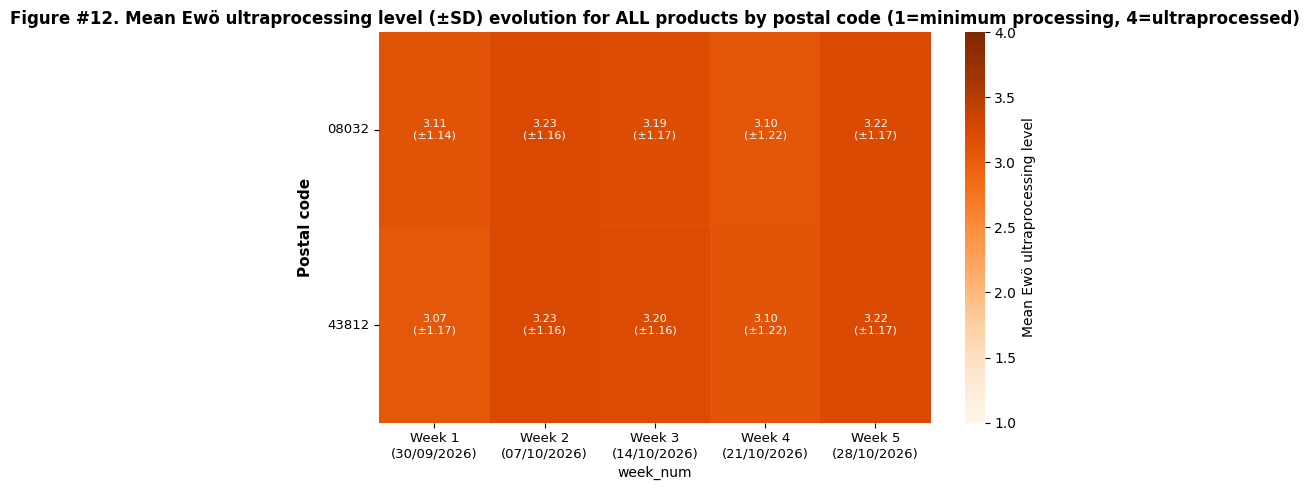

In [61]:
plot_heatmap_week_ewo_ultraprocessing_level(df_products, week_label_map)

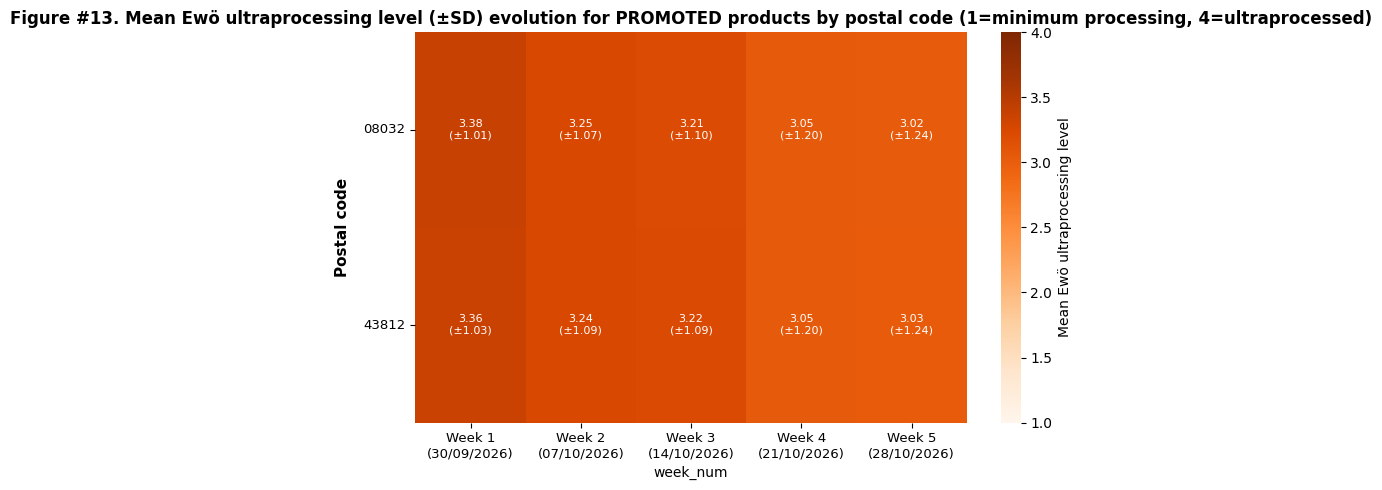

In [62]:
plot_heatmap_week_ewo_ultraprocessing_level(df_products, week_label_map, True)

TODO: Treure'n conclusions quan tingui totes les dades.

In [63]:
def plot_heatmap_week_planet_score(
    df_products: pd.DataFrame,
    week_label_map: dict,
    only_promoted: bool = False
) -> None:
    """
    Function that plots information about how change Planet-Score per week using mean and SD.

    Args:
        df_products (pd.DataFrame): DataFrame with the products.
        week_label_map (dict): Dictionary with label information.
        only_promoted (bool): If True, filters only promoted products.

    Returns:
        None. Plots the heatmap.
    """

    if only_promoted:
        df_filtered = df_products[df_products['is_promoted'] == True].copy()
        title_text = "Figure #15. Mean Planet-Score (±SD) evolution for PROMOTED\
        products by postal code (1=A, 5=E)"
    else:
        df_filtered = df_products
        title_text = "Figure #14. Mean Planet-Score (±SD) evolution for ALL products\
        by postal code (1=A, 5=E)"
    
    p_planet_mean, p_planet_annot = get_mean_std_pivots(df_filtered, 'planetscore_num', week_label_map)

    plot_temporal_heatmap(
        p_planet_mean,
        p_planet_annot, 
        COLORS,
        'Mean Planet-Score',
        title_text
    )

In [64]:
#plot_heatmap_week_planet_score(df_products, week_label_map)

In [65]:
#plot_heatmap_week_planet_score(df_products, week_label_map, True)

TODO: Treure'n conclusions quan tingui totes les dades.

In [66]:
TOP_10_CATEGORIES = df_products['category'].value_counts().head(10).index.tolist()

def plot_boxplot(
    df: pd.DataFrame,
    group_col: str,
    col_to_display: str,
    title: str,
    ylabel: str,
    fixed_groups: list | None = None,
    legend_title: str = 'Groups',
    top_n: int | None = None,
    palette: str = COLORS,
    ylim: tuple | None = None,
    figsize: tuple = (10, 5),
) -> None:
    """
    Function that generates a boxplot with legend.

    Args:
        df (pd.DataFrame): DataFrame with data.
        group_col (str): Aggregation column.
        col_to_display (str): Numerical variable to be represented.
        title (str): Graphic title.
        ylabel (str): Label axis Y.
        fixed_groups (list): List of categories to be displayed.
        legend_title (str): Title at the legend.
        top_n (int): Limits items up to N if is added.
        palette (str): Colours.
        ylim (tuple): Manual limit on axis Y.
        figsize (tuple): Figure size.

    Returns:
        None. It only prints out the figure.
    """

    if fixed_groups is not None:
        selected_groups = fixed_groups
    else:
        global_counts = df[df[group_col].notna()][group_col].value_counts()
        if top_n is not None and top_n < len(global_counts):
            selected_groups = global_counts.head(top_n).index.tolist()
        else:
            selected_groups = global_counts.index.tolist()

    df_valid = df[df[group_col].isin(selected_groups) & df[col_to_display].notna()].copy()
    var_counts = df_valid[group_col].value_counts()
    cat_mapping = {name: str(i) for i, name in enumerate(selected_groups, 1)}
    num_order = [str(i) for i in range(1, len(selected_groups) + 1)]
    df_valid['group_code'] = df_valid[group_col].map(cat_mapping)

    colors_list = sns.color_palette(palette, n_colors=len(selected_groups))
    palette_dict = {code: color for code, color in zip(num_order, colors_list)}

    plt.figure(figsize=figsize)
    
    ax = sns.boxplot(
        data=df_valid,
        x='group_code',
        y=col_to_display,
        order=num_order,
        hue='group_code',
        hue_order=num_order,
        palette=palette_dict,
        legend=False,
    )

    legend_labels = [
        f'{i}. {name} (n={var_counts.get(name, 0)})'
        for i, name in enumerate(selected_groups, 1)
    ]

    handles = [
        Patch(color=palette_dict[str(i)], label=legend_labels[i - 1])
        for i in range(1, len(selected_groups) + 1)
    ]
    
    plt.legend(
        handles=handles,
        title=legend_title,
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        frameon=True,
        fontsize=9.5,
        title_fontsize=10.5,
    )
    
    plt.title(title, fontweight='bold', fontsize=12, pad=15)
    plt.xlabel('Group Code', fontsize=11, fontweight='bold', labelpad=10)
    plt.ylabel(ylabel, fontsize=11, fontweight='bold')
    
    if ylim is not None:
        plt.ylim(ylim)
    
    plt.tight_layout()
    plt.show()

In [67]:
def plot_boxplot_nutri_score(df: pd.DataFrame) -> None:
    """
    Function to print a comparative boxplot of the top 10 categories (Nutri-Score).

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints the graphic.        
    """
    plot_boxplot(
      df=df_products,
      group_col='category',
      col_to_display='nutriscore_num',
      title='Figure #16. Nutri-Score Distribution across Top 10 Supermarket Categories',
      ylabel='Nutri-Score (1=A, 5=E)',
      legend_title='Top 10 Categories',
      fixed_groups=TOP_10_CATEGORIES,
      palette=COLORS,
      ylim=(0.5, 5.5),
  )

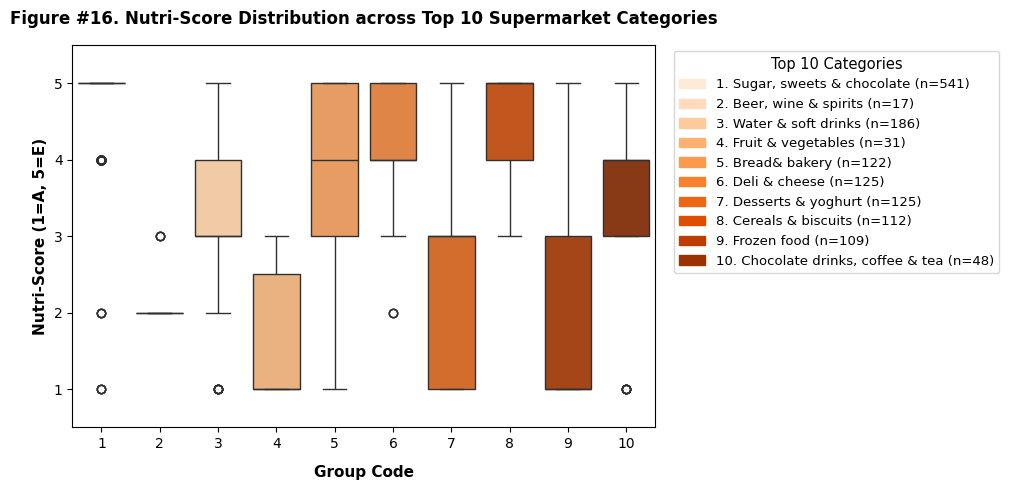

In [68]:
plot_boxplot_nutri_score(df_products)

TODO: Treure'n conclusions quan tingui totes les dades.

In [69]:
def plot_boxplot_ewo_ultraprocessed_level(df: pd.DataFrame) -> None:
    """
    Function to print a comparative boxplot of the top 10 categories (Ewö ultraprocessing level).

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints the graphic.        
    """
    plot_boxplot(
      df=df_products,
      group_col='category',
      col_to_display='ewo_ultra_processed_punctuation',
      title='Figure #17. Ewö Ultra-processed Level across Top 10 Supermarket Categories',
      ylabel='Ewö Score (1=Unprocessed, 4=Ultra-processed)',
      legend_title='Top 10 Categories',
      fixed_groups=TOP_10_CATEGORIES,
      palette=COLORS,
      ylim=(0.5, 4.5),
  )

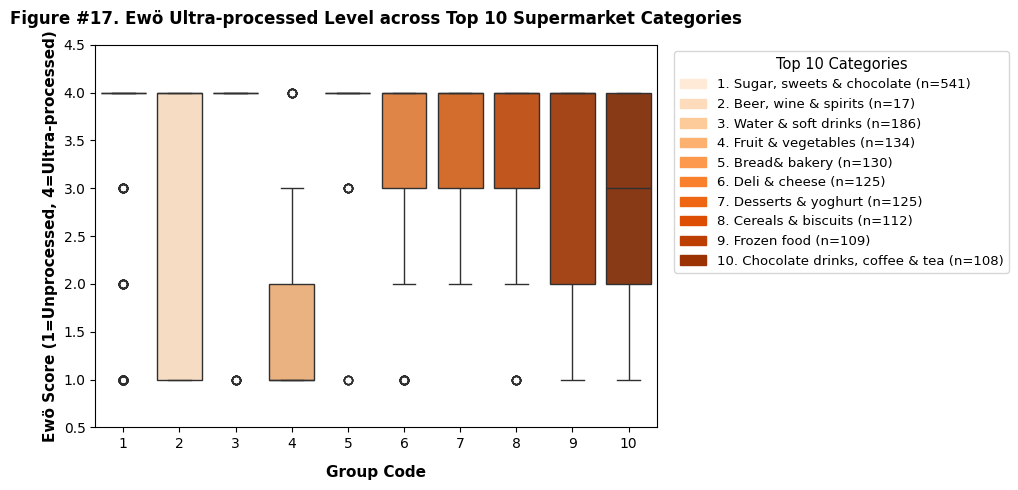

In [70]:
plot_boxplot_ewo_ultraprocessed_level(df_products)

TODO: Treure'n conclusions quan tingui totes les dades.

In [71]:
def plot_boxplot_planet_score(df: pd.DataFrame) -> None:
    """
    Function to print a comparative boxplot of the top 10 categories (Planet-Score).

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints the graphic.        
    """
    plot_boxplot(
      df=df_products,
      group_col='category',
      col_to_display='planetscore_num',
      title='Figure #18. Planet-Score across top 10 online grocery categories',
      ylabel='Planet-Score (1=A, 5=E)',
      legend_title='Top 10 Categories',
      fixed_groups=TOP_10_CATEGORIES,
      palette=COLORS,
      ylim=(0.5, 5.5),
  )

In [72]:
# plot_boxplot_planet_score(df_products)

TODO: Treure'n conclusions quan tingui totes les dades.

### 3.3.3. Table resume of Nutri-Score, Planet-Score and Ewö ultraprocessing level across categories and subcategories

In [73]:
def generate_category_health_environmental_summary_table(
    df: pd.DataFrame,
    top_n_categories: int | None = 10,
    add_subcategories: bool = False
) -> Styler:
    """
    Generate a consolidated executive table summarizing
    the product volume and the average Nutri-Score, Ewö, and Planet-Score scores by category.
    
    Args:
        df (pd.DataFrame): DataFrame with data.
        top_n_categories (int | None): If defined, limits the output. Default: 10.
        add_subcategories (bool): If True, it adds subcategories.
    
    Returns:
        Styler: Dataframe formatted with data and colours.
    """
    
    df_work = df
    if top_n_categories is not None:
        top_cats = df_work['category'].value_counts().head(top_n_categories).index.tolist()
        df_work = df_work[df_work['category'].isin(top_cats)]
    
    grouped = df_work.groupby('category', observed=False)
    if add_subcategories:
        grouped = df_work.groupby(['category', 'subcategory'], observed=False)
    
    summary_rows = []

    if add_subcategories:
        for (cat, subcat), group in grouped:
            n_items = len(group)
            if n_items == 0:
                continue
            
            ns_valid = group['nutriscore_num'].dropna()
            ns_mean = ns_valid.mean() if len(ns_valid) > 0 else np.nan
            ns_std = ns_valid.std() if len(ns_valid) > 1 else 0.0
            ns_str = f'{ns_mean:.2f} (±{ns_std:.2f})' if not np.isnan(ns_mean) else 'N/A'
            
            ewo_valid = group['ewo_ultra_processed_punctuation'].dropna()
            ewo_mean = ewo_valid.mean() if len(ewo_valid) > 0 else np.nan
            ewo_std = ewo_valid.std() if len(ewo_valid) > 1 else 0.0
            ewo_str = f'{ewo_mean:.2f} (±{ewo_std:.2f})' if not np.isnan(ewo_mean) else 'N/A'
            
            if 'planetscore_num' in group.columns and not group['planetscore_num'].dropna().empty:
                ps_valid = group['planetscore_num'].dropna()
                ps_mean = ps_valid.mean()
                ps_std = ps_valid.std() if len(ps_valid) > 1 else 0.0
                ps_str = f'{ps_mean:.2f} (±{ps_std:.2f})'
            else:
                ps_mean = np.nan
                ps_str = 'Pending'
            
            summary_rows.append({
                'Category': cat,
                'Subcategory': subcat,
                'Total (n)': n_items,
                'Nutri-Score (Mean ± SD)': ns_str,
                'Ewö (Mean ± SD)': ewo_str,
                'Planet-Score (Mean ± SD)': ps_str,
                '_ns_mean': ns_mean,
                '_ewo_mean': ewo_mean,
                '_ps_mean': ps_mean,
                })
    else:
        for cat, group in grouped:
            n_items = len(group)
            if n_items == 0:
                continue
            
            ns_valid = group['nutriscore_num'].dropna()
            ns_mean = ns_valid.mean() if len(ns_valid) > 0 else np.nan
            ns_std = ns_valid.std() if len(ns_valid) > 1 else 0.0
            ns_str = f'{ns_mean:.2f} (±{ns_std:.2f})' if not np.isnan(ns_mean) else 'N/A'
            
            ewo_valid = group['ewo_ultra_processed_punctuation'].dropna()
            ewo_mean = ewo_valid.mean() if len(ewo_valid) > 0 else np.nan
            ewo_std = ewo_valid.std() if len(ewo_valid) > 1 else 0.0
            ewo_str = f'{ewo_mean:.2f} (±{ewo_std:.2f})' if not np.isnan(ewo_mean) else 'N/A'
            
            if 'planetscore_num' in group.columns and not group['planetscore_num'].dropna().empty:
                ps_valid = group['planetscore_num'].dropna()
                ps_mean = ps_valid.mean()
                ps_std = ps_valid.std() if len(ps_valid) > 1 else 0.0
                ps_str = f'{ps_mean:.2f} (±{ps_std:.2f})'
            else:
                ps_mean = np.nan
                ps_str = 'Pending'
            
            summary_rows.append({
                'Category': cat,
                'Total (n)': n_items,
                'Nutri-Score (Mean ± SD)': ns_str,
                'Ewö (Mean ± SD)': ewo_str,
                'Planet-Score (Mean ± SD)': ps_str,
                '_ns_mean': ns_mean,
                '_ewo_mean': ewo_mean,
                '_ps_mean': ps_mean,
            })
    
    summary_df = pd.DataFrame(summary_rows)
    summary_df.sort_values(by='Total (n)', ascending=False, inplace=True)
    summary_df.reset_index(drop=True, inplace=True)
    
    styler = summary_df.style
    styler = styler.hide(subset=['_ns_mean', '_ewo_mean', '_ps_mean'], axis='columns')
    styler = styler.format({'Total (n)': '{:,}'})
    
    styler = styler.background_gradient(
        subset=['Nutri-Score (Mean ± SD)'],
        gmap=summary_df['_ns_mean'],
        cmap=COLORS,
        vmin=1.0,
        vmax=5.0,
    )
    
    styler = styler.background_gradient(
        subset=['Ewö (Mean ± SD)'],
        gmap=summary_df['_ewo_mean'],
        cmap=COLORS,
        vmin=1.0,
        vmax=4.0,
    )
    
    if not summary_df['_ps_mean'].isna().all():
        styler = styler.background_gradient(
            subset=['Planet-Score (Mean ± SD)'],
            gmap=summary_df['_ps_mean'],
            cmap=COLORS,
            vmin=1.0,
            vmax=5.0,
        )
    
    return styler

In [74]:
print("Table #16. Product volume and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score) across food categories")

category_quality_summary = generate_category_health_environmental_summary_table(df_products, None)
category_quality_summary

Table #16. Product volume and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score) across food categories


,Category,Total (n),Nutri-Score (Mean ± SD),Ewö (Mean ± SD),Planet-Score (Mean ± SD)
0,"Sugar, sweets & chocolate",541,4.81 (±0.54),3.50 (±1.05),Pending
1,"Beer, wine & spirits",253,2.24 (±0.44),2.59 (±1.54),Pending
2,Water & soft drinks,186,3.55 (±0.94),3.84 (±0.68),Pending
3,Fruit & vegetables,134,1.65 (±0.88),1.57 (±0.97),Pending
4,Bread& bakery,130,3.77 (±1.40),3.82 (±0.62),Pending
5,Deli & cheese,125,4.31 (±0.79),3.21 (±1.16),Pending
6,Desserts & yoghurt,125,2.38 (±1.23),3.57 (±0.73),Pending
7,Cereals & biscuits,112,4.54 (±0.67),3.42 (±0.89),Pending
8,Frozen food,109,2.10 (±1.28),3.13 (±1.10),Pending
9,"Chocolate drinks, coffee & tea",108,3.50 (±1.30),2.91 (±1.18),Pending


In [75]:
print("Table #17. Product volume and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score) across food categories and subcategories")

category_quality_summary = generate_category_health_environmental_summary_table(df_products, None, True)
category_quality_summary

Table #17. Product volume and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score) across food categories and subcategories


,Category,Subcategory,Total (n),Nutri-Score (Mean ± SD),Ewö (Mean ± SD),Planet-Score (Mean ± SD)
0,"Sugar, sweets & chocolate",Sweets,231,4.90 (±0.31),3.18 (±1.34),Pending
1,"Sugar, sweets & chocolate",Chocolate,179,4.88 (±0.33),3.66 (±0.83),Pending
2,"Beer, wine & spirits",Beer,104,N/A,N/A,Pending
3,"Sugar, sweets & chocolate",Nougats,97,4.53 (±0.87),3.80 (±0.40),Pending
4,"Beer, wine & spirits",Spirits,78,N/A,N/A,Pending
5,Snacks,"Nuts, seeds & dried fruit",76,2.48 (±1.40),2.95 (±1.03),Pending
6,Cereals & biscuits,Biscuits,76,4.68 (±0.64),3.64 (±0.63),Pending
7,Fruit & vegetables,Vegetables,67,1.00 (±0.00),1.31 (±0.58),Pending
8,Water & soft drinks,Isotonic and energy drinks,66,3.82 (±0.88),3.91 (±0.52),Pending
9,Seafood & fish,Fresh fish,63,3.00 (±0.00),1.54 (±1.10),Pending


TODO: Treure'n conclusions quan tingui totes les dades

### 3.3.4. Information about homepage sections

In [76]:
def generate_homepage_sections_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Function that generates information of homepage sections per week.
    It shows the total products every week and how changes Nutri-Score,
    Ewö ultraprocessing level and Planet-Score.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        pd.DataFrame: DataFrame with the data for every week and homepage section.
    """

    has_planet_data = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )

    df_home = df[df['title_category_main_page'].notna()].copy()

    rows = []
    grouped = df_home.groupby(['title_category_main_page', 'week_num'], observed=True)

    for (section, week), group in grouped:
        n_products = len(group)

        nutri_s = group['nutriscore_num'].dropna()
        nutri_str = (
            f'{nutri_s.mean():.2f} ({nutri_s.std():.2f})'
            if len(nutri_s) > 1
            else (f'{nutri_s.mean():.2f}' if len(nutri_s) == 1 else 'N/A')
        )

        ewo_s = group['ewo_ultra_processed_punctuation'].dropna()
        ewo_str = (
            f'{ewo_s.mean():.2f} ({ewo_s.std():.2f})'
            if len(ewo_s) > 1
            else (f'{ewo_s.mean():.2f}' if len(ewo_s) == 1 else 'N/A')
        )

        if has_planet_data:
            planet_s = group['planetscore_num'].dropna()
            planet_str = (
                f'{planet_s.mean():.2f} ({planet_s.std():.2f})'
                if len(planet_s) > 1
                else (f'{planet_s.mean():.2f}' if len(planet_s) == 1 else 'N/A')
            )
        else:
            planet_str = 'Pending'

        rows.append({
            'Homepage Sections': section,
            'Week': week,
            'Number of products': n_products,
            'Nutri-Score (Mean, SD)': nutri_str,
            'Ewö (Mean, SD)': ewo_str,
            'Planet-Score (Mean, SD)': planet_str,
        })

    return pd.DataFrame(rows)

In [77]:
homepage_table_df = generate_homepage_sections_table(df_products)

print("Table #18. Weekly distribution of product volume and mean health & environmental scores (Nutri-Score, Ewö, Planet-Score)\
 across featured homepage sections")
homepage_table_df

Table #18. Weekly distribution of product volume and mean health & environmental scores (Nutri-Score, Ewö, Planet-Score) across featured homepage sections


,Homepage Sections,Week,Number of products,"Nutri-Score (Mean, SD)","Ewö (Mean, SD)","Planet-Score (Mean, SD)"
0,Bajadas de precio,40,227,3.55 (1.15),3.41 (0.97),Pending
1,Bajadas de precio,41,248,3.14 (1.29),3.25 (1.06),Pending
2,Bajadas de precio,42,234,3.12 (1.26),3.19 (1.10),Pending
3,Bajadas de precio,43,197,3.43 (1.20),3.16 (1.12),Pending
4,Bajadas de precio,44,218,3.45 (1.22),3.09 (1.17),Pending
5,Disfruta La Castañada,43,16,3.25 (1.39),2.50 (1.31),Pending
6,Disfruta La Castañada,44,15,3.14 (1.46),2.36 (1.29),Pending
7,Han vuelto,40,42,4.04 (1.34),2.57 (1.42),Pending
8,Han vuelto,41,71,4.08 (1.23),3.00 (1.31),Pending
9,Han vuelto,42,58,4.29 (1.13),3.10 (1.27),Pending


## 3.4. Product characteristics by healthiness and environmental sustainability in homepage categories

In [78]:
def generate_healthiness_sustainability_homepage_table(df: pd.DataFrame) -> Styler:
    """
    Function that generates the health and environmental sustainability feature table,
    grouped by the Homepage Sections.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        Styler: DataFrame with results colored.
    """

    has_planet = (
        'planetscore' in df.columns
        and df['planetscore'].notna().sum() > 0
    )

    df_home = df[df['title_category_main_page'].notna()].copy()

    rows = []

    for section_name, group in df_home.groupby('title_category_main_page', observed=True):
        n_products = len(group)
        n_weeks = group['week_num'].nunique()
        nutri_s = group['nutriscore_num'].dropna()
        nutri_mean_raw = nutri_s.mean() if len(nutri_s) > 0 else np.nan
        nutri_str = (
            f'{nutri_s.mean():.2f} ({nutri_s.std():.2f})'
            if len(nutri_s) > 1
            else (f'{nutri_s.mean():.2f}' if len(nutri_s) == 1 else 'N/A')
        )

        ewo_s = group['ewo_ultra_processed_punctuation'].dropna()
        ewo_mean_raw = ewo_s.mean() if len(ewo_s) > 0 else np.nan
        ewo_str = (
            f'{ewo_s.mean():.2f} ({ewo_s.std():.2f})'
            if len(ewo_s) > 1
            else (f'{ewo_s.mean():.2f}' if len(ewo_s) == 1 else 'N/A')
        )

        if has_planet:
            planet_s = group['planetscore_num'].dropna()
            planet_mean_raw = planet_s.mean() if len(planet_s) > 0 else np.nan
            planet_str = (
                f'{planet_s.mean():.2f} ({planet_s.std():.2f})'
                if len(planet_s) > 1
                else (f'{planet_s.mean():.2f}' if len(planet_s) == 1 else 'N/A')
            )
        else:
            planet_str = 'Pending'
            planet_mean_raw = np.nan

        rows.append({
            'Homepage Section': section_name,
            'Weeks (n)': n_weeks,
            'Homepage (n)': n_products,
            'Nutri-Score (Mean; SD)': nutri_str,
            'Ewö (Mean; SD)': ewo_str,
            'Planet-Score (Mean; SD)': planet_str,
            '_nutri_raw': nutri_mean_raw,
            '_ewo_raw': ewo_mean_raw,
            '_planet_raw': planet_mean_raw,
        })

    total_n = len(df_home)
    total_weeks = df_home['week_num'].nunique()
    nutri_tot = df_home['nutriscore_num'].dropna()
    nutri_tot_mean_raw = nutri_tot.mean() if len(nutri_tot) > 0 else np.nan
    ewo_tot = df_home['ewo_ultra_processed_punctuation'].dropna()
    ewo_tot_mean_raw = ewo_tot.mean() if len(ewo_tot) > 0 else np.nan

    nutri_tot_str = (
        f'{nutri_tot.mean():.2f} ({nutri_tot.std():.2f})'
        if len(nutri_tot) > 1
        else 'N/A'
    )
    ewo_tot_str = (
        f'{ewo_tot.mean():.2f} ({ewo_tot.std():.2f})'
        if len(ewo_tot) > 1
        else 'N/A'
    )

    if has_planet:
        planet_tot = df_home['planetscore_num'].dropna()
        planet_tot_mean_raw = planet_tot.mean() if len(planet_tot) > 0 else np.nan
        planet_tot_str = (
            f'{planet_tot.mean():.2f} ({planet_tot.std():.2f})'
            if len(planet_tot) > 1
            else 'N/A'
        )
    else:
        planet_tot_str = 'Pending'
        planet_tot_mean_raw = np.nan

    rows.append({
        'Homepage Section': 'TOTAL HOMEPAGE',
        'Weeks (n)': total_weeks,
        'Homepage (n)': total_n,
        'Nutri-Score (Mean; SD)': nutri_tot_str,
        'Ewö (Mean; SD)': ewo_tot_str,
        'Planet-Score (Mean; SD)': planet_tot_str,
        '_nutri_raw': nutri_tot_mean_raw,
        '_ewo_raw': ewo_tot_mean_raw,
        '_planet_raw': planet_tot_mean_raw,
    })

    table_df = pd.DataFrame(rows)
    nutri_raw = table_df['_nutri_raw']
    ewo_raw = table_df['_ewo_raw']
    planet_raw = table_df['_planet_raw']
    table_df = table_df.drop(columns=['_nutri_raw', '_ewo_raw', '_planet_raw'])
    
    styler = table_df.style
    
    styler = styler.background_gradient(
        subset=['Nutri-Score (Mean; SD)'],
        gmap=nutri_raw,
        cmap=COLORS,
        vmin=1.0,
        vmax=5.0,
    )
    
    styler = styler.background_gradient(
        subset=['Ewö (Mean; SD)'],
        gmap=ewo_raw,
        cmap=COLORS,
        vmin=1.0,
        vmax=4.0,
    )
    
    if has_planet:
        styler = styler.background_gradient(
            subset=['Planet-Score (Mean; SD)'],
            gmap=planet_raw,
            cmap=COLORS,
            vmin=1.0,
            vmax=5.0,
        )
    
    return styler

In [79]:
health_sustainability_homepage_df = generate_healthiness_sustainability_homepage_table(df_products)

print("Table #19. Aggregate sample sizes and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score)\
 across Homepage Sections.")
health_sustainability_homepage_df

Table #19. Aggregate sample sizes and mean health & environmental quality scores (Nutri-Score, Ewö, Planet-Score) across Homepage Sections.


,Homepage Section,Weeks (n),Homepage (n),Nutri-Score (Mean; SD),Ewö (Mean; SD),Planet-Score (Mean; SD)
0,Bajadas de precio,5,1124,3.32 (1.24),3.23 (1.09),Pending
1,Disfruta La Castañada,2,31,3.20 (1.37),2.43 (1.27),Pending
2,Han vuelto,5,410,4.29 (1.09),3.16 (1.22),Pending
3,Novedades,5,414,3.88 (1.32),3.19 (1.22),Pending
4,Productos del momento,5,383,3.90 (1.54),3.07 (1.24),Pending
5,TOTAL HOMEPAGE,5,2362,3.70 (1.34),3.17 (1.17),Pending


In [80]:
def plot_boxplot_homepage_sections_nutriscore(df_products: pd.DataFrame) -> None:
    """
    Function to print out the comparative boxplot for Nutri-Score.

    Args:
        df_products (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints out the graphic.
    """

    plot_boxplot(
        df=df_products,
        group_col='title_category_main_page',
        col_to_display='nutriscore_num',
        title='Figure #19. Nutri-Score Distribution across Homepage Featured Sections',
        ylabel='Nutri-Score (1=A, 5=E)',
        legend_title='Homepage Sections',
        top_n=None,
        palette=COLORS,
        ylim=(0.5, 5.5),
    )

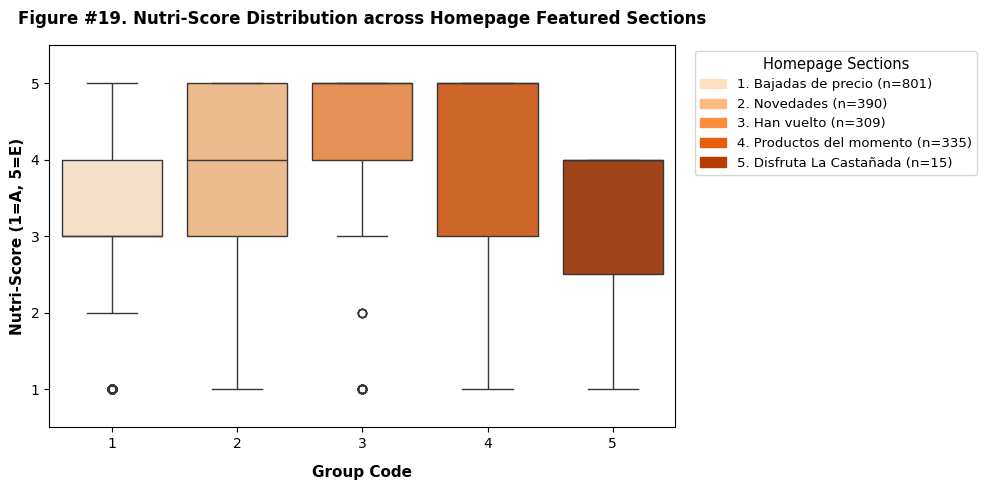

In [81]:
plot_boxplot_homepage_sections_nutriscore(df_products)

TODO: treure conclusions quan tingui totes les dades

In [82]:
def plot_boxplot_homepage_sections_ewo_ultraprocessing_level(df_products: pd.DataFrame) -> None:
    """
    Function to print out the comparative boxplot for Ewö ultraprocessing level.

    Args:
        df_products (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints out the graphic.
    """
    plot_boxplot(
        df=df_products,
        group_col='title_category_main_page',
        col_to_display='ewo_ultra_processed_punctuation',
        title='Figure #20. Ewö Ultra-processed Level across Homepage Featured Sections',
        ylabel='Ewö Score',
        legend_title='Homepage Sections',
        top_n=None,
        palette=COLORS,
        ylim=(0.5, 4.5),
    )

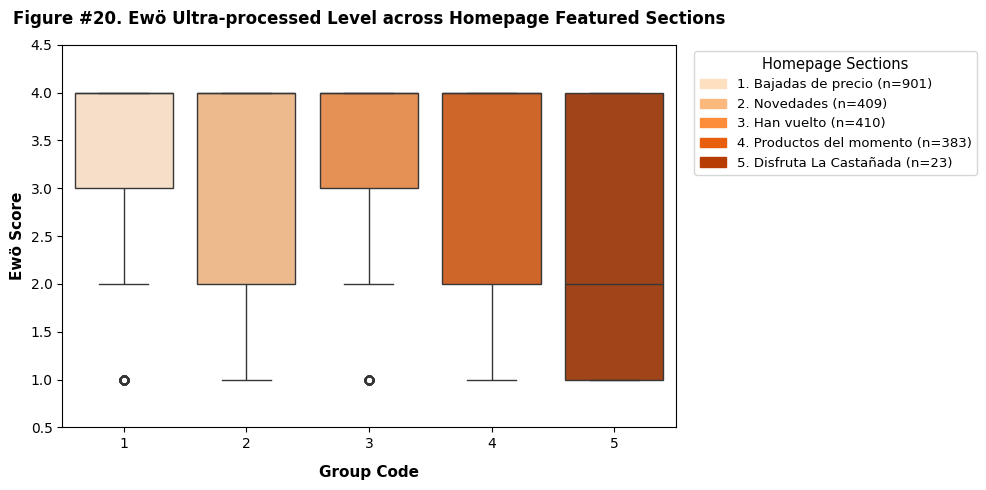

In [83]:
plot_boxplot_homepage_sections_ewo_ultraprocessing_level(df_products)

TODO: treure conclusions quan tingui totes les dades

In [84]:
def plot_boxplot_homepage_sections_planet_score(df_products: pd.DataFrame) -> None:
    """
    Function to print out the comparative boxplot for Planet-Score.

    Args:
        df_products (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints out the graphic.
    """
    plot_boxplot(
        df=df_products,
        group_col='title_category_main_page',
        col_to_display='planetscore_num',
        title='Figure #21. Planet-Score across Homepage Featured Sections',
        ylabel='Planet-Score',
        legend_title='Homepage Sections',
        top_n=None,
        palette=COLORS,
        ylim=(0.5, 4.5),
    )

In [85]:
# plot_boxplot_homepage_sections_planet_score(df_products)

TODO: treure conclusions quan tingui totes les dades

## 3.5. Contraposition of target variables

In [86]:
def add_jitter(series: pd.core.series.Series, amount:float = 0.15) -> pd.core.series.Series:
    """
    Function that add jitter in the values to not concentrate all dots in the same point.

    Args:
        series (pd.core.series.Series): Data.
        amount (float): Quantity of jitter.

    Returns:
        pd.core.series.Series: The new series with the added jitter.
    """

    return series + np.random.uniform(-amount, amount, size=len(series))

def plot_cross_indicator_scatters(
    df: pd.DataFrame,
    variable_1: str,
    variable_2: str,
    title_text: str,
    x_label: str,
    y_label: str,
    x_ticks: list,
    x_tick_labels: list,
    y_ticks: list,
    y_tick_labels: list = None,
    hue_col: str = None
) -> None:
    """
    Function that generates an scatter plot crossing two variables.
    by using jitter and continous colour gradient based on the
    variable percentage_discount.

    Args:
        df (pd.DataFrame): DataFrame with data.
        variable_1 (str): First variable name to use.
        variable_2 (str): Second variable name to use.
        title_text (str): Title of the graphic.
        x_label (str): Label to use on x axis.
        y_label (str): Label to use on y axis.
        x_ticks (list): List of labels for x axis.
        x_tick_labels (list): Tick labels for x axis.
        y_ticks (list): List of y axis ticks.
        y_tick_labels (list): List of y tick labels.

    Returns:
        None. Prints out the graphic.    
    """

    plt.figure(figsize=(8, 6))

    if hue_col is not None:
        sns.scatterplot(
            x=add_jitter(df[variable_1]),
            y=add_jitter(df[variable_2]),
            hue=df[hue_col],
            alpha=0.5,
            s=35,
            palette='Set1' if hue_col else None
        )
    else:
        sns.scatterplot(
            x=add_jitter(df[variable_1]),
            y=add_jitter(df[variable_2]),
            hue=df['percentage_discount'],
            palette=COLORS,
            alpha=0.6,
            s=40,
        )

    plt.title(title_text, fontweight='bold', fontsize=12)
    plt.xlabel(x_label, fontsize=11, fontweight='bold', labelpad=10)
    plt.ylabel(y_label, fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(x_ticks, x_tick_labels, rotation=0, ha='center', fontsize=9.5)

    if y_tick_labels:
        plt.yticks(y_ticks, y_tick_labels, rotation=0, fontsize=9.5)
    else:
        plt.yticks(y_ticks, rotation=0, fontsize=9.5)

    plt.grid(True, linestyle='--', alpha=0.4)
    plt.legend(
        title=hue_col if hue_col is not None else '% Discount',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        frameon=True,
    )

    plt.tight_layout()
    plt.show()

In [87]:
def plot_nutriscore_vs_ewo(df: pd.DataFrame, hue_col: str = None) -> None:
    """
    Function to generate the comparative between Nutri-Score and Ewö ultraprocessing level.

    Args:
        df (pd.DataFrame): DataFrame with data.
        hue_col (str): Variable to determine hue. By default, None.

    Returns:
        None. Prints out the graphic.
    """
    
    data_filtered = df.dropna(
        subset=['nutriscore_num', 'ewo_ultra_processed_punctuation']
    )

    figure_num = "22"
    if hue_col:
        figure_num = "23"
    
    plot_cross_indicator_scatters(
        df=data_filtered,
        variable_1='nutriscore_num',
        variable_2='ewo_ultra_processed_punctuation',
        title_text=f'Figure #{figure_num}. Nutri-Score vs. Ewö Ultraprocessing Level',
        x_label='Nutri-Score (1=A, 5=E)',
        y_label='EWÖ Ultraprocessing Level (1=Minimum, 4=Ultraprocessed)',
        x_ticks=[1, 2, 3, 4, 5],
        x_tick_labels=['A', 'B', 'C', 'D', 'E'],
        y_ticks=[1, 2, 3, 4],
        hue_col=hue_col
    )

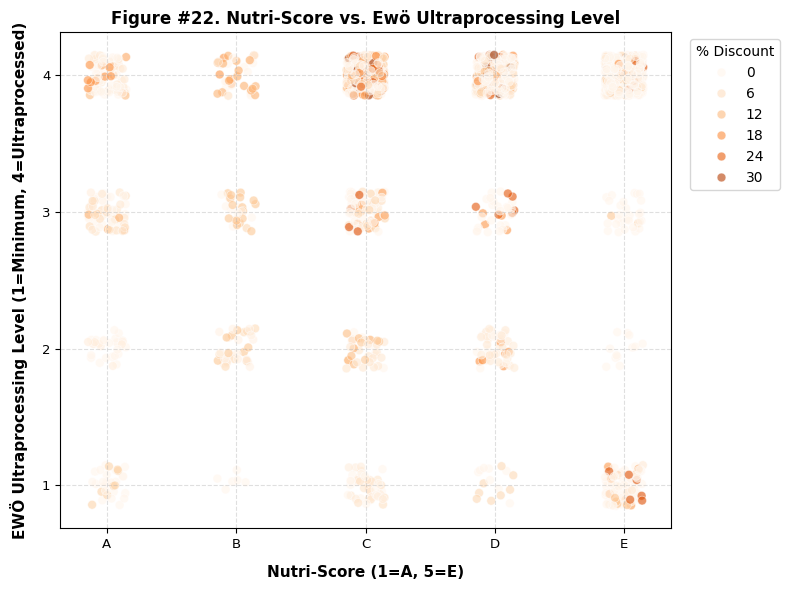

In [88]:
plot_nutriscore_vs_ewo(df_products)

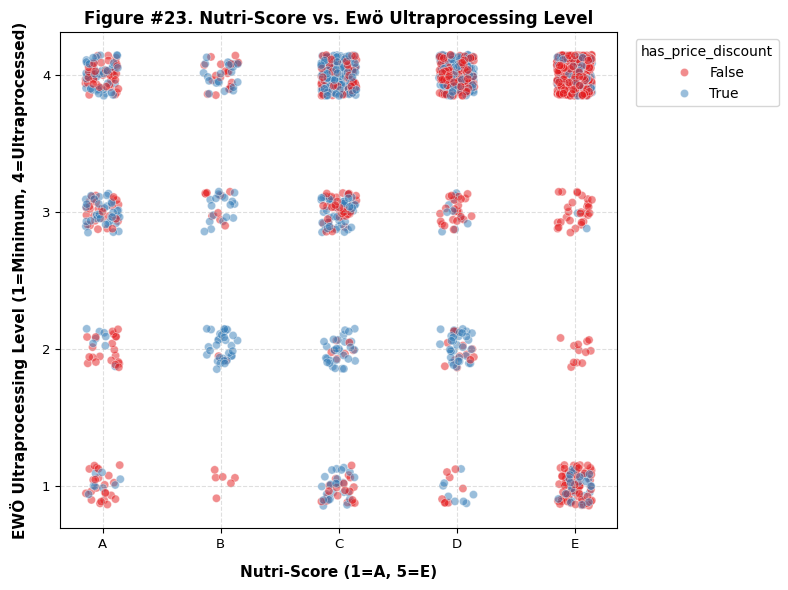

In [89]:
plot_nutriscore_vs_ewo(df_products,'has_price_discount')

TODO: Quan tigui totes les dades ja treuré les conclusions pertinents.

In [90]:
def plot_nutriscore_vs_planet_score(df: pd.DataFrame) -> None:
    """
    Function to generate the comparative between Nutri-Score and Planet-Score.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints out the graphic.
    """

    data_filtered = df.dropna(subset=['nutriscore_num', 'planetscore_num'])

    plot_cross_indicator_scatters(
        df = data_filtered,
        variable_1='nutriscore_num',
        variable_2='planetscore_num',
        title_text='Figure #24. Nutri-Score vs. Planet-Score',
        x_label='Nutri-Score (1=A, 5=E)',
        y_label='Planet-Score (1=A, 5=E)',
        x_ticks=[1, 2, 3, 4, 5],
        x_tick_labels=['A', 'B', 'C', 'D', 'E'],
        y_ticks=[1, 2, 3, 4, 5],
        y_tick_labels=['A', 'B', 'C', 'D', 'E']
    )

In [91]:
# plot_nutriscore_vs_planet_score(df_products)

TODO: Quan tigui totes les dades ja treuré les conclusions pertinents.

In [92]:
def plot_planet_score_vs_ewo_ultraprocessing_level(df: pd.DataFrame) -> None:
    """
    Function to generate the comparative between Planet-Score and Ewö ultraprocessing level.

    Args:
        df (pd.DataFrame): DataFrame with data.

    Returns:
        None. Prints out the graphic.
    """

    data_filtered = df.dropna(subset=['planetscore_num', 'ewo_ultra_processed_punctuation'])

    plot_cross_indicator_scatters(
        df = data_filtered,
        variable_1='planetscore_num',
        variable_2='ewo_ultra_processed_punctuation',
        title_text='Figure #25. Planet-Score vs. EWÖ',
        x_label='Planet-Score (1=A, 5=E)',
        y_label='Ewö ultraprocessing level (1=Minimum, 4=Ultraprocessing)',
        x_ticks=[1, 2, 3, 4, 5],
        x_tick_labels=['A', 'B', 'C', 'D', 'E'],
        y_ticks=[1, 2, 3, 4]
    )

In [93]:
# plot_planet_score_vs_ewo_ultraprocessing_level(df_products)

TODO: Quan tigui totes les dades ja treuré les conclusions pertinents.

# 4. Hypothesis test

All hypothesis test has been done with:

$$ \begin{gathered} CL = 95\% \\ \alpha = 0.05 \end{gathered} $$


## 4.1. Nutri-Score

### 4.1.1. Test 1: The proportion of promotion products is significantly major on unhealthy products (Nutri-Score C/D/E) in comparison on healthy products (Nutri-Score A/B)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \hat{p}_{1} = \hat{p}_{2} \\
H_{1}: \hat{p}_{1} > \hat{p}_{2}
\end{align*}
$$

$$
\begin{align*}
\hat{p}_{1}:\ Proportion\ of \ unhealthy\ products\ (Nutri-Score\ C/D/E) \\
\hat{p}_{2}:\ Proportion\ of \ healthy\ products\ (Nutri-Score\ A/B)
\end{align*}
$$

#### Selection of the data

In [94]:
df_selected_rows = df_products[
    df_products['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
].copy()

df_selected_rows['quality_group'] = df_selected_rows['nutriscore'].apply(
    lambda x: 'A/B' if x in ['A', 'B'] else 'C/D/E'
)

#### Presentation of the samples and determine statistical test

En primer lloc i d’acord amb el Teorema del límit central, que ens diu:

Sigui X una variable aleatòria amb una distribució binomial de paràmetres n i p. Si n és gran, aleshores la distribució de X és aproximadament normal amb esperança np i variància np(1-p). A la pràctica s’acostuma a utilitzar aquesta aproximació quan np i n(1-p) són tots dos més grans que 5, o bé quan n > 30.

Hem de verificar que estem davant d’una binomial. D’acord amb la transformació que hem fet i sabent que una distribució binomial només pot prendre valors 1 o 0, podem afirmar que ens trobem davant d’una binomial. Així doncs, només ens queda comprovar si les dades es poden considerar prou grans.

Per tal de dur a terme aquesta comprovació, hem de calcular per cada grup

$$
\begin{align*}
\mu=n\hat{p} \\
\sigma^2=n(1−\hat{p}) \\
Amb\ \mu\ i\ \sigma^2>5
\end{align*}
$$

In [95]:
contingency_table = pd.crosstab(
    df_selected_rows['quality_group'], df_selected_rows['is_promoted']
)

n_promoted_cde = contingency_table.loc['C/D/E', True]
n_total_cde = contingency_table.loc['C/D/E'].sum()

n_promoted_ab = contingency_table.loc['A/B', True]
n_total_ab = contingency_table.loc['A/B'].sum()

p_hat_cde = n_promoted_cde / n_total_cde
p_hat_ab = n_promoted_ab / n_total_ab

print(f"Group A/B: n={n_total_ab}, p={p_hat_ab}\nGroup C/D/E: n={n_total_cde}, p={p_hat_cde}")

Group A/B: n=319, p=0.542319749216301
Group C/D/E: n=1531, p=0.4519921619856303


In [96]:
mu_ab = n_total_ab*p_hat_ab
sigma_ab = n_total_ab*(1-p_hat_ab)

mu_cde = n_total_cde*p_hat_cde
sigma_cde = n_total_cde*(1-p_hat_cde)

print(f"\u03BC_ab={mu_ab}, \u03C3^2_ab={sigma_ab}\n\u03BC_cde={mu_cde}, \u03C3^2_cde={sigma_cde}")

μ_ab=173.00000000000003, σ^2_ab=145.99999999999997
μ_cde=692.0, σ^2_cde=839.0


D’acord amb la teoria, podem arribar a determinar que les dades podrien arribar a considerar-se prou grans. Així doncs, faré el test de proporcions *z* unilateral per la dreta, el qual segueix la l'expressió:

$$
z=\frac{(\hat{p}_1-\hat{p}_2)}{\sqrt{p(1-p)(\frac{1}{n_1}+\frac{1}{n_2})}} \sim N(0,1)
$$

Essent $p$ un paràmetre desconegut, del qual s'en fa una estimació $\hat{p}$ a partir de les mostres:

$$
\hat{p}=\frac{n_1\hat{p}_1+n_2\hat{p}_2}{n_1+n_2}
$$

#### Applying test and check hypothesis

In [97]:
count = [n_promoted_cde, n_promoted_ab]
nobs = [n_total_cde, n_total_ab]

z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

if p_value < ALPHA:
    print("Descartem H0. Per tant, La proporció de productes promocionats és significativament major en C/D/E que en A/B.")
else:
    print(
        'No es pot rebutjar H0: No hi ha evidència suficient per afirmar que'
        ' C/D/E té més promocions que A/B.'
    )

No es pot rebutjar H0: No hi ha evidència suficient per afirmar que C/D/E té més promocions que A/B.


In [98]:
df_selected_rows['is_unhealthy'] = (
    df_selected_rows['quality_group'] == 'C/D/E'
).astype(int)
df_selected_rows['is_promoted_num'] = df_selected_rows['is_promoted'].astype(
    int
)

# 2. Model de Regressió Logística Simple
logit_model = smf.logit(
    'is_promoted_num ~ is_unhealthy', data=df_selected_rows
).fit()

# 3. Extracció de resultats: Coeficients, Odds Ratio (OR) i p-valors
results = pd.DataFrame({
    'Coeficient (Beta)': logit_model.params,
    'Odds Ratio (OR)': np.exp(logit_model.params),
    'p-value': logit_model.pvalues,
    'CI 2.5%': np.exp(logit_model.conf_int()[0]),
    'CI 97.5%': np.exp(logit_model.conf_int()[1]),
})

print(logit_model.summary())
print(f"AIC: {logit_model.aic}")
print("\n--- ODDS RATIOS ---")
print(results.loc['is_unhealthy'])

Optimization terminated successfully.
         Current function value: 0.688708
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:        is_promoted_num   No. Observations:                 1850
Model:                          Logit   Df Residuals:                     1848
Method:                           MLE   Df Model:                            1
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                0.003377
Time:                        10:57:21   Log-Likelihood:                -1274.1
converged:                       True   LL-Null:                       -1278.4
Covariance Type:            nonrobust   LLR p-value:                  0.003298
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.1697      0.112      1.510      0.131      -0.051       0.390
is_unhealthy    -0.3623

### 4.1.2. Test 2: The proportion of promotion products is significantly major on unhealthy products (Nutri-Score D/E) in comparison on healthy products (Nutri-Score A/B/C)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \hat{p}_{1} = \hat{p}_{2} \\
H_{1}: \hat{p}_{1} > \hat{p}_{2}
\end{align*}
$$

$$
\begin{align*}
\hat{p}_{1}:\ Proportion\ of \ unhealthy\ products\ (Nutri-Score\ D/E) \\
\hat{p}_{2}:\ Proportion\ of \ healthy\ products\ (Nutri-Score\ A/B/C)
\end{align*}
$$

#### Selection of the data

In [99]:
df_selected_rows = df_products[
    df_products['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
].copy()

df_selected_rows['quality_group'] = df_selected_rows['nutriscore'].apply(
    lambda x: 'A/B/C' if x in ['A', 'B', 'C'] else 'D/E'
)

#### Presentation of the samples and determine statistical test

En primer lloc i d’acord amb el Teorema del límit central, que ens diu:

Sigui X una variable aleatòria amb una distribució binomial de paràmetres n i p. Si n és gran, aleshores la distribució de X és aproximadament normal amb esperança np i variància np(1-p). A la pràctica s’acostuma a utilitzar aquesta aproximació quan np i n(1-p) són tots dos més grans que 5, o bé quan n > 30.

Hem de verificar que estem davant d’una binomial. D’acord amb la transformació que hem fet i sabent que una distribució binomial només pot prendre valors 1 o 0, podem afirmar que ens trobem davant d’una binomial. Així doncs, només ens queda comprovar si les dades es poden considerar prou grans.

Per tal de dur a terme aquesta comprovació, hem de calcular per cada grup

$$
\begin{align*}
\mu=n\hat{p} \\
\sigma^2=n(1−\hat{p}) \\
Amb\ \mu\ i\ \sigma^2>5
\end{align*}
$$

In [100]:
contingency_table = pd.crosstab(
    df_selected_rows['quality_group'], df_selected_rows['is_promoted']
)

n_promoted_de = contingency_table.loc['D/E', True]
n_total_de = contingency_table.loc['D/E'].sum()

n_promoted_abc = contingency_table.loc['A/B/C', True]
n_total_abc = contingency_table.loc['A/B/C'].sum()

p_hat_de = n_promoted_de / n_total_de
p_hat_abc = n_promoted_abc / n_total_abc

print(f"Group A/B/C: n={n_total_abc}, p={p_hat_abc}\nGroup D/E: n={n_total_de}, p={p_hat_de}")

Group A/B/C: n=746, p=0.6233243967828418
Group D/E: n=1104, p=0.36231884057971014


In [101]:
mu_abc = n_total_abc*p_hat_abc
sigma_abc = n_total_abc*(1-p_hat_abc)

mu_de = n_total_de*p_hat_de
sigma_de = n_total_de*(1-p_hat_de)

print(f"\u03BC_abc={mu_abc}, \u03C3^2_abc={sigma_abc}\n\u03BC_de={mu_de}, \u03C3^2_de={sigma_de}")

μ_abc=465.0, σ^2_abc=281.0
μ_de=400.0, σ^2_de=703.9999999999999


D’acord amb la teoria, podem arribar a determinar que les dades podrien arribar a considerar-se prou grans. Així doncs, faré el test de proporcions *z* unilateral per la dreta, el qual segueix la l'expressió:

$$
z=\frac{(\hat{p}_1-\hat{p}_2)}{\sqrt{p(1-p)(\frac{1}{n_1}+\frac{1}{n_2})}} \sim N(0,1)
$$

Essent *p* un paràmetre desconegut, del qual s'en fa una estimació $\hat{p}$ a partir de les mostres:

$$
\hat{p}=\frac{n_1\hat{p}_1+n_2\hat{p}_2}{n_1+n_2}
$$

#### Applying test and check hypothesis

In [102]:
count = [n_promoted_de, n_promoted_abc]
nobs = [n_total_de, n_total_abc]

z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

if p_value < ALPHA:
    print("Descartem H0. Per tant, La proporció de productes promocionats és significativament major en D/E que en A/B/C.")
else:
    print(
        'No es pot rebutjar H0: No hi ha evidència suficient per afirmar que'
        ' D/E té més promocions que A/B/C.'
    )

No es pot rebutjar H0: No hi ha evidència suficient per afirmar que D/E té més promocions que A/B/C.


### 4.1.3. Test 3: When a price discount is applied, is the mean percentage reduction on unhealthy products (C/D/E) greater than on healthy ones (A/B)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1} = \mu_{2} \\
H_{1}: \mu_{1} > \mu_{2}
\end{align*}
$$

$$
\begin{align*}
\mu_{1}:\ Unhealthy\ products\ percentage\ (Nutri-Score\ C/D/E) \\
\mu_{2}:\ Healthy\ products\ percentage\ (Nutri-Score\ A/B)
\end{align*}
$$

#### Selection of the data

In [103]:
products_with_percentage_discount = df_products[df_products["has_price_discount"] == True]

df_unique_promo = (
    products_with_percentage_discount.groupby('id_product')
    .agg({
        'nutriscore': 'first',
        'percentage_discount': 'mean',
    })
    .reset_index()
)

df_unique_promo = df_unique_promo[
    df_unique_promo['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
].copy()

df_unique_promo['quality_group'] = df_unique_promo['nutriscore'].apply(
    lambda x: 'A/B' if x in ['A', 'B'] else 'C/D/E'
)

group_ab = df_unique_promo[df_unique_promo['quality_group'] == 'A/B']['percentage_discount']
group_cde = df_unique_promo[df_unique_promo['quality_group'] == 'C/D/E']['percentage_discount']

#### Presentation of the samples and determine statistical test

In [104]:
n_ab, mean_ab, std_ab = len(group_ab), group_ab.mean(), group_ab.std()
n_cde, mean_cde, std_cde = len(group_cde), group_cde.mean(), group_cde.std()

print(f'Group A/B (Healthy): n ={n_ab}, mean ={mean_ab:.2f}%, sd ={std_ab:.2f}%')
print(f'Group C/D/E (Unhealthy): n ={n_cde}, mean ={mean_cde:.2f}%, sd ={std_cde:.2f}%')

Group A/B (Healthy): n =31, mean =8.07%, sd =5.04%
Group C/D/E (Unhealthy): n =135, mean =12.22%, sd =8.52%


**Teorema del límit central**

El teorema del límit central diu que si una mostra és prou gran (n > 30), sigui quina sigui la distribució de la variable d'interès, la distribució de la mitjana mostral serà aproximadament una normal. A més, la mitjana serà la mateixa que la de la variable d'interès, i la desviació típica de la mitjana mostral serà aproximadament l'error estàndard.



Així doncs, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [105]:
levene_stats, levene_p = stats.levene(group_cde, group_ab)
if levene_p < ALPHA:
    print("Descartem H0. Les variancies no son iguals.")
else:
    print("No podem descartar H0. Les variances son iguals.")

Descartem H0. Les variancies no son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies diferents (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x_{1}} - \bar{x_{2}}}{\sqrt{\frac{s^2_{1}}{n_1}+\frac{s^2_2}{n_2}}} \sim t_{v}
$$

I té *v* graus de llibertat:

$$
v=\frac{(\frac{s^2_1}{n_1}+\frac{s^2_{2}}{n_2})^2}{\frac{(\frac{s^2_{1}}{n_1})^2}{(n_{1}-1)} + \frac{(\frac{s^2_{2}}{n_{2}})^2}{(n_2-1)}}
$$

#### Applying test and check hypothesis

In [106]:
t_stat, p_val = stats.ttest_ind(
    group_cde,
    group_ab,
    equal_var=False,
    alternative="greater"
)
    
if p_val < ALPHA:
    print("Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
else:
    print("No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


### 4.1.4. Test 4: When a price discount is applied, is the mean percentage reduction on unhealthy products (D/E) greater than on healthy ones (A/B/C)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1} = \mu_{2} \\
H_{1}: \mu_{1} > \mu_{2}
\end{align*}
$$

$$
\begin{align*}
\mu_{1}:\ Unhealthy\ products\ percentage\ (Nutri-Score\ D/E) \\
\mu_{2}:\ Healthy\ products\ percentage\ (Nutri-Score\ A/B/C)
\end{align*}
$$

#### Selection of the data

In [107]:
products_with_percentage_discount = df_products[df_products["has_price_discount"] == True]

df_unique_promo = (
    products_with_percentage_discount.groupby('id_product')
    .agg({
        'nutriscore': 'first',
        'percentage_discount': 'mean',
    })
    .reset_index()
)

df_unique_promo = df_unique_promo[
    df_unique_promo['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
].copy()

df_unique_promo['quality_group'] = df_unique_promo['nutriscore'].apply(
    lambda x: 'A/B/C' if x in ['A', 'B', 'C'] else 'D/E'
)

group_abc = df_unique_promo[df_unique_promo['quality_group'] == 'A/B/C']['percentage_discount']
group_de = df_unique_promo[df_unique_promo['quality_group'] == 'D/E']['percentage_discount']

#### Presentation of the samples and determine statistical test

In [108]:
n_abc, mean_abc, std_abc = len(group_abc), group_abc.mean(), group_abc.std()
n_de, mean_de, std_de = len(group_de), group_de.mean(), group_de.std()

print(f'Group A/B/C (Healthy): n = {n_abc}, mean = {mean_abc:.2f}%, sd = {std_abc:.2f}%')
print(f'Group D/E (Unhealthy): n = {n_de}, mean = {mean_de:.2f}%, sd = {std_de:.2f}%')

Group A/B/C (Healthy): n = 87, mean = 10.22%, sd = 7.30%
Group D/E (Unhealthy): n = 79, mean = 12.79%, sd = 8.82%


**Teorema del límit central**

El teorema del límit central diu que si una mostra és prou gran (n > 30), sigui quina sigui la distribució de la variable d'interès, la distribució de la mitjana mostral serà aproximadament una normal. A més, la mitjana serà la mateixa que la de la variable d'interès, i la desviació típica de la mitjana mostral serà aproximadament l'error estàndard.



Així doncs, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [109]:
levene_stats, levene_p = stats.levene(group_de, group_abc)
if levene_p < ALPHA:
    print("Descartem H0. Les variancies no son iguals.")
else:
    print("No podem descartar H0. Les variances son iguals.")

No podem descartar H0. Les variances son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies iguals (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student amb $n_1 + n_2 -2$ graus de llibertat, que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x}_1-\bar{x}_2}{S\sqrt{\frac{1}{n_1}+\frac{1}{n_2}}} \sim t_{n_1+n_2-2}
$$

El valor S és la desviació tipica comuna que es calcula segons:

$$
S=\sqrt{\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}}
$$

#### Applying test and check hypothesis

In [110]:
t_stat, p_val = stats.ttest_ind(
    group_de,
    group_abc,
    equal_var=True,
    alternative="greater"
)
    
if p_val < ALPHA:
    print("Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
else:
    print("No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


### 4.1.5. Test 5: When a price discount is applied, are there significant differences in the average discount percentage between promoted products with Nutri-Score C/D/E in comparison with Nutri-Score A/B, stratified by postal code?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1,k} = \mu_{2,k} \\
H_{1}: \mu_{1,k} > \mu_{2,k} \\
k \in \{43812, 08032\}
\end{align*}
$$

$$
\begin{align*}
\mu_{1,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ unhealthy\ (Nutri-Score\ C/D/E)\ in\ postal\ code\ k \\
\mu_{2,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ healthy\ (Nutri-Score\ A/B)\ in\ postal\ code\ k \\
\end{align*}
$$

#### Selection of the data

In [111]:
postal_codes = sorted(products_with_percentage_discount['postal_code'].dropna().unique())

pc_data = {}

for pc in postal_codes:
    df_pc = products_with_percentage_discount[products_with_percentage_discount['postal_code'] == pc].copy()
    df_pc_unique = (
            df_pc.groupby('id_product')
            .agg({'nutriscore': 'first', 'percentage_discount': 'mean'})
            .reset_index()
        )

    df_pc_selected = df_pc_unique[
        df_pc_unique['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
    ].copy()
    df_pc_selected['quality_group'] = df_pc_selected['nutriscore'].apply(
        lambda x: 'A/B' if x in ['A', 'B'] else 'C/D/E'
    )

    group_ab = df_pc_selected[df_pc_selected['quality_group'] == 'A/B']['percentage_discount'].dropna()
    group_cde = df_pc_selected[df_pc_selected['quality_group'] == 'C/D/E']['percentage_discount'].dropna()
    
    pc_data[int(pc)] = {'group_ab': group_ab, 'group_cde': group_cde }

#### Presentation of the samples and determine statistical test

In [112]:
for pc, content in pc_data.items():
    group_ab = content['group_ab']
    group_cde = content['group_cde']

    n_ab, mean_ab, std_ab = (len(group_ab),group_ab.mean(),group_ab.std())
    n_cde, mean_cde, std_cde = (len(group_cde), group_cde.mean(), group_cde.std())
    
    print(f"Postal code {pc}:\n Group healthy (A/B) n={n_ab}, mean={mean_ab}%, sd={std_ab}%\n Group unhealthy (C/D/E) n={n_cde}, mean={mean_cde}%, sd={std_cde}")

Postal code 8032:
 Group healthy (A/B) n=31, mean=8.072129032258065%, sd=5.038483685540955%
 Group unhealthy (C/D/E) n=134, mean=12.257899253731344%, sd=8.536221658008953
Postal code 43812:
 Group healthy (A/B) n=31, mean=8.072129032258065%, sd=5.038483685540955%
 Group unhealthy (C/D/E) n=135, mean=12.219100000000001%, sd=8.516250501028527


Pel teorema del límit central, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [113]:
for pc, content in pc_data.items():
    group_ab = content['group_ab']
    group_cde = content['group_cde']

    levene_stats, levene_p = stats.levene(group_cde, group_ab)
    if levene_p < ALPHA:
        print(f"{pc} - Descartem H0. Les variancies no son iguals.")
    else:
        print(f"{pc} - No podem descartar H0. Les variances son iguals.")

8032 - Descartem H0. Les variancies no son iguals.
43812 - Descartem H0. Les variancies no son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies diferents (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x_{1}} - \bar{x_{2}}}{\sqrt{\frac{s^2_{1}}{n_1}+\frac{s^2_2}{n_2}}} \sim t_{v}
$$

I té *v* graus de llibertat:

$$
v=\frac{(\frac{s^2_1}{n_1}+\frac{s^2_{2}}{n_2})^2}{\frac{(\frac{s^2_{1}}{n_1})^2}{(n_{1}-1)} + \frac{(\frac{s^2_{2}}{n_{2}})^2}{(n_2-1)}}
$$

#### Applying test and check hypothesis

In [114]:
for pc, content in pc_data.items():
    group_ab = content['group_ab']
    group_cde = content['group_cde']
    t_stat, p_val = stats.ttest_ind(
        group_cde,
        group_ab,
        equal_var=False,
        alternative="greater"
    )
    
    if p_val < ALPHA:
        print(f"{pc} - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
    else:
        print(f"{pc} - No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

8032 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.
43812 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


### 4.1.6. Test 6: When a price discount is applied, are there significant differences in the average discount percentage between promoted products with Nutri-Score D/E in comparison with Nutri-Score A/B/C, stratified by postal code?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1,k} = \mu_{2,k} \\
H_{1}: \mu_{1,k} > \mu_{2,k} \\
k \in \{43812, 08032\}
\end{align*}
$$

$$
\begin{align*}
\mu_{1,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ unhealthy\ (Nutri-Score\ D/E)\ in\ postal\ code\ k \\
\mu_{2,k}:\ Percentage\ of\ mean\ discount\ of\ promoted\ products\ healthy\ (Nutri-Score\ A/B/C)\ in\ postal\ code\ k \\
\end{align*}
$$

#### Selection of the data

In [115]:
postal_codes = sorted(products_with_percentage_discount['postal_code'].dropna().unique())

pc_data = {}

for pc in postal_codes:
    df_pc = products_with_percentage_discount[products_with_percentage_discount['postal_code'] == pc].copy()
    df_pc_unique = (
            df_pc.groupby('id_product')
            .agg({'nutriscore': 'first', 'percentage_discount': 'mean'})
            .reset_index()
        )

    df_pc_selected = df_pc_unique[
        df_pc_unique['nutriscore'].isin(['A', 'B', 'C', 'D', 'E'])
    ].copy()
    df_pc_selected['quality_group'] = df_pc_selected['nutriscore'].apply(
        lambda x: 'A/B/C' if x in ['A', 'B', 'C'] else 'D/E'
    )

    group_abc = df_pc_selected[df_pc_selected['quality_group'] == 'A/B/C']['percentage_discount'].dropna()
    group_de = df_pc_selected[df_pc_selected['quality_group'] == 'D/E']['percentage_discount'].dropna()
    
    pc_data[int(pc)] = {'group_abc': group_abc, 'group_de': group_de }

#### Presentation of the samples and determine statistical test

In [116]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']

    n_abc, mean_abc, std_abc = (len(group_abc),group_abc.mean(),group_abc.std())
    n_de, mean_de, std_de = (len(group_de), group_de.mean(), group_de.std())
    
    print(f"Postal code {pc}:\n Group healthy (A/B/C) n={n_abc}, mean={mean_abc}%, sd={std_abc}%\n Group unhealthy (D/E) n={n_de}, mean={mean_de}%, sd={std_de}")

Postal code 8032:
 Group healthy (A/B/C) n=87, mean=10.21940804597701%, sd=7.295146823174892%
 Group unhealthy (D/E) n=78, mean=12.868025641025639%, sd=8.848394088612121
Postal code 43812:
 Group healthy (A/B/C) n=87, mean=10.21940804597701%, sd=7.295146823174892%
 Group unhealthy (D/E) n=79, mean=12.793999999999997%, sd=8.81607688056896


Pel teorema del límit central, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [117]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']

    levene_stats, levene_p = stats.levene(group_de, group_abc)
    if levene_p < ALPHA:
        print(f"{pc} - Descartem H0. Les variancies no son iguals.")
    else:
        print(f"{pc} - No podem descartar H0. Les variances son iguals.")

8032 - No podem descartar H0. Les variances son iguals.
43812 - No podem descartar H0. Les variances son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies iguals (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student amb $n_1 + n_2 -2$ graus de llibertat, que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x}_1-\bar{x}_2}{S\sqrt{\frac{1}{n_1}+\frac{1}{n_2}}} \sim t_{n_1+n_2-2}
$$

El valor S és la desviació tipica comuna que es calcula segons:

$$
S=\sqrt{\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}}
$$

#### Applying test and check hypothesis

In [118]:
for pc, content in pc_data.items():
    group_abc = content['group_abc']
    group_de = content['group_de']
    t_stat, p_val = stats.ttest_ind(
        group_de,
        group_abc,
        equal_var=True,
        alternative="greater"
    )
    
    if p_val < ALPHA:
        print(f"{pc} - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
    else:
        print(f"{pc} - No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

8032 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.
43812 - Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.


## 4.2. Ultraprocessing level by Ewö algorithm

In this case, no stratified hypothesis test for postal code have been applied because it is demonstrated that geographical dimension not modifies the result.

### 4.2.1. Test 1: The proportion of promotion products is significantly major on processed/ultraprocessed products (3/4) in comparison of healthy products (1/2)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \hat{p}_{1} = \hat{p}_{2} \\
H_{1}: \hat{p}_{1} > \hat{p}_{2}
\end{align*}
$$

$$
\begin{align*}
\hat{p}_{1}:\ Proportion\ of \ processed/ultraprocessed\ products\ (Ewö\ 3/4) \\
\hat{p}_{2}:\ Proportion\ of \ low/medium\ processed\ products\ (Ewö\ 1/2)
\end{align*}
$$

#### Selection of the data

In [119]:
df_selected_rows = df_products[
    df_products['ewo_ultra_processed_punctuation'].isin([1.0, 2.0, 3.0, 4.0])
].copy()

df_selected_rows['quality_group'] = df_selected_rows['ewo_ultra_processed_punctuation'].apply(
    lambda x: '1/2' if x in [1.0, 2.0] else '3/4'
)

group_low = df_selected_rows[df_selected_rows['quality_group'] == '1/2']
group_high = df_selected_rows[df_selected_rows['quality_group'] == '3/4']

#### Presentation of the samples and determine statistical test

En primer lloc i d’acord amb el Teorema del límit central, que ens diu:

Sigui X una variable aleatòria amb una distribució binomial de paràmetres n i p. Si n és gran, aleshores la distribució de X és aproximadament normal amb esperança np i variància np(1-p). A la pràctica s’acostuma a utilitzar aquesta aproximació quan np i n(1-p) són tots dos més grans que 5, o bé quan n > 30.

Hem de verificar que estem davant d’una binomial. D’acord amb la transformació que hem fet i sabent que una distribució binomial només pot prendre valors 1 o 0, podem afirmar que ens trobem davant d’una binomial. Així doncs, només ens queda comprovar si les dades es poden considerar prou grans.

Per tal de dur a terme aquesta comprovació, hem de calcular per cada grup

$$
\begin{align*}
\mu=n\hat{p} \\
\sigma^2=n(1−\hat{p}) \\
Amb\ \mu\ i\ \sigma^2>5
\end{align*}
$$

In [120]:
contingency_table = pd.crosstab(
    df_selected_rows['quality_group'], df_selected_rows['is_promoted']
)


n_promoted_high = contingency_table.loc['3/4', True]
n_total_high = contingency_table.loc['3/4'].sum()

n_promoted_low = contingency_table.loc['1/2', True]
n_total_low = contingency_table.loc['1/2'].sum()

p_hat_high = n_promoted_high / n_total_high
p_hat_low = n_promoted_low / n_total_low

print(f"Group low processed: n={n_total_low}, p={p_hat_low}\n\
Group processed/ultraprocessed: n={n_total_high}, p={p_hat_high}")

Group low processed: n=550, p=0.46545454545454545
Group processed/ultraprocessed: n=1576, p=0.4612944162436548


In [121]:
mu_low = n_total_low*p_hat_low
sigma_low = n_total_low*(1-p_hat_low)

mu_high = n_total_high*p_hat_high
sigma_high = n_total_high*(1-p_hat_high)

print(f"\u03BC_low={mu_low}, \u03C3^2_low={sigma_low}\n\u03BC_high={mu_high}, \u03C3^2_high={sigma_high}")

μ_low=256.0, σ^2_low=294.0
μ_high=727.0, σ^2_high=849.0000000000001


D’acord amb la teoria, podem arribar a determinar que les dades podrien arribar a considerar-se prou grans. Així doncs, faré el test de proporcions *z* unilateral per la dreta, el qual segueix la l'expressió:

$$
z=\frac{(\hat{p}_1-\hat{p}_2)}{\sqrt{p(1-p)(\frac{1}{n_1}+\frac{1}{n_2})}} \sim N(0,1)
$$

Essent $p$ un paràmetre desconegut, del qual s'en fa una estimació $\hat{p}$ a partir de les mostres:

$$
\hat{p}=\frac{n_1\hat{p}_1+n_2\hat{p}_2}{n_1+n_2}
$$

#### Applying test and check hypothesis

In [122]:
count = [n_promoted_high, n_promoted_low]
nobs = [n_total_high, n_total_low]

z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

if p_value < ALPHA:
    print("Descartem H0. Per tant, La proporció de productes promocionats és significativament major en processats i ultraprocessats (3/4) que en poc processats (1/2).")
else:
    print(
        'No es pot rebutjar H0: No hi ha evidència suficient per afirmar que'
        ' 3/4 té més promocions que 1/2.'
    )

No es pot rebutjar H0: No hi ha evidència suficient per afirmar que 3/4 té més promocions que 1/2.


### 4.2.2. Test 2: When a price discount is applied, is the mean percentage reduction on processed and high-processed (3/4) greater than on low and medium processed (1/2)?

#### Establishing the hipothesis

$$
\begin{align*}
H_{0}: \mu_{1} = \mu_{2} \\
H_{1}: \mu_{1} > \mu_{2}
\end{align*}
$$

$$
\begin{align*}
\mu_{1}:\ Unhealthy\ products\ percentage\ (Ewö\ 3/4) \\
\mu_{2}:\ Healthy\ products\ percentage\ (Ewö\ 1/2)
\end{align*}
$$

#### Selection of the data

In [123]:
products_with_percentage_discount = df_products[df_products["has_price_discount"] == True]

df_unique_promo = (
    products_with_percentage_discount.groupby('id_product')
    .agg({
        'product_name': 'first',
        'ewo_ultra_processed_punctuation': 'first',
        'percentage_discount': 'mean',
    })
    .reset_index()
)

df_unique_promo = df_unique_promo[
    df_unique_promo['ewo_ultra_processed_punctuation'].isin([1.0, 2.0, 3.0, 4.0])
].copy()

df_unique_promo['quality_group'] = df_unique_promo['ewo_ultra_processed_punctuation'].apply(
    lambda x: '1/2' if x in [1.0, 2.0] else '3/4'
)

group_low_medium_processing = df_unique_promo[df_unique_promo['quality_group'] == '1/2']['percentage_discount']
group_high_ultra_processing = df_unique_promo[df_unique_promo['quality_group'] == '3/4']['percentage_discount']

#### Presentation of the samples and determine statistical test

In [124]:
n_low_medium_processing, mean_low_medium_processing, std_low_medium_processing = len(group_low_medium_processing), group_low_medium_processing.mean(), group_low_medium_processing.std()
n_high_ultra_processing, mean_high_ultra_processing, std_high_ultra_processing = len(group_high_ultra_processing), group_high_ultra_processing.mean(), group_high_ultra_processing.std()

print(f'Group low/medium processing: n = {n_low_medium_processing}, mean = {mean_low_medium_processing:.2f}%, sd = {std_low_medium_processing:.2f}%')
print(f'Group high/ultra processing: n = {n_high_ultra_processing}, mean = {mean_high_ultra_processing:.2f}%, sd = {std_high_ultra_processing:.2f}%')

Group low/medium processing: n = 39, mean = 9.90%, sd = 7.45%
Group high/ultra processing: n = 150, mean = 12.14%, sd = 8.31%


Així doncs, estem davant de dades normals i un **test unilateral per la dreta**. Hem de verificar si existeixen variances iguals o diferents a través del test de levene (test d'homocedasticitat, igualtat de variances)

In [125]:
levene_stats, levene_p = stats.levene(group_high_ultra_processing, group_low_medium_processing)
if levene_p < ALPHA:
    print("Descartem H0. Les variancies no son iguals.")
else:
    print("No podem descartar H0. Les variances son iguals.")

No podem descartar H0. Les variances son iguals.


Amb tota aquesta informació ja sabem que estem davant d'un **contrast d'hipòtesis de dues mostres unilateral per la dreta amb variancies iguals (no coneguda)**. El test d'hipotesis que s'aplica és una *t* de student amb $n_1 + n_2 -2$ graus de llibertat, que es regeix per aquest estadístic de contrast:

$$
t=\frac{\bar{x}_1-\bar{x}_2}{S\sqrt{\frac{1}{n_1}+\frac{1}{n_2}}} \sim t_{n_1+n_2-2}
$$

El valor S és la desviació tipica comuna que es calcula segons:

$$
S=\sqrt{\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}}
$$

#### Applying test and check hypothesis

In [126]:
t_stat, p_val = stats.ttest_ind(
    group_high_ultra_processing,
    group_low_medium_processing,
    equal_var=True,
    alternative="greater"
)
    
if p_val < ALPHA:
    print("Descartem H0. Per tant, les promocions dels productes no saludables tenen un percentatge de descompte mitjà significativament superior als productes saludables.")
else:
    print("No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.")

No podem rebutjar H0. Per tant, amb un nivell de confiança del 95% no podem determinar que el descompte de productes no saludables sigui superior als productes saludables.


## 4.3. Planet-Score

In this case, no stratified hypothesis test for postal code have been applied because it is demonstrated that geographical dimension not modifies the result.

In [127]:
# TODO: Esperar els valors...
#Pel planet score fer el mateix al contrast hipotesis (nomes lo primer)

TODO: Fer-ho al final quan tinguem tots els resultats bé :) 
<table style="margin-top: 1em; width: 100%; border-collapse: collapse;">
    <caption><h5>Table #20. Resume of the hypothesis test done</h5></caption>
  <thead style="background-color: #f0f0f0;">
    <tr>
      <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Question</th>
        <th style="border: 1px solid #ccc; padding: 6px; text-align: left;">Test</th>
      <th style="border: 1px solid #ccc; padding: 6px;">p-value</th>
        <th style="border: 1px solid #ccc; padding: 6px;">result</th>
    </tr>
  </thead>
  <tbody>
    <tr>
        <td style="border: 1px solid #ccc; padding: 6px;">PR1: L’esperança de vida és més alta als països amb un nivell d’ingressos elevat que a la resta?</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Test de contrast de diferències de les mitjanes de dues mostres, variància desconeguda (diferent) i unilateral per la dreta. t d’Student amb v graus de llibertat.</td>
        <td style="border: 1px solid #ccc; padding: 6px;">0.0000000</td>
        <td style="border: 1px solid #ccc; padding: 6px;">Rebutgem H0
 perquè el p-valor < α
 ( 0.05 ). Resposta a la pregunta: SI</td>
    </tr>
  </tbody>
</table>

# 5. Logistic regression for promotion vs no promotion foods

Per tal de realitzar aquesta regressió logística per a obtenir informació per si un producte està promocionat o no, utilitzarem la variable binarizada `is_promoted`, que s'ha calculat en anteriors apartats.

## 5.1. Variable selection

In [128]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2362 entries, 0 to 2361
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   date_scraped                     2362 non-null   datetime64[ns]
 1   week_num                         2362 non-null   int64         
 2   postal_code                      2362 non-null   category      
 3   id_product                       2362 non-null   object        
 4   category                         2362 non-null   category      
 5   subcategory                      2362 non-null   category      
 6   title_category_main_page         2362 non-null   category      
 7   product_name                     2362 non-null   object        
 8   pvp                              2362 non-null   float64       
 9   previous_pvp                     1159 non-null   float64       
 10  nutriscore                       1850 non-null   object     

Les variables que utilitzarem en aquesta regressió logística seran totes aquelles variables que no estiguin lligades directament en la variable `is_promoted`, perquè pot donar una falsa percepció de que el model és molt bo, però ho serà perquè tindrà les dades sobre les quals ens hem basat per a calcular aquest. Per tant, les que descartem de bones a primeres són les variables: `has_price_discount`, `previous_pvp`, `pack_format`, `is_pack`, `total_units`, `promotion_type` i `percentage_discount`. A més, també no seleccionarem totes aquelles variables que siguin referents a normalitzacions i coses que s'han utilitzat en altres seccions que aqui no apliquen: `can_nutriscore_be_calculated`, `can_ewo_be_calculated`, `category_norm`, `subcategory_norm`.

Per la resta de variables, abans de formular el model de regressió logística, es revisarà la correlació de les variables i també la multicol·linealitat, per tal que el model no es perdi. Columnes com `category`, `subcategory`, `title_category_main_page`, `postal_code` o `product_name` són text i no generen cap valor de correlació (no entraran en aquest estudi). A més, els identificadors únics com `id_product` o `date_scraped` no tenen cap valor estadístic.

Així doncs, les variables a estudiar la correlació i la multicol·linealitat són:
* `week_num`,
* `pvp`,
* `nutriscore_num`: L'altre variable que representa el nutriscore es pot treure perquè és categòrica i no ens mostraria res.
* `planetscore_num`: Igual que en el cas anterior, es pot treure la variable que representa el planetscore perquè és categòrica i no ens mostraria res.
* `ewo_ultra_processed_punctuation`

També comentar que només em quedo amb la categoria perquè si li poso categoria i subcategoria, el model falla, entra en bucle infinit i no pot extreure els coeficients.

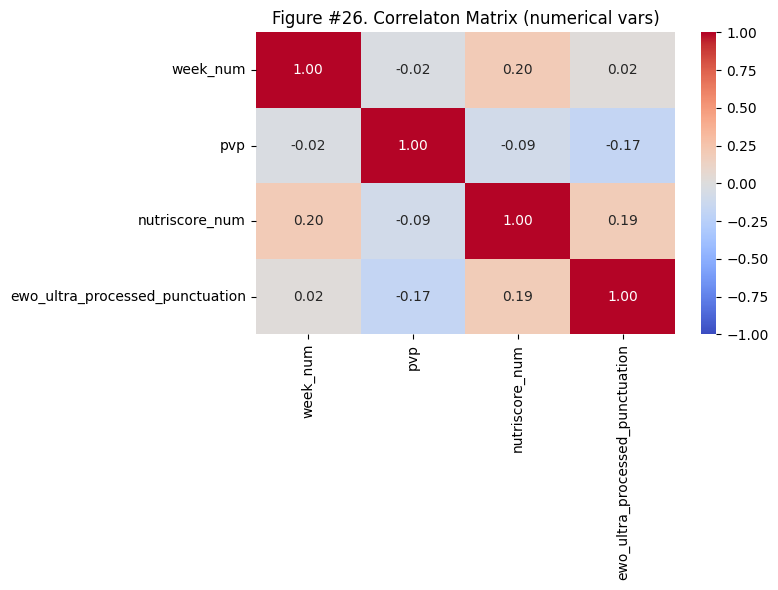

In [129]:
#'planetscore_num' afegir quan tingui planetscore
corr_matrix = df_products[['week_num', 'pvp', 'nutriscore_num', 'ewo_ultra_processed_punctuation']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Figure #26. Correlaton Matrix (numerical vars)')
plt.tight_layout()
plt.show()

Les correlacions són molt baixes, poden anar totes al model

In [130]:
variables_to_select = [
    'is_promoted',
    'nutriscore_num',
    # 'planetscore_num',
    'ewo_ultra_processed_punctuation',
    'pvp',
    'category',
    'postal_code',
    'week_num',
]

df_model = df_products[variables_to_select].dropna().copy()
df_model['is_promoted'] = df_model['is_promoted'].astype(int)
df_model['category'] = df_model['category'].cat.remove_unused_categories()
df_model['postal_code'] = df_model['postal_code'].cat.remove_unused_categories()

Li he afegit aixo de remove_unused_categories perquè si no, al fer el fit() el model peta per aquelles categories que no hi ha dades.

## 5.2. Estimació del model de regressió logística

En aquest apartat ens demanen la realització d’un model de regressió logística binària. Així doncs, podem definir la variable dependent dicotòmica Y com:

$$
Y_i =
\begin{cases}
0 & \text{Percepció de No promoció} \\
1 & \text{Percepció de Sí promoció}
\end{cases}
$$

### Enfocament purament inferencial a través de tot el dataset

Enfocament Purament Inferencial / Economètric (Tot el dataset): S'utilitza tot el conjunt de dades quan l'únic objectiu és estimar la relació entre variables, mesurar els p-valors i calcular els Odds Ratios amb la màxima potència estadística possible ($N$ màxima).

Per tal de comprovar sobre cada variable que entrarà en el model, quina és la categoria sobre la qual es contraposa i el codi postal:

In [131]:
df_model['category'].cat.categories[0]

'Oil, spices & sauces'

In [132]:
df_model['postal_code'].cat.categories[0]

'08032'

In [133]:
# TODO: afegir aqui el planet-score quan estigui...
formula = 'is_promoted ~ nutriscore_num + ewo_ultra_processed_punctuation + pvp + C(category) + C(postal_code) + week_num'

In [134]:
logit_model = smf.logit(formula=formula, data=df_model).fit()
print(logit_model.summary())
print(f"AIC: {logit_model.aic}")

         Current function value: 0.455049
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:            is_promoted   No. Observations:                 1850
Model:                          Logit   Df Residuals:                     1826
Method:                           MLE   Df Model:                           23
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                  0.3415
Time:                        10:57:22   Log-Likelihood:                -841.84
converged:                      False   LL-Null:                       -1278.4
Covariance Type:            nonrobust   LLR p-value:                1.118e-169
                                                    coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------
Intercept                                        -1.7504      1.846     -0

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


TODO: revisar els valors per quan tingui tots els valors...

Per tal de determinar els coeficients que són significants en aquest model de regressió logística, cal mirar la columna $P>|Z|$. Si $(P>|Z|) < 0.05$, llavors el coeficient és significatiu, altrament no. En aquest cas, els que no són significatius són:
* `C(category)[T.Arroz legumbres y pasta]`
* `C(category)[T.Fruta y verdura]`
* `C(category)[T.Huevos leche y mantequilla]`
* `C(category)[T.Marisco y pescado]`
* `C(category)[T.Zumos]`
* `C(postal_code)[T.43812]`
* `nutriscore_num`
* `ewo_ultra_processed_punctuation`

Presenta un AIC elevat, cosa que segurament es podria disminuir si eliminéssim aquestes variables no significatives.

Si analitzem cadascun dels coeficients significatius tenim que:
* Signes positius:
    * `C(category)[T.Agua y refrescos]`: Perceben més promoció que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Postres y yogures]`: Perceben més promoció que la categoria base *Aceite especias y salsas*
    * `pvp`: A major pvp, més percepció de promocions.
    * `week_num`: A mesura que augmenten les setmanes, més promocions.
* Signes negatius:
    * `C(category)[T.Aperitivos]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Azúcar caramelos y chocolate]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Cacao café e infusiones]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Carne]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Cereales y galletas]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Charcutería y quesos]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Congelados]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Conservas caldos y cremas]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Panadería y pastelería]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*
    * `C(category)[T.Pizzas y platos preparados]`: Perceben menys promocions que la categoria base *Aceite especias y salsas*

**Càlcul de les OR**

Per tal de calcular les Odds-Ratio usarem el que s’explica en la teoria de l’assignatura Anàlisi Estadística. També cal tenir en compte que per a determinar si una variable es considera factor de risc o de protecció es fa a través de l’anàlisi de les OR.

* OR = 1. No hi ha associació entre la variable resposta i la covariable.
* OR < 1. **Factor de protecció**, és a dir, el succés és menys probable en presència d’aquesta covariable.
* OR > 1. **Factor de risc**, és a dir, el succés és més probable en presència d’aquesta covariable.

In [135]:
params = logit_model.params

odds_ratios = pd.DataFrame({
        'OR (e^beta)': np.exp(params),
        'P>|z|': logit_model.pvalues,
})

# Arrodonim per presentar-ho millor a la memòria
odds_ratios = odds_ratios.round(4)
print('\n--- ODDS RATIOS (OR) ---')
print(odds_ratios)


--- ODDS RATIOS (OR) ---
                                                OR (e^beta)   P>|z|
Intercept                                      1.737000e-01  0.3430
C(category)[T.Water & soft drinks]             3.984000e+00  0.0076
C(category)[T.Snacks]                          4.290000e-01  0.0724
C(category)[T.Rice, pulses & pasta]            2.643233e+08  0.9984
C(category)[T.Sugar, sweets & chocolate]       6.090000e-02  0.0000
C(category)[T.Beer, wine & spirits]            2.473077e+08  0.9984
C(category)[T.Chocolate drinks, coffee & tea]  2.295000e-01  0.0037
C(category)[T.Meat]                            7.190000e-02  0.0000
C(category)[T.Cereals & biscuits]              2.698000e-01  0.0035
C(category)[T.Deli & cheese]                   2.462000e-01  0.0014
C(category)[T.Frozen food]                     8.110000e-02  0.0000
C(category)[T.Cans, soups & creams]            1.006000e-01  0.0000
C(category)[T.Fruit & vegetables]              0.000000e+00  0.9980
C(category)[T.Eggs, mi

TODO: Revisar per quan tingui totes les dades...

**Factors de protecció** amb menor propensió a promoció en comparació a la categoria base
* `C(category)[T.Panadería y pastelería]`: Els productes de la categoria Panadería y pastelería tenen un Odds de promoció (1-1.070000e-02)*100 en la probabilitat relativa d'estar promocionats respecte a Aceite, especias y salsas.
* `C(category)[T.Aperitivos]` 
* `C(category)[T.Azúcar caramelos y chocolate]` 
* `C(category)[T.Cacao café e infusiones]` 
* `C(category)[T.Carne]` 
* `C(category)[T.Cereales y galletas]` 
* `C(category)[T.Charcutería y quesos]` 
* `C(category)[T.Congelados]` 
* `C(category)[T.Conservas caldos y cremas]` 
* `C(category)[T.Pizzas y platos preparados]`
* Si aqui hi hagues alguna contínua, llavors si apliques OR - 1 apareix un % negatiu, per tant, vol dir que les odds de promoció es redueixen.

**Factors de risc** amb major propensió a promoció en comparació a la categoria base o a la seva presencia en el model
* `C(category)[T.Agua y refrescos]`: Els productes de la categoria agua y refrescos tenen un odds de promoció 3.58 vegades superior respecte a la categoria base
* `C(category)[T.Postres y yogures]`
* `week_num`: Per cada setmana addicional en el seguiment de les dades, l'Odds de trobar un producte promocionat augmenta un 20.97% ($OR = 1.21$ -> 1.21 - 1 = 0.21 * 100 = 21%).
* `pvp`: Per cada euro d'increment en el preu de venda al públic, l'Odds que el producte estigui promocionat augmenta un 7.96% ($OR = 1.08$).

### Enfocament de validació preditiva

Enfocament de Validació Predictiva (Train / Test Split): Es divideixen les dades quan es vol provar que el model no té overfitting i que les conclusions o prediccions sobre la promoció es mantenen fermes en un conjunt de dades no vist.

In [136]:
df_train, df_test = train_test_split(
    df_model,
    test_size=0.30,
    random_state=SEED,
    stratify=df_model['is_promoted']
)

In [137]:
logit_model = smf.logit(formula=formula, data=df_train).fit()
print(logit_model.summary())
print(f"AIC: {logit_model.aic}")

         Current function value: 0.443166
         Iterations: 35


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                           Logit Regression Results                           
Dep. Variable:            is_promoted   No. Observations:                 1295
Model:                          Logit   Df Residuals:                     1271
Method:                           MLE   Df Model:                           23
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                  0.3587
Time:                        10:57:22   Log-Likelihood:                -573.90
converged:                      False   LL-Null:                       -894.96
Covariance Type:            nonrobust   LLR p-value:                6.631e-121
                                                    coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------
Intercept                                        -3.3135      2.224     -1.490      0.136      -7.673       1.046
C(category)[T.Water & soft

TODO: Fer el mateix que en el cas anterior

In [138]:
params = logit_model.params
conf = logit_model.conf_int()

odds_ratios = pd.DataFrame({
    'OR (e^beta)': np.exp(params),
    'p-value': logit_model.pvalues,
}).round(4)

print('\n--- ODDS RATIOS (Training) ---')
print(odds_ratios)


--- ODDS RATIOS (Training) ---
                                                OR (e^beta)  p-value
Intercept                                      3.640000e-02   0.1363
C(category)[T.Water & soft drinks]             7.032100e+00   0.0115
C(category)[T.Snacks]                          3.587000e-01   0.0773
C(category)[T.Rice, pulses & pasta]            2.591709e+08   0.9986
C(category)[T.Sugar, sweets & chocolate]       5.180000e-02   0.0000
C(category)[T.Beer, wine & spirits]            1.559533e+08   0.9987
C(category)[T.Chocolate drinks, coffee & tea]  1.830000e-01   0.0070
C(category)[T.Meat]                            4.530000e-02   0.0000
C(category)[T.Cereals & biscuits]              1.811000e-01   0.0020
C(category)[T.Deli & cheese]                   1.429000e-01   0.0003
C(category)[T.Frozen food]                     5.300000e-02   0.0000
C(category)[T.Cans, soups & creams]            7.390000e-02   0.0000
C(category)[T.Fruit & vegetables]              0.000000e+00   0.9983
C(

TODO: Fer el mateix que en el cas anterior

### Bondat de l'ajustament i corba ROC

D’acord amb el que s’estableix a la teoria, per tal de calcular la bondat de l’ajustament utilitzarem el Chi quadrat (diferència de desviances nul·la i residual), i hi establirem la pregunta, les hipòtesis i realitzarem el test.

**Pregunta: El model amb predictors és equivalent al model sense predictors?**

$$
\begin{align*}
H_0: El\ model\ amb\ predictors\ és\ equivalent\ al\ model\ sense\ predictors \\
H_1: El\ model\ amb\ predictors\ millora\ el\ model\ sense\ predictors
\end{align*}
$$

D’acord amb la teoria s’estableix que la diferència de deviances, es distribueix com una chi-quadrat:

$$
\begin{align*}
\chi^2=Null\ Deviance\ −\ Residual\ Deviance\\
Graus\ de\ llibertat=graus\ de\ llibertat_{null}−graus\ de\ llibertat_{residual}
\end{align*}
$$

A continuació es realitzen els càlculs:

In [139]:
chi_squared = logit_model.llr
degrees_of_freedom = int(logit_model.df_model)
p_value = stats.chi2.sf(chi_squared, df=degrees_of_freedom)

print("--- TEST DE BONDAT D'AJUSTAMENT (DEVIANCES CHI-SQUARE) ---")
print(f"Chi-Square (D):    {chi_squared:.4f}")
print(f"Graus de llibertat:{degrees_of_freedom}")
print(f"p-valor:           {p_value:.4e}")

--- TEST DE BONDAT D'AJUSTAMENT (DEVIANCES CHI-SQUARE) ---
Chi-Square (D):    642.1289
Graus de llibertat:23
p-valor:           6.6310e-121


Ens interessa saber si $D$, que és la diferència entre les deviances null i residual és superior a $\chi^2_r$. Dit d’una altra forma, descartarem la H0 si $D≥\chi^2_r$. El resultat és que la $\chi^2(22)=472.5714$, i el p-valor és 0, que és inferior a $\alpha$ 0.05, per tant, podem descartar H0 en favor que el model millora significativament amb la presència de predictors.

In [140]:
y_test_true = df_test['is_promoted']
y_test_prob = logit_model.predict(df_test)
y_test_pred = (y_test_prob >= 0.5).astype(int)

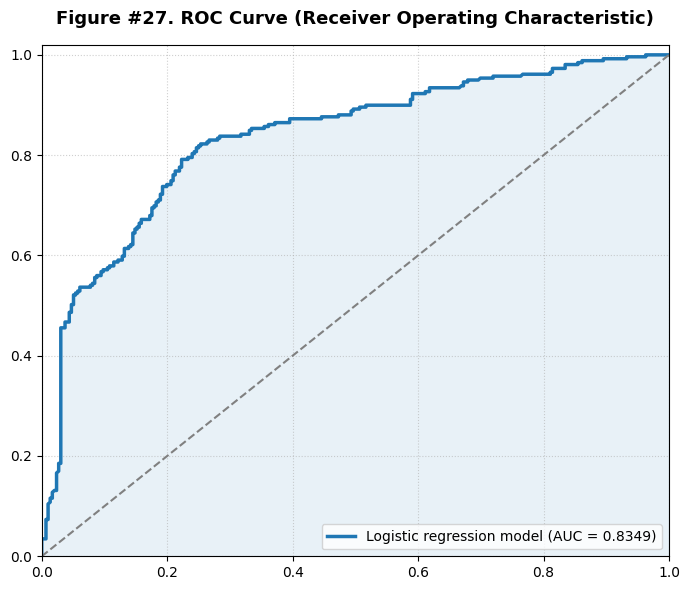

In [141]:
fpr, tpr, thresholds = roc_curve(y_test_true, y_test_prob)
auc_score = roc_auc_score(y_test_true, y_test_prob)


plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    color='#1f77b4',
    lw=2.5,
    label=f'Logistic regression model (AUC = {auc_score:.4f})',
)

plt.plot(
    [0, 1],
    [0, 1],
    color='gray',
    linestyle='--',
    lw=1.5,
)

plt.fill_between(fpr, tpr, alpha=0.10, color='#1f77b4')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.title(
    'Figure #27. ROC Curve (Receiver Operating Characteristic)',
    fontsize=13,
    pad=15,
    weight='bold',
)
plt.legend(loc='lower right', fontsize=10, frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

TODO: treure conclusions quan tingui tots els valors

En general:

* Si $AUROC≤0.5$, el model no ajuda a discriminar.
* Si $0.6≤AUROC<0.8$, el model discrimina de manera adequada.
* Si $0.8≤AUROC<0.9$, el model discrimina de forma excel·lent.
* Si $AUROC≥0.9$, el model discrimina de manera excepcional.
  
En el nostre cas, l’AUROC ens ha donat de 0.88. Per tant, el model discrimina de forma excel·lent.

Una altra informació que proporciona la corba ROC és saber el llindar de classificació o tall de probabilitat, que hem fixat a 0.5 en anteriors apartats. D’acord amb la teoria, el millor llindar de classificació és aquell punt que proporciona una distància més elevada entre la corba ROC i la diagonal.

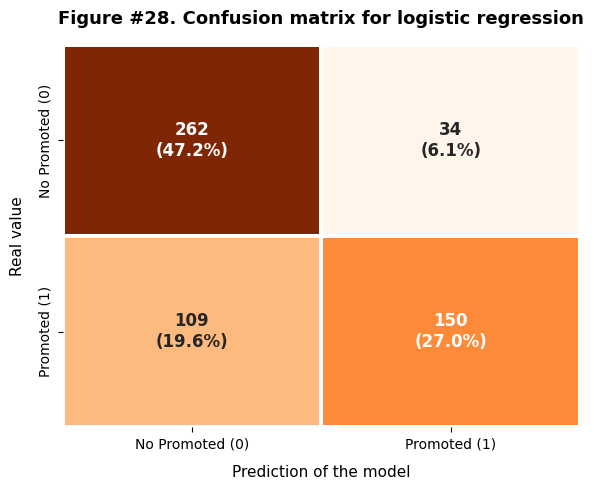


--- Classification report ---
              precision    recall  f1-score   support

 No promoted       0.71      0.89      0.79       296
    Promoted       0.82      0.58      0.68       259

    accuracy                           0.74       555
   macro avg       0.76      0.73      0.73       555
weighted avg       0.76      0.74      0.74       555



In [142]:
acc = accuracy_score(y_test_true, y_test_pred)
cm = confusion_matrix(y_test_true, y_test_pred)

plt.figure(figsize=(6, 5))

group_counts = [f'{value:0.0f}' for value in cm.flatten()]
group_percentages = [
    f'{value:.1%}' for value in cm.flatten() / np.sum(cm)
]
labels = [f'{v1}\n({v2})' for v1, v2 in zip(group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

sns.heatmap(
    cm,
    annot=labels,
    fmt='',
    cmap=COLORS,
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    xticklabels=['No Promoted (0)', 'Promoted (1)'],
    yticklabels=['No Promoted (0)', 'Promoted (1)'],
    annot_kws={'size': 12, 'weight': 'bold'},
)

plt.title(
    "Figure #28. Confusion matrix for logistic regression",
    fontsize=13,
    pad=15,
    weight='bold',
)
plt.xlabel('Prediction of the model', fontsize=11, labelpad=10)
plt.ylabel('Real value', fontsize=11, labelpad=10)

plt.tight_layout()
plt.show()


print('\n--- Classification report ---')
print(
    classification_report(
        y_test_true, y_test_pred, target_names=['No promoted', 'Promoted']
    )
)

TODO: Treure conclusions quan tingui totes les dades...

# 6. Machine learning approach. Unsupervised clustering by K-Means

TODO quan tingui les dades de planet-score... (la seguent figura sera la 27, i la propera taula la 19)

* Reducción de la dimensionalidad (PCA/t-SNE/UMAP)? No hace falta porque ya tengo pocas dimencionalidades (variables: planetscore, nutriscore y ewo)
* Preprocesado normalizando los datos con StandardScaler()
* Aplicar elbow rule para el k-means con el SSE para distintos valores de k.
* Clustering de Perfiles del Producto (Nutrición vs. Sostenibilidad): En lugar de agrupar por categorías del supermercado (que ya las conocemos), introducir en el clúster las variables de nutri-score (A=1, E=5), planet-score (A=1, E=5) y Ewö. Como resultado esperado podría ser que el algoritmo descubriese distintos clústeres: "Eco-Healthy" (alt planet, alt nutri), "Ultra-processed & Polluting" (baix planet, baix nutri, alt Ewö), "Greenwashed" (bon planet-score però ultraprocessat), etc. 
* Pintarlo puede que con una reducción de dimensionalidad a 2D con UMAP / PCA para representar los grupos --> no se si cal, pq puc pintar-ho tal qual en 2D i un color pel planet-score.
* Analizar los enciertos/errores:
    * SSE error.
    * Silhouette Score: Indica qué tan separados están los clusters entre sí (los valores que se aproximan a 1 son los ideales).
    * Calinski-Harabasz Index: Evalúa la dispersión intra-clúster y inter-clúster


In [143]:
# TODO: esperar els valors del Planet-Score...

 <div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
     <strong>Statement of the use of AI</strong>
     <p>
         In some sections, I have used Gemini AI mode PRO to handle particularities in code and help me to make graphics. In this case, I will explain in the references section where I used AI and for what reason.
     </p>
     <br>
<strong>References:</strong>
    <ul>
        <li><strong>1. Load datasets:</strong>
        <ul>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html">https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.T.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.T.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html">https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html</a></li>
        </ul>
        </li>
        <li><strong>2. Data processing, data cleaning, data normalization and data selection:</strong> 
            <ul>
                <li><a href="https://stackoverflow.com/questions/11285613/selecting-multiple-columns-in-a-pandas-dataframe">https://stackoverflow.com/questions/11285613/selecting-multiple-columns-in-a-pandas-dataframe</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html</a></li>
                <li><a href="https://www.w3schools.com/python/ref_string_strip.asp">https://www.w3schools.com/python/ref_string_strip.asp</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.str.zfill.html">https://pandas.pydata.org/docs/reference/api/pandas.Series.str.zfill.html</a></li>
                <li><a href="https://stackoverflow.com/questions/517923/what-is-the-best-way-to-remove-accents-normalize-in-a-python-unicode-string">https://stackoverflow.com/questions/517923/what-is-the-best-way-to-remove-accents-normalize-in-a-python-unicode-string</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html</a></li>
                <li><a href="https://www.w3schools.com/python/ref_string_replace.asp">https://www.w3schools.com/python/ref_string_replace.asp</a></li>
            </ul>    
        </li>
        <li><strong>3. Exploratory Data Analysis:</strong>
            <ul>
                <li><a href="https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-drop_duplicates/">https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-drop_duplicates/</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.notna.html">https://pandas.pydata.org/docs/reference/api/pandas.notna.html</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html</a></li>
                <li>In the function <code>plot_status_donut_piechart</code>, AI helped me to generate the graphic as donut pie chart, making it more suitable to recognise the percentages and texts.</li>
                <li>In the function <code>null_analysis_on_target_columns</code>, AI helped me to remember functions necessary to be applied.</li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pie.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pie.html</a></li>
                <li><a href="https://stackoverflow.com/questions/29971075/count-number-of-non-nan-entries-in-every-column-of-dataframe">https://stackoverflow.com/questions/29971075/count-number-of-non-nan-entries-in-every-column-of-dataframe</a></li>
                <li>In the function <code>calculate_visibility_distribution_of_products_per_week_and_municipality</code>, AI helped me to calculate the mean and std in a pandas DataFrame and return it in the same DataFrame result.</li>
                <li><a href="https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-groupby/">https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-groupby/</a></li>
                <li><a href="https://www.w3schools.com/python/pandas/ref_df_reset_index.asp">https://www.w3schools.com/python/pandas/ref_df_reset_index.asp</a></li>
                <li><a href="https://www.w3schools.com/python/pandas/ref_df_agg.asp">https://www.w3schools.com/python/pandas/ref_df_agg.asp</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/python-pandas-pivot/">https://www.geeksforgeeks.org/python/python-pandas-pivot/</a></li>
                <li><a href="https://www.w3schools.com/python/pandas/ref_df_merge.asp">https://www.w3schools.com/python/pandas/ref_df_merge.asp</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rename.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rename.html</a></li>
                <li>In the function <code>generate_promotion_information_by_basic_information</code>, AI helped me on remember how to create multiple conditions in Pandas and discretize variables.</li>
                <li><a href="https://numpy.org/devdocs/reference/generated/numpy.where.html">https://numpy.org/devdocs/reference/generated/numpy.where.html</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/numpy-select-function-python/">https://www.geeksforgeeks.org/python/numpy-select-function-python/</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html</a></li>
                <li>In the function <code>calculate_information_per_week_postal_code_and_categories_subcategories_promotion_and_coverage_food_products</code>, AI helped me to calculate the table.</li>
                <li>In the function <code>plot_promotion_data_donut_piechart</code>, AI helped me with styling and making the graphic more understandable.</li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.setp.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.setp.html</a></li>
                <li>In the function <code>plot_promotion_by_category_stacked</code>, AI helped me to print out the horizontal bar stack plot.</li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html">https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/creating-horizontal-bar-charts-using-pandas/">https://www.geeksforgeeks.org/python/creating-horizontal-bar-charts-using-pandas/</a></li>
                <li>The function <code>plot_promotion_by_category_and_subcategory</code> has been created by AI. The idea is mine, but I didn't know how to generate this complex horizontal bar chart, and it was created by AI.</li>
                <li>The function <code>get_mean_confidence_interval</code> I used the theory of subject <em>Anàlisi Estadística</em> and helped me AI to implement this function.</li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.sem.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.sem.html</a></li>
                <li><a href="https://www.geeksforgeeks.org/python/how-to-calculate-confidence-intervals-in-python/">https://www.geeksforgeeks.org/python/how-to-calculate-confidence-intervals-in-python/</a></li>
                <li>In the function <code>get_proportion_confidence_interval</code> I used the theory of subject <em>Anàlisi Estadística</em> and helped me AI to implmenet this function.</li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html</a></li>
                <li>In the function <code>calculate_table_to_retireve_confidence_intervals_for_products_discounted_and_packs</code>, AI helped me to generate the table.</li>
                <li>In the function <code>calculate_promotion_proportions</code> I used the theory of subject <em>Anàlisi Estadística</em> and AI to help me to implement the function.</li>
                <li></li>
                <li>In the function <code>calculate_mean_discount_ci</code> I used the theory of subject <em>Anàlisi Estadística</em> and AI to help me to implement the function.</li>
                <li><a href="https://seaborn.pydata.org/generated/seaborn.heatmap.html">https://seaborn.pydata.org/generated/seaborn.heatmap.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xticks.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xticks.html</a></li>
                <li><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yticks.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yticks.html</a></li>
                <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reindex.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reindex.html</a></li>
                <li>For the functions <code>plot_heatmap_number_products_category_nutri_score</code>, <code>plot_heatmap_number_products_category_ewo</code>, and <code>plot_heatmap_number_products_category_planet_score</code>, AI helped me to generate crosstabs.</li>
                <li>For the functions <code>build_week_labels</code>, <code>get_mean_std_pivots</code>, <code>plot_temporal_heatmap</code>, <code>plot_heatmap_week_nutri_score</code>, <code>plot_heatmap_number_products_category_ewo</code>, <code>plot_heatmap_number_products_category_planet_score</code>, AI helped me to print the heatmat, generate the pivot tables and create the tuple mean, sd and to display properly the heatmap.</li>
                <li>For the function <code>generate_homepage_sections_table</code>, AI helped me to generate the code for calculate the information from the homepage.</li>
                <li>For the functions <code>add_jitter</code>, <code>plot_cross_indicator_scatters</code>, <code>plot_nutriscore_vs_ewo</code>, <code>plot_nutriscore_vs_planet_score</code>, <code>plot_planet_score_vs_ewo_ultraprocessing_level</code>, AI helped me to generate the graphic and data.</li>
                <li>For the function <code>generate_healthiness_sustainability_homepage_table</code>, AI helped me to generate the table.</li>
                <li>For all tables with colours, I used AI to help me to make this possible.</li>
                <li>For the functions related to boxplot, AI helped me to print out the graphic</li>
            </ul>
        </li>
        <li><strong>4. Hypothesis test:</strong>
            <ul>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html</a></li>
                <li>Theory of the subject "Anàlisi Estadística"</li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html</a></li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html</a></li>
                <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html</a></li>
                <li><a href="https://www.statsmodels.org/devel/generated/statsmodels.stats.proportion.proportions_ztest.html">https://www.statsmodels.org/devel/generated/statsmodels.stats.proportion.proportions_ztest.html</a></li>
            </ul>    
        </li>
        <li><strong>5. Logistical regression for promotion vs no promotion foods</strong>
        <ul>
            <li>Theory subject "Anàlisi estadística"</li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html">https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.cat.html">https://pandas.pydata.org/docs/reference/api/pandas.Series.cat.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.cat.remove_unused_categories.html">https://pandas.pydata.org/docs/reference/api/pandas.Series.cat.remove_unused_categories.html</a></li>
            <li><a href="https://pandas.pydata.org/docs/reference/api/pandas.Series.cat.categories.html">https://pandas.pydata.org/docs/reference/api/pandas.Series.cat.categories.html</a></li>
            <li><a href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html">https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html</a></li>
            <li><a href="https://www.statsmodels.org/stable/api.html">https://www.statsmodels.org/stable/api.html</a></li>
            <li><a href="https://www.statsmodels.org/stable/generated/statsmodels.formula.api.logit.html">https://www.statsmodels.org/stable/generated/statsmodels.formula.api.logit.html</a></li>
            <li><a href="https://www.codecademy.com/resources/docs/python/statsmodels/logit">https://www.codecademy.com/resources/docs/python/statsmodels/logit</a></li>
            <li>For the creation of the logistic regrestion, AI helped me to implement the particularities of the use of the library</li>
            <li><a href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html">https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html</a></li>
            <li><a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html">https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html</a></li>
            <li><a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html">https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html</a></li>
            <li>For the creation of the graphic of the ROC curve, AI helped me to print out this graphic.</li>
            <li><a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html">https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html</a></li>
            <li><a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html">https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html</a></li>
            <li>For the confusion matrix heatmap, AI helped me to print out this graphic</li>
            <li><a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html">https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html</a></li>
        </ul>
        </li>
        <li><strong>6. Machine learning approach. Unsupervised clustering by K-Means:</strong>
            <ul>
                <li><a href=""></a></li>
            <ul>
        </li>
    </ul>
</div>